# Experiment 3 — RMS Energy Only

RMS energy envelope (1 band) replicated to 64 rows as single-channel input.

**In-channels (segmentation & classification):** `1` / `1`

## Cell 0 — Install & Imports

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# !pip install librosa soundfile scikit-learn tqdm -q

import os, glob, random, pickle, warnings
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (classification_report, accuracy_score,
                              f1_score, precision_score, recall_score)
from tqdm import tqdm
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

warnings.filterwarnings('ignore')
matplotlib.rcParams['figure.dpi'] = 110


## Cell 1 — Constants & Paths

In [3]:
# ── Audio constants ────────────────────────────────────────────────────────
SWARAS          = ['sa', 're', 'ga', 'ma', 'pa', 'dha', 'ni']
SR              = 22050
N_MELS          = 64
HOP_LENGTH      = 512
N_FFT           = 2048
FIXED_FRAMES    = 128          # frames per isolated-swara clip
MAX_LEN_FRAMES  = 500          # frames per melody clip (segmentation)
SEMITONE_BINS   = 84           # C1–B7  (MIDI 24–107)
MIDI_MIN        = 24

EXPERIMENT      = "E3"
IN_CHANNELS     = 1     # channels into CNN classifier
IN_CHANNELS_SEG = 1     # channels into segmentation CRNN
FEATURES        = ['rms']

# ── Paths (Google Colab / Drive) ───────────────────────────────────────────
ISOLATED_DIR    = "/content/drive/MyDrive/recording for paper"
MELODY_CSV      = "/content/drive/MyDrive/train_synthetic_melody/all_melodies_metadata.csv"
MELODY_AUDIO    = "/content/drive/MyDrive/train_synthetic_melody"
SAVE_DIR        = "/content"    # all checkpoints & results saved here

os.makedirs(SAVE_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}  |  Experiment: {EXPERIMENT}  |  Features: {FEATURES}")


Device: cuda  |  Experiment: E3  |  Features: ['rms']


## Cell 2 — Feature Extractors

In [4]:
def get_log_mel(audio, fixed_frames=None):
    """Log-mel spectrogram [N_MELS, T], optionally padded/truncated."""
    mel  = librosa.feature.melspectrogram(y=audio, sr=SR, n_fft=N_FFT,
                                          hop_length=HOP_LENGTH, n_mels=N_MELS)
    lmel = librosa.power_to_db(mel, ref=np.max)          # [N_MELS, T]
    if fixed_frames is not None:
        if lmel.shape[1] < fixed_frames:
            lmel = np.pad(lmel, ((0,0),(0, fixed_frames-lmel.shape[1])), mode='constant')
        else:
            lmel = lmel[:, :fixed_frames]
    return lmel                                           # [N_MELS, T]


def get_pitch_bins(audio, fixed_frames=None):
    """
    Pitch as semitone-bin spectrogram [SEMITONE_BINS, T].
    Uses librosa.yin → Hz → MIDI note → one-hot semitone bin.
    Resized to N_MELS rows so it can stack with log-mel.
    """
    f0 = librosa.yin(audio, fmin=librosa.midi_to_hz(MIDI_MIN),
                     fmax=librosa.midi_to_hz(MIDI_MIN + SEMITONE_BINS - 1),
                     sr=SR, hop_length=HOP_LENGTH)       # [T]
    T  = len(f0)
    bins = np.zeros((SEMITONE_BINS, T), dtype=np.float32)
    for t, hz in enumerate(f0):
        if hz > 0:
            midi = int(round(librosa.hz_to_midi(hz))) - MIDI_MIN
            midi = np.clip(midi, 0, SEMITONE_BINS - 1)
            bins[midi, t] = 1.0
    # resize frequency axis from SEMITONE_BINS → N_MELS to allow stacking
    bins_resized = np.array([
        np.interp(np.linspace(0, SEMITONE_BINS-1, N_MELS),
                  np.arange(SEMITONE_BINS), bins[:, t])
        for t in range(T)
    ]).T                                                  # [N_MELS, T]
    if fixed_frames is not None:
        if bins_resized.shape[1] < fixed_frames:
            bins_resized = np.pad(bins_resized,
                                  ((0,0),(0, fixed_frames-bins_resized.shape[1])),
                                  mode='constant')
        else:
            bins_resized = bins_resized[:, :fixed_frames]
    return bins_resized                                   # [N_MELS, T]


def get_rms_map(audio, fixed_frames=None):
    """
    RMS energy [N_MELS, T] — single row replicated to N_MELS rows
    so it can stack with log-mel and pitch.
    """
    rms = librosa.feature.rms(y=audio, frame_length=N_FFT,
                               hop_length=HOP_LENGTH)[0]  # [T]
    rms = librosa.power_to_db(rms[np.newaxis, :] ** 2,
                               ref=np.max)                 # [1, T]
    rms_map = np.repeat(rms, N_MELS, axis=0)              # [N_MELS, T]
    if fixed_frames is not None:
        if rms_map.shape[1] < fixed_frames:
            rms_map = np.pad(rms_map,
                             ((0,0),(0, fixed_frames-rms_map.shape[1])),
                             mode='constant')
        else:
            rms_map = rms_map[:, :fixed_frames]
    return rms_map                                         # [N_MELS, T]


def build_feature_tensor(audio, features=FEATURES, fixed_frames=None):
    """
    Stack requested features → numpy [C, N_MELS, T].
    C = len(features).
    """
    channels = []
    for f in features:
        if f == 'logmel':
            channels.append(get_log_mel(audio, fixed_frames))
        elif f == 'pitch':
            channels.append(get_pitch_bins(audio, fixed_frames))
        elif f == 'rms':
            channels.append(get_rms_map(audio, fixed_frames))
        else:
            raise ValueError(f"Unknown feature: {f}")
    return np.stack(channels, axis=0)                     # [C, N_MELS, T]


def get_rfc_features(tensor):
    """
    Flat feature vector from a [C, N_MELS, T] tensor.
    For each channel: mean, std, max per mel-row  →  3 * N_MELS * C dims.
    Also appends first-order delta (mean, std) → total: 5 * N_MELS * C.
    """
    parts = []
    for c in range(tensor.shape[0]):
        ch = tensor[c]                                     # [N_MELS, T]
        delta = np.diff(ch, axis=1, prepend=ch[:, :1])
        parts.extend([ch.mean(1), ch.std(1), ch.max(1),
                      delta.mean(1), delta.std(1)])
    return np.concatenate(parts)


print("Feature extractors ready.")


Feature extractors ready.


## Cell 3 — Datasets

In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# 3a  Isolated-swara classification dataset
# ═══════════════════════════════════════════════════════════════════════════
class SwaraDataset(Dataset):
    """
    Loads isolated swara WAVs.
    label_encoder must be pre-fit on SWARAS before passing in.
    """
    def __init__(self, data_dir, swaras, label_encoder, features=FEATURES):
        self.le      = label_encoder
        self.X       = []
        self.rfc_X   = []
        self.y       = []

        file_list, label_list = [], []
        for s in swaras:
            for f in glob.glob(os.path.join(data_dir, s, "*.wav")) +                      glob.glob(os.path.join(data_dir, s, "*.WAV")):
                file_list.append(f)
                label_list.append(s)

        for f, lbl in tqdm(zip(file_list, label_list),
                           total=len(file_list), desc=f"Loading isolated swaras"):
            try:
                audio, _ = librosa.load(f, sr=SR)
                tensor   = build_feature_tensor(audio, features,
                                                fixed_frames=FIXED_FRAMES)  # [C, N_MELS, T]
                self.X.append(tensor)
                self.rfc_X.append(get_rfc_features(tensor))
                self.y.append(self.le.transform([lbl])[0])
            except Exception as e:
                print(f"  Skip {{f}}: {{e}}")

    def __len__(self):  return len(self.X)
    def __getitem__(self, idx):
        x = torch.tensor(self.X[idx], dtype=torch.float32)   # [C, N_MELS, T]
        y = torch.tensor(self.y[idx], dtype=torch.long)
        return x, y


# ═══════════════════════════════════════════════════════════════════════════
# 3b  Melody segmentation dataset
# ═══════════════════════════════════════════════════════════════════════════
class FluteSegmentationDataset(Dataset):
    def __init__(self, csv_path, audio_dir,
                 features=FEATURES,
                 max_len_frames=MAX_LEN_FRAMES):
        self.df           = pd.read_csv(csv_path)
        self.audio_dir    = audio_dir
        self.features     = features
        self.max_len      = max_len_frames
        self.melody_files = self.df['melody_file'].unique()

    def __len__(self): return len(self.melody_files)

    def __getitem__(self, idx):
        filename   = self.melody_files[idx]
        audio_path = os.path.join(self.audio_dir, filename)

        audio, _   = librosa.load(audio_path, sr=SR)
        T_total    = 1 + (len(audio) - N_FFT) // HOP_LENGTH   # actual frame count

        # ── Build feature tensor (variable length) ─────────────────────────
        tensor     = build_feature_tensor(audio, self.features)  # [C, N_MELS, T_total]
        T_total    = tensor.shape[2]

        # ── Build boundary target ──────────────────────────────────────────
        target     = np.zeros(T_total, dtype=np.float32)
        fd         = HOP_LENGTH / SR
        notes      = self.df[self.df['melody_file'] == filename].sort_values('note_sequence_idx')
        for _, row in notes.iterrows():
            if row['note_sequence_idx'] > 0:
                cf = int(round(row['start_time'] / fd))
                if cf < T_total:
                    s = max(0, cf - 1)
                    e = min(T_total, cf + 2)
                    target[s:e] = 1.0

        # ── Pad / truncate to max_len ──────────────────────────────────────
        T = T_total
        if T < self.max_len:
            pad = self.max_len - T
            tensor = np.pad(tensor, ((0,0),(0,0),(0,pad)), mode='constant')
            target = np.pad(target, (0, pad), mode='constant')
            mask   = np.concatenate([np.ones(T), np.zeros(pad)]).astype(np.float32)
        else:
            tensor = tensor[:, :, :self.max_len]
            target = target[:self.max_len]
            mask   = np.ones(self.max_len, dtype=np.float32)

        # shape for CNN: [C, N_MELS, T] → model expects [B, C, T, N_MELS]
        # we permute in forward(), so return [C, N_MELS, T] here
        return (torch.tensor(tensor, dtype=torch.float32),
                torch.tensor(target, dtype=torch.float32),
                torch.tensor(mask,   dtype=torch.float32))


print("Dataset classes ready.")


Dataset classes ready.


## Cell 4 — Models (all with Attention)

In [6]:
# ═══════════════════════════════════════════════════════════════════════════
# Shared Attention module
# ═══════════════════════════════════════════════════════════════════════════
class TemporalAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.w = nn.Linear(dim, 1)

    def forward(self, x):           # x: [B, T, dim]
        a = torch.softmax(self.w(x), dim=1)   # [B, T, 1]
        return (x * a).sum(dim=1)             # [B, dim]


# ═══════════════════════════════════════════════════════════════════════════
# Classification model  CNN + Attention
# ═══════════════════════════════════════════════════════════════════════════
class CNNAttentionClassifier(nn.Module):
    def __init__(self, in_channels=IN_CHANNELS, num_classes=7):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(in_channels, 32, 3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d((2, 2)),                          # [32, 32, 64]
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d((2, 2)),                          # [64, 16, 32]
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, None)),               # [128, 1, T']
        )
        self.attn       = TemporalAttention(128)
        self.classifier = nn.Sequential(
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):           # x: [B, C, N_MELS, T]
        out = self.cnn(x)           # [B, 128, 1, T']
        out = out.squeeze(2).permute(0, 2, 1)   # [B, T', 128]
        out = self.attn(out)        # [B, 128]
        return self.classifier(out) # [B, num_classes]


# ═══════════════════════════════════════════════════════════════════════════
# Segmentation model  CRNN + Attention  (logits output — no Sigmoid)
# ═══════════════════════════════════════════════════════════════════════════
class FluteSegmentationCRNN(nn.Module):
    def __init__(self, in_channels=IN_CHANNELS_SEG, hidden_size=128, num_layers=2):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(in_channels, 16, (3,3), padding=(1,1)),
            nn.BatchNorm2d(16), nn.ReLU(),
            nn.MaxPool2d((1, 2)),                          # freq /2
            nn.Conv2d(16, 32, (3,3), padding=(1,1)),
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d((1, 2)),                          # freq /4
        )
        rnn_input = 32 * (N_MELS // 4)
        self.bilstm = nn.LSTM(rnn_input, hidden_size, num_layers,
                              batch_first=True, bidirectional=True)
        self.frame_attn = nn.Sequential(
            nn.Linear(hidden_size * 2, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 1)   # raw logit — sigmoid applied at inference
        )

    def forward(self, x):
        # x: [B, C, N_MELS, T]  →  reshape to [B, C, T, N_MELS] for CNN
        x   = x.permute(0, 1, 3, 2)           # [B, C, T, N_MELS]
        b, c, t, f = x.size()
        out = self.cnn(x)                      # [B, 32, T, N_MELS//4]
        out = out.permute(0, 2, 1, 3).contiguous()   # [B, T, 32, N_MELS//4]
        out = out.view(b, t, -1)               # [B, T, rnn_input]
        lstm_out, _ = self.bilstm(out)         # [B, T, H*2]
        # frame-level attention weight (used to weight LSTM context, not pool)
        attn_w = torch.softmax(self.frame_attn(lstm_out), dim=1)  # [B, T, 1]
        lstm_out = lstm_out + attn_w * lstm_out  # residual attention
        preds = self.classifier(lstm_out).squeeze(-1)  # [B, T]  — logits
        return preds


print("Models ready.")
print(f"  CNNAttentionClassifier  in_channels={IN_CHANNELS}")
print(f"  FluteSegmentationCRNN   in_channels={IN_CHANNELS_SEG}")


Models ready.
  CNNAttentionClassifier  in_channels=1
  FluteSegmentationCRNN   in_channels=1


## Cell 5 — Training Utilities

In [7]:
# ═══════════════════════════════════════════════════════════════════════════
# 5a  Classification trainer
# ═══════════════════════════════════════════════════════════════════════════
def train_classifier(model, tr_loader, va_loader, epochs=25, lr=1e-3):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

    history = {'train_loss':[], 'val_loss':[], 'val_acc':[], 'val_f1':[]}

    for epoch in tqdm(range(epochs), desc="Classification training"):
        model.train()
        total_loss = 0.0
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        val_loss = 0.0
        all_preds, all_true = [], []
        with torch.no_grad():
            for xb, yb in va_loader:
                out  = model(xb.to(DEVICE))
                val_loss += criterion(out, yb.to(DEVICE)).item()
                preds = out.argmax(1).cpu().numpy()
                all_preds.extend(preds)
                all_true.extend(yb.numpy())

        t_loss = total_loss / len(tr_loader)
        v_loss = val_loss  / len(va_loader)
        v_acc  = accuracy_score(all_true, all_preds)
        v_f1   = f1_score(all_true, all_preds, average='macro', zero_division=0)

        history['train_loss'].append(t_loss)
        history['val_loss'].append(v_loss)
        history['val_acc'].append(v_acc)
        history['val_f1'].append(v_f1)
        scheduler.step(v_loss)

        if (epoch+1) % 5 == 0 or epoch == 0:
            tqdm.write(f"  Epoch {epoch+1:02d}/{epochs}  "
                       f"train_loss={t_loss:.4f}  val_loss={v_loss:.4f}  "
                       f"val_acc={v_acc:.3f}  val_f1={v_f1:.3f}")

    return history


# ═══════════════════════════════════════════════════════════════════════════
# 5b  Segmentation trainer  (BCEWithLogitsLoss + pos_weight fix)
# ═══════════════════════════════════════════════════════════════════════════
def compute_frame_metrics(logits, targets, masks, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs >= threshold).float()
    preds  = (preds  * masks).cpu().numpy().flatten()
    targets_np = (targets * masks).cpu().numpy().flatten()
    valid = masks.cpu().numpy().flatten().astype(bool)
    preds, targets_np = preds[valid], targets_np[valid]
    f1  = f1_score(targets_np, preds, zero_division=0)
    pr  = precision_score(targets_np, preds, zero_division=0)
    rc  = recall_score(targets_np, preds, zero_division=0)
    return f1, pr, rc


def train_segmentation(model, tr_loader, va_loader, epochs=20, lr=1e-3, pos_weight=15.0):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    pw        = torch.tensor([pos_weight], device=DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw, reduction='none')
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

    history = {'train_loss':[], 'val_loss':[], 'val_f1':[], 'val_precision':[], 'val_recall':[]}

    for epoch in tqdm(range(epochs), desc="Segmentation training"):
        model.train()
        total_loss = 0.0
        for specs, targets, masks in tr_loader:
            specs, targets, masks = specs.to(DEVICE), targets.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            logits = model(specs)
            loss   = criterion(logits, targets)
            masked = (loss * masks).sum() / masks.sum()
            masked.backward()
            optimizer.step()
            total_loss += masked.item()

        model.eval()
        val_loss, all_logits, all_targets, all_masks = 0.0, [], [], []
        with torch.no_grad():
            for specs, targets, masks in va_loader:
                specs, targets, masks = specs.to(DEVICE), targets.to(DEVICE), masks.to(DEVICE)
                logits = model(specs)
                loss   = criterion(logits, targets)
                val_loss += ((loss * masks).sum() / masks.sum()).item()
                all_logits.append(logits)
                all_targets.append(targets)
                all_masks.append(masks)

        t_loss = total_loss / len(tr_loader)
        v_loss = val_loss  / len(va_loader)
        f1, pr, rc = compute_frame_metrics(
            torch.cat(all_logits), torch.cat(all_targets), torch.cat(all_masks)
        )
        history['train_loss'].append(t_loss)
        history['val_loss'].append(v_loss)
        history['val_f1'].append(f1)
        history['val_precision'].append(pr)
        history['val_recall'].append(rc)
        scheduler.step(v_loss)

        if (epoch+1) % 5 == 0 or epoch == 0:
            tqdm.write(f"  Epoch {epoch+1:02d}/{epochs}  "
                       f"train_loss={t_loss:.4f}  val_loss={v_loss:.4f}  "
                       f"val_f1={f1:.3f}  prec={pr:.3f}  rec={rc:.3f}")

    return history


print("Training utilities ready.")


Training utilities ready.


## Cell 6 — Plot Utilities

In [8]:
def plot_cls_history(history, title="Classification Training"):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    e = range(1, len(history['train_loss'])+1)
    axes[0].plot(e, history['train_loss'], label='Train Loss', color='steelblue')
    axes[0].plot(e, history['val_loss'],   label='Val Loss',   color='tomato')
    axes[0].set_title(f"{title} — Loss"); axes[0].legend(); axes[0].set_xlabel("Epoch")
    axes[1].plot(e, history['val_acc'], label='Val Accuracy', color='seagreen')
    axes[1].plot(e, history['val_f1'],  label='Val Macro F1', color='darkorange')
    axes[1].set_title(f"{title} — Accuracy / F1")
    axes[1].set_ylim(0, 1); axes[1].legend(); axes[1].set_xlabel("Epoch")
    plt.tight_layout(); plt.savefig(os.path.join(SAVE_DIR, f"{EXPERIMENT}_cls_curves.png"), dpi=110)
    plt.show()

def plot_seg_history(history, title="Segmentation Training"):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    e = range(1, len(history['train_loss'])+1)
    axes[0].plot(e, history['train_loss'], label='Train Loss', color='steelblue')
    axes[0].plot(e, history['val_loss'],   label='Val Loss',   color='tomato')
    axes[0].set_title(f"{title} — Loss"); axes[0].legend(); axes[0].set_xlabel("Epoch")
    axes[1].plot(e, history['val_f1'],        label='Val F1',        color='seagreen')
    axes[1].plot(e, history['val_precision'], label='Val Precision', color='darkorange')
    axes[1].plot(e, history['val_recall'],    label='Val Recall',    color='mediumpurple')
    axes[1].set_title(f"{title} — Boundary Detection Metrics")
    axes[1].set_ylim(0, 1); axes[1].legend(); axes[1].set_xlabel("Epoch")
    plt.tight_layout(); plt.savefig(os.path.join(SAVE_DIR, f"{EXPERIMENT}_seg_curves.png"), dpi=110)
    plt.show()

print("Plot utilities ready.")


Plot utilities ready.


## Cell 7 — Build Classification Dataset & Train/Val Split

In [9]:
# ── Label encoder fit ONLY on known swaras (no leakage) ───────────────────
le = LabelEncoder()
le.fit(SWARAS)
print("Classes:", le.classes_)

# ── Load dataset ───────────────────────────────────────────────────────────
full_dataset = SwaraDataset(ISOLATED_DIR, SWARAS, le, features=FEATURES)
print(f"\nTotal isolated swara clips loaded: {len(full_dataset)}")

# ── Train / Val split 80 / 20 (AFTER loading, no leakage) ─────────────────
n      = len(full_dataset)
idx    = list(range(n))
random.seed(42)
random.shuffle(idx)
split  = int(0.8 * n)
tr_idx, va_idx = idx[:split], idx[split:]

tr_set = Subset(full_dataset, tr_idx)
va_set = Subset(full_dataset, va_idx)

tr_loader_cls = DataLoader(tr_set, batch_size=16, shuffle=True,  num_workers=0, pin_memory=True)
va_loader_cls = DataLoader(va_set, batch_size=16, shuffle=False, num_workers=0, pin_memory=True)
print(f"Train: {len(tr_set)} | Val: {len(va_set)}")


Classes: ['dha' 'ga' 'ma' 'ni' 'pa' 're' 'sa']


Loading isolated swaras: 100%|██████████| 748/748 [04:49<00:00,  2.58it/s]


Total isolated swara clips loaded: 748
Train: 598 | Val: 150


## Cell 8 — Train CNN+Attention Classifier

Parameters: 101960


Classification training:   3%|▎         | 1/30 [00:01<00:46,  1.61s/it]

  Epoch 01/30  train_loss=1.9486  val_loss=1.9452  val_acc=0.127  val_f1=0.079


Classification training:  17%|█▋        | 5/30 [00:02<00:09,  2.69it/s]

  Epoch 05/30  train_loss=1.9091  val_loss=1.9166  val_acc=0.160  val_f1=0.109


Classification training:  33%|███▎      | 10/30 [00:03<00:05,  3.73it/s]

... (5 outputs left out)

Classification training:  83%|████████▎ | 25/30 [00:07<00:01,  3.58it/s]

  Epoch 25/30  train_loss=1.6780  val_loss=1.7961  val_acc=0.273  val_f1=0.250


Classification training: 100%|██████████| 30/30 [00:09<00:00,  3.24it/s]


  Epoch 30/30  train_loss=1.6233  val_loss=1.7812  val_acc=0.307  val_f1=0.296

Saved → /content/E3_cnn_attention.pth


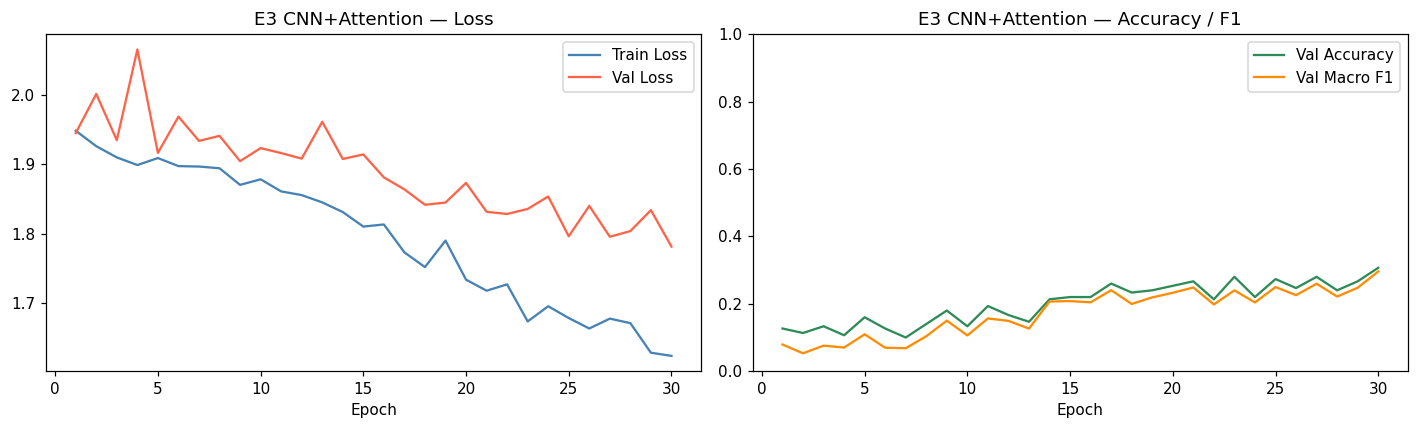

Best val acc : 0.307
Best val F1  : 0.296


In [10]:
cnn_model = CNNAttentionClassifier(in_channels=1, num_classes=len(SWARAS)).to(DEVICE)
print("Parameters:", sum(p.numel() for p in cnn_model.parameters() if p.requires_grad))

cls_history = train_classifier(cnn_model, tr_loader_cls, va_loader_cls, epochs=30, lr=1e-3)

# ── Save ───────────────────────────────────────────────────────────────────
cnn_path = os.path.join(SAVE_DIR, f"{EXPERIMENT}_cnn_attention.pth")
torch.save(cnn_model.state_dict(), cnn_path)
print(f"\nSaved → {cnn_path}")

plot_cls_history(cls_history, title=f"{EXPERIMENT} CNN+Attention")
print(f"Best val acc : {max(cls_history['val_acc']):.3f}")
print(f"Best val F1  : {max(cls_history['val_f1']):.3f}")


## Cell 9 — Classification Report: CNN+Attention

In [11]:
cnn_model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for xb, yb in tqdm(va_loader_cls, desc="Evaluating CNN"):
        preds = cnn_model(xb.to(DEVICE)).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_true.extend(yb.numpy())

print("\n── CNN+Attention Classification Report ──")
print(classification_report(all_true, all_preds, target_names=le.classes_))


Evaluating CNN: 100%|██████████| 10/10 [00:00<00:00, 408.38it/s]


── CNN+Attention Classification Report ──
              precision    recall  f1-score   support

         dha       0.25      0.05      0.08        21
          ga       0.35      0.25      0.29        24
          ma       0.20      0.53      0.29        19
          ni       0.77      0.31      0.44        32
          pa       0.32      0.43      0.36        14
          re       0.26      0.38      0.31        16
          sa       0.29      0.29      0.29        24

    accuracy                           0.31       150
   macro avg       0.35      0.32      0.30       150
weighted avg       0.38      0.31      0.30       150



## Cell 10 — Train RFC Baseline

In [12]:
# ── Collect flat RFC features ──────────────────────────────────────────────
rfc_X = np.array(full_dataset.rfc_X)
rfc_y = np.array([full_dataset.y[i] for i in range(len(full_dataset))])

tr_Xr, va_Xr = rfc_X[tr_idx], rfc_X[va_idx]
tr_yr, va_yr = rfc_y[tr_idx], rfc_y[va_idx]

print(f"RFC feature vector size: {rfc_X.shape[1]}")

rfc = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)
for _ in tqdm([1], desc="Fitting RFC"):
    rfc.fit(tr_Xr, tr_yr)

rfc_preds = rfc.predict(va_Xr)
print(f"RFC val accuracy: {accuracy_score(va_yr, rfc_preds):.3f}")
print(f"RFC val macro F1: {f1_score(va_yr, rfc_preds, average='macro'):.3f}")
print()
print("── RFC Classification Report ──")
print(classification_report(va_yr, rfc_preds, target_names=le.classes_))

rfc_path = os.path.join(SAVE_DIR, f"{EXPERIMENT}_rfc.pkl")
le_path  = os.path.join(SAVE_DIR, f"{EXPERIMENT}_label_encoder.pkl")
with open(rfc_path, "wb") as f: pickle.dump(rfc, f)
with open(le_path,  "wb") as f: pickle.dump(le,  f)
print(f"Saved → {rfc_path}")


RFC feature vector size: 320


Fitting RFC: 100%|██████████| 1/1 [00:02<00:00,  2.12s/it]

RFC val accuracy: 0.267
RFC val macro F1: 0.266

── RFC Classification Report ──
              precision    recall  f1-score   support

         dha       0.32      0.29      0.30        21
          ga       0.39      0.29      0.33        24
          ma       0.20      0.32      0.24        19
          ni       0.30      0.19      0.23        32
          pa       0.17      0.36      0.23        14
          re       0.11      0.12      0.12        16
          sa       0.53      0.33      0.41        24

    accuracy                           0.27       150
   macro avg       0.29      0.27      0.27       150
weighted avg       0.31      0.27      0.27       150

Saved → /content/E3_rfc.pkl


## Cell 11 — Build Segmentation Dataset

In [13]:
seg_dataset = FluteSegmentationDataset(MELODY_CSV, MELODY_AUDIO,
                                        features=FEATURES,
                                        max_len_frames=MAX_LEN_FRAMES)
print(f"Total melody files: {len(seg_dataset)}")

n_seg   = len(seg_dataset)
s_idx   = list(range(n_seg))
random.seed(42)
random.shuffle(s_idx)
s_split = int(0.8 * n_seg)
tr_si, va_si = s_idx[:s_split], s_idx[s_split:]

tr_seg_loader = DataLoader(Subset(seg_dataset, tr_si), batch_size=8, shuffle=True,  num_workers=0)
va_seg_loader = DataLoader(Subset(seg_dataset, va_si), batch_size=8, shuffle=False, num_workers=0)
print(f"Seg train: {len(tr_si)} | Seg val: {len(va_si)}")


Total melody files: 1000
Seg train: 800 | Seg val: 200


## Cell 12 — Train Segmentation CRNN+Attention

Seg model parameters: 1090594


Segmentation training:   4%|▍         | 1/25 [06:00<2:24:02, 360.10s/it]

  Epoch 01/25  train_loss=0.5803  val_loss=0.4617  val_f1=0.509  prec=0.355  rec=0.900


Segmentation training:  20%|██        | 5/25 [06:58<14:51, 44.58s/it]

  Epoch 05/25  train_loss=0.3431  val_loss=0.4093  val_f1=0.554  prec=0.395  rec=0.926


Segmentation training:  40%|████      | 10/25 [08:11<04:43, 18.90s/it]

... (3 outputs left out)

Segmentation training:  80%|████████  | 20/25 [10:38<01:14, 14.92s/it]

  Epoch 20/25  train_loss=0.1547  val_loss=0.2566  val_f1=0.716  prec=0.575  rec=0.951


Segmentation training: 100%|██████████| 25/25 [11:52<00:00, 28.48s/it]


  Epoch 25/25  train_loss=0.1102  val_loss=0.2961  val_f1=0.745  prec=0.616  rec=0.943

Saved → /content/E3_seg_crnn.pth


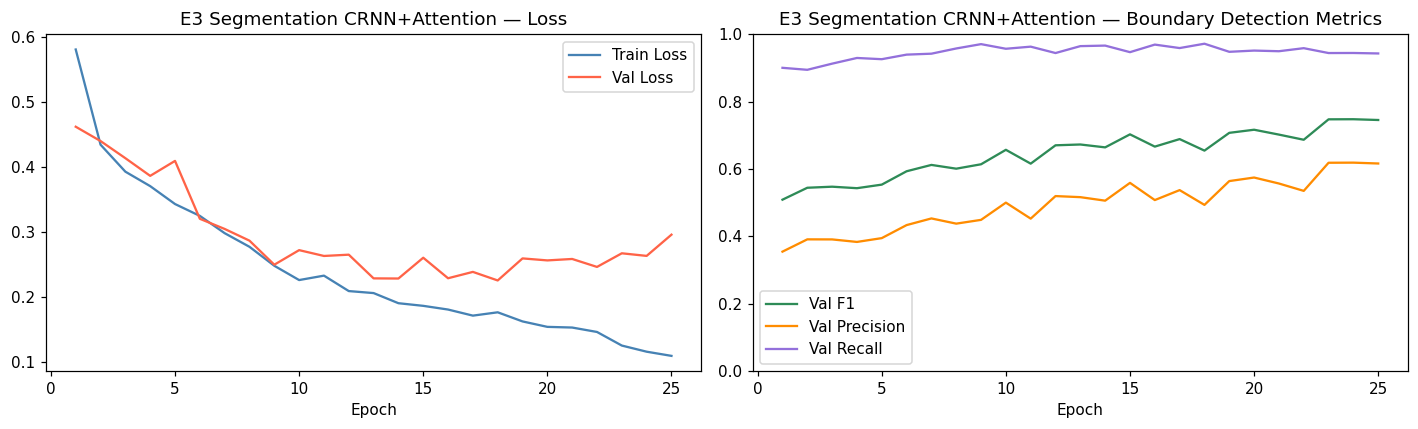

Best val F1        : 0.748
Best val Precision : 0.619
Best val Recall    : 0.972


In [14]:
seg_model = FluteSegmentationCRNN(in_channels=1).to(DEVICE)
print("Seg model parameters:", sum(p.numel() for p in seg_model.parameters() if p.requires_grad))

seg_history = train_segmentation(seg_model, tr_seg_loader, va_seg_loader,
                                  epochs=25, lr=1e-3, pos_weight=15.0)

seg_path = os.path.join(SAVE_DIR, f"{EXPERIMENT}_seg_crnn.pth")
torch.save(seg_model.state_dict(), seg_path)
print(f"\nSaved → {seg_path}")

plot_seg_history(seg_history, title=f"{EXPERIMENT} Segmentation CRNN+Attention")
print(f"Best val F1        : {max(seg_history['val_f1']):.3f}")
print(f"Best val Precision : {max(seg_history['val_precision']):.3f}")
print(f"Best val Recall    : {max(seg_history['val_recall']):.3f}")


## Cell 13 — Full Inference Pipeline

In [15]:
def classify_segment(audio_clip, cnn_m, rfc_m, le_m):
    """Returns (cnn_label, rfc_label) for a single audio clip."""
    tensor   = build_feature_tensor(audio_clip, FEATURES, fixed_frames=FIXED_FRAMES)
    rfc_feat = get_rfc_features(tensor)

    cnn_m.eval()
    with torch.no_grad():
        x    = torch.tensor(tensor, dtype=torch.float32).unsqueeze(0).to(DEVICE)
        idx_ = cnn_m(x).argmax(1).item()
    cnn_lbl = le_m.inverse_transform([idx_])[0]
    rfc_lbl = le_m.inverse_transform([rfc_m.predict([rfc_feat])[0]])[0]
    return cnn_lbl, rfc_lbl


def run_pipeline(audio_path,
                 threshold      = 0.5,
                 min_gap_sec    = 0.15,
                 min_seg_dur    = 0.20,
                 end_margin     = 0.30):
    """
    Full inference pipeline.
    Uses models already in memory: seg_model, cnn_model, rfc, le
    """
    # ── Load audio ─────────────────────────────────────────────────────────
    y, _     = librosa.load(audio_path, sr=SR)
    duration = len(y) / SR

    # ── Build features for segmentation (no truncation — full audio) ───────
    tensor  = build_feature_tensor(y, FEATURES)            # [C, N_MELS, T]
    # Sliding window if longer than MAX_LEN_FRAMES
    T_total = tensor.shape[2]
    if T_total <= MAX_LEN_FRAMES:
        inp    = torch.tensor(tensor, dtype=torch.float32).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            raw_logits = seg_model(inp).squeeze(0).cpu().numpy()
        preds_full = torch.sigmoid(torch.tensor(raw_logits)).numpy()
    else:
        preds_full = np.zeros(T_total, dtype=np.float32)
        step  = MAX_LEN_FRAMES // 2
        start = 0
        while start < T_total:
            end   = min(start + MAX_LEN_FRAMES, T_total)
            chunk = tensor[:, :, start:end]
            if chunk.shape[2] < MAX_LEN_FRAMES:
                chunk = np.pad(chunk, ((0,0),(0,0),(0, MAX_LEN_FRAMES-chunk.shape[2])))
            inp   = torch.tensor(chunk, dtype=torch.float32).unsqueeze(0).to(DEVICE)
            with torch.no_grad():
                logits = seg_model(inp).squeeze(0).cpu().numpy()
            prob   = torch.sigmoid(torch.tensor(logits)).numpy()
            actual = end - start
            preds_full[start:end] = np.maximum(preds_full[start:end], prob[:actual])
            start += step

    time_axis = np.arange(T_total) * (HOP_LENGTH / SR)

    # ── Collect & suppress boundaries ──────────────────────────────────────
    raw_times  = time_axis[preds_full > threshold]
    boundaries = []
    if len(raw_times):
        last = raw_times[0]; boundaries.append(last)
        for t in raw_times[1:]:
            if t - last > min_gap_sec:
                boundaries.append(t); last = t

    if boundaries and (duration - boundaries[-1]) <= end_margin:
        print(f"  [Edge] Dropping last boundary at {boundaries[-1]:.3f}s")
        boundaries = boundaries[:-1]

    print(f"Boundaries detected: {len(boundaries)}")

    # ── Build segment list ──────────────────────────────────────────────────
    cuts = [0.0] + boundaries + [duration]
    segments = []
    for i in range(len(cuts)-1):
        t0, t1 = cuts[i], cuts[i+1]
        if t1 - t0 >= min_seg_dur:
            segments.append((t0, t1))
        else:
            print(f"  [Edge] Dropping short segment [{t0:.3f}–{t1:.3f}]s")

    print(f"Classifying {len(segments)} segments...")

    # ── Classify ───────────────────────────────────────────────────────────
    cnn_seq, rfc_seq = [], []
    for i, (t0, t1) in enumerate(tqdm(segments, desc="Classifying segments")):
        clip    = y[int(t0*SR):int(t1*SR)]
        c, r    = classify_segment(clip, cnn_model, rfc, le)
        cnn_seq.append(c); rfc_seq.append(r)
        print(f"  Seg {i+1:02d}  [{t0:.3f}s – {t1:.3f}s]  CNN={c}  RFC={r}")

    print(f"\nCNN+Attention : {' → '.join(cnn_seq)}")
    print(f"RFC           : {' → '.join(rfc_seq)}")

    # ── Visualisation ──────────────────────────────────────────────────────
    # Row 1: Mel spectrogram (always shown regardless of experiment)
    mel_spec = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT,
                                              hop_length=HOP_LENGTH, n_mels=N_MELS)
    log_mel_vis = librosa.power_to_db(mel_spec, ref=np.max)

    fig, axes = plt.subplots(4, 1, figsize=(16, 14))
    fig.suptitle(f"{EXPERIMENT} — {os.path.basename(audio_path)}", fontsize=13, fontweight='bold')

    # Mel
    img = librosa.display.specshow(log_mel_vis, sr=SR, hop_length=HOP_LENGTH,
                                   x_axis='time', y_axis='mel',
                                   cmap='magma', ax=axes[0])
    fig.colorbar(img, ax=axes[0], format='%+2.0f dB')
    axes[0].set_title("Log-Mel Spectrogram")
    for t0, _ in segments:
        axes[0].axvline(t0, color='cyan', lw=1.5, alpha=0.85)

    # Boundary probability
    axes[1].plot(time_axis, preds_full, color='crimson', lw=1.5, label='Boundary prob')
    axes[1].axhline(threshold, color='gray', ls='--', lw=1, label=f'Threshold={threshold}')
    for t0, _ in segments:
        axes[1].axvline(t0, color='darkgreen', ls='--', lw=1.2)
    axes[1].fill_between(time_axis, preds_full,
                         where=(preds_full >= threshold),
                         color='red', alpha=0.25)
    axes[1].set_ylim(-0.05, 1.05); axes[1].set_xlim(0, duration)
    axes[1].set_title("Boundary Confidence"); axes[1].set_ylabel("Probability")
    axes[1].legend(loc='upper right')

    # CNN swara strip
    cmap_colors = plt.cm.Set2(np.linspace(0, 1, len(SWARAS)))
    color_map   = {s: cmap_colors[i] for i, s in enumerate(SWARAS)}
    axes[2].set_xlim(0, duration); axes[2].set_ylim(0, 1)
    for (t0, t1), lbl in zip(segments, cnn_seq):
        axes[2].barh(0.5, t1-t0, left=t0, height=0.6,
                     color=color_map.get(lbl, 'gray'), alpha=0.85, edgecolor='white', linewidth=0.8)
        if t1-t0 > 0.15:
            axes[2].text((t0+t1)/2, 0.5, lbl, ha='center', va='center',
                         fontsize=9, fontweight='bold', color='white')
    axes[2].set_title("CNN+Attention — Predicted Swara Sequence")
    axes[2].set_yticks([])
    legend_patches = [mpatches.Patch(color=color_map[s], label=s) for s in SWARAS]
    axes[2].legend(handles=legend_patches, loc='upper right', ncol=7, fontsize=8)

    # RFC swara strip
    axes[3].set_xlim(0, duration); axes[3].set_ylim(0, 1)
    for (t0, t1), lbl in zip(segments, rfc_seq):
        axes[3].barh(0.5, t1-t0, left=t0, height=0.6,
                     color=color_map.get(lbl, 'gray'), alpha=0.85, edgecolor='white', linewidth=0.8)
        if t1-t0 > 0.15:
            axes[3].text((t0+t1)/2, 0.5, lbl, ha='center', va='center',
                         fontsize=9, fontweight='bold', color='white')
    axes[3].set_title("RFC — Predicted Swara Sequence")
    axes[3].set_xlabel("Time (s)"); axes[3].set_yticks([])
    axes[3].legend(handles=legend_patches, loc='upper right', ncol=7, fontsize=8)

    plt.tight_layout()
    vis_path = os.path.join(SAVE_DIR, f"{EXPERIMENT}_pipeline_output.png")
    plt.savefig(vis_path, dpi=120, bbox_inches='tight')
    plt.show()
    print(f"Saved visualization → {vis_path}")

    return cnn_seq, rfc_seq, segments


print("Inference pipeline ready.")


Inference pipeline ready.


## Cell 14 — Run on Test WAV Files

Upload one or more test flute .wav files:


Saving test1.wav to test1.wav
Saving test2.wav to test2.wav
Saving test3.wav to test3.wav
Saving test4.wav to test4.wav
Saving test5.wav to test5.wav
Saving test6.wav to test6.wav
Saving test7.wav to test7.wav
Saving test8.wav to test8.wav
Saving test9.wav to test9.wav
Saving test10.wav to test10.wav
Saving test11.wav to test11.wav
Saving test12.wav to test12.wav
Saving test13.wav to test13.wav
Saving test14.wav to test14.wav
Saving test15.wav to test15.wav
Saving test16.wav to test16.wav
Saving test17.wav to test17.wav
Saving test18.wav to test18.wav
Saving test19.wav to test19.wav


Processing files:   0%|          | 0/19 [00:00<?, ?it/s]


Processing: test1.wav
Boundaries detected: 13
  [Edge] Dropping short segment [2.090–2.252]s
Classifying 13 segments...



Classifying segments:   0%|          | 0/13 [00:00<?, ?it/s]


  Seg 01  [0.000s – 1.161s]  CNN=pa  RFC=sa


... (8 outputs left out)


Classifying segments:  85%|████████▍ | 11/13 [00:00<00:00, 12.45it/s]

  Seg 11  [9.915s – 10.588s]  CNN=ni  RFC=ni
  Seg 12  [10.588s – 11.564s]  CNN=re  RFC=re



Classifying segments: 100%|██████████| 13/13 [00:01<00:00, 12.37it/s]

  Seg 13  [11.564s – 11.891s]  CNN=sa  RFC=ga

CNN+Attention : pa → re → ma → sa → sa → re → pa → pa → ni → ni → ni → re → sa
RFC           : sa → re → dha → sa → dha → ga → sa → sa → ni → ma → ni → re → ga


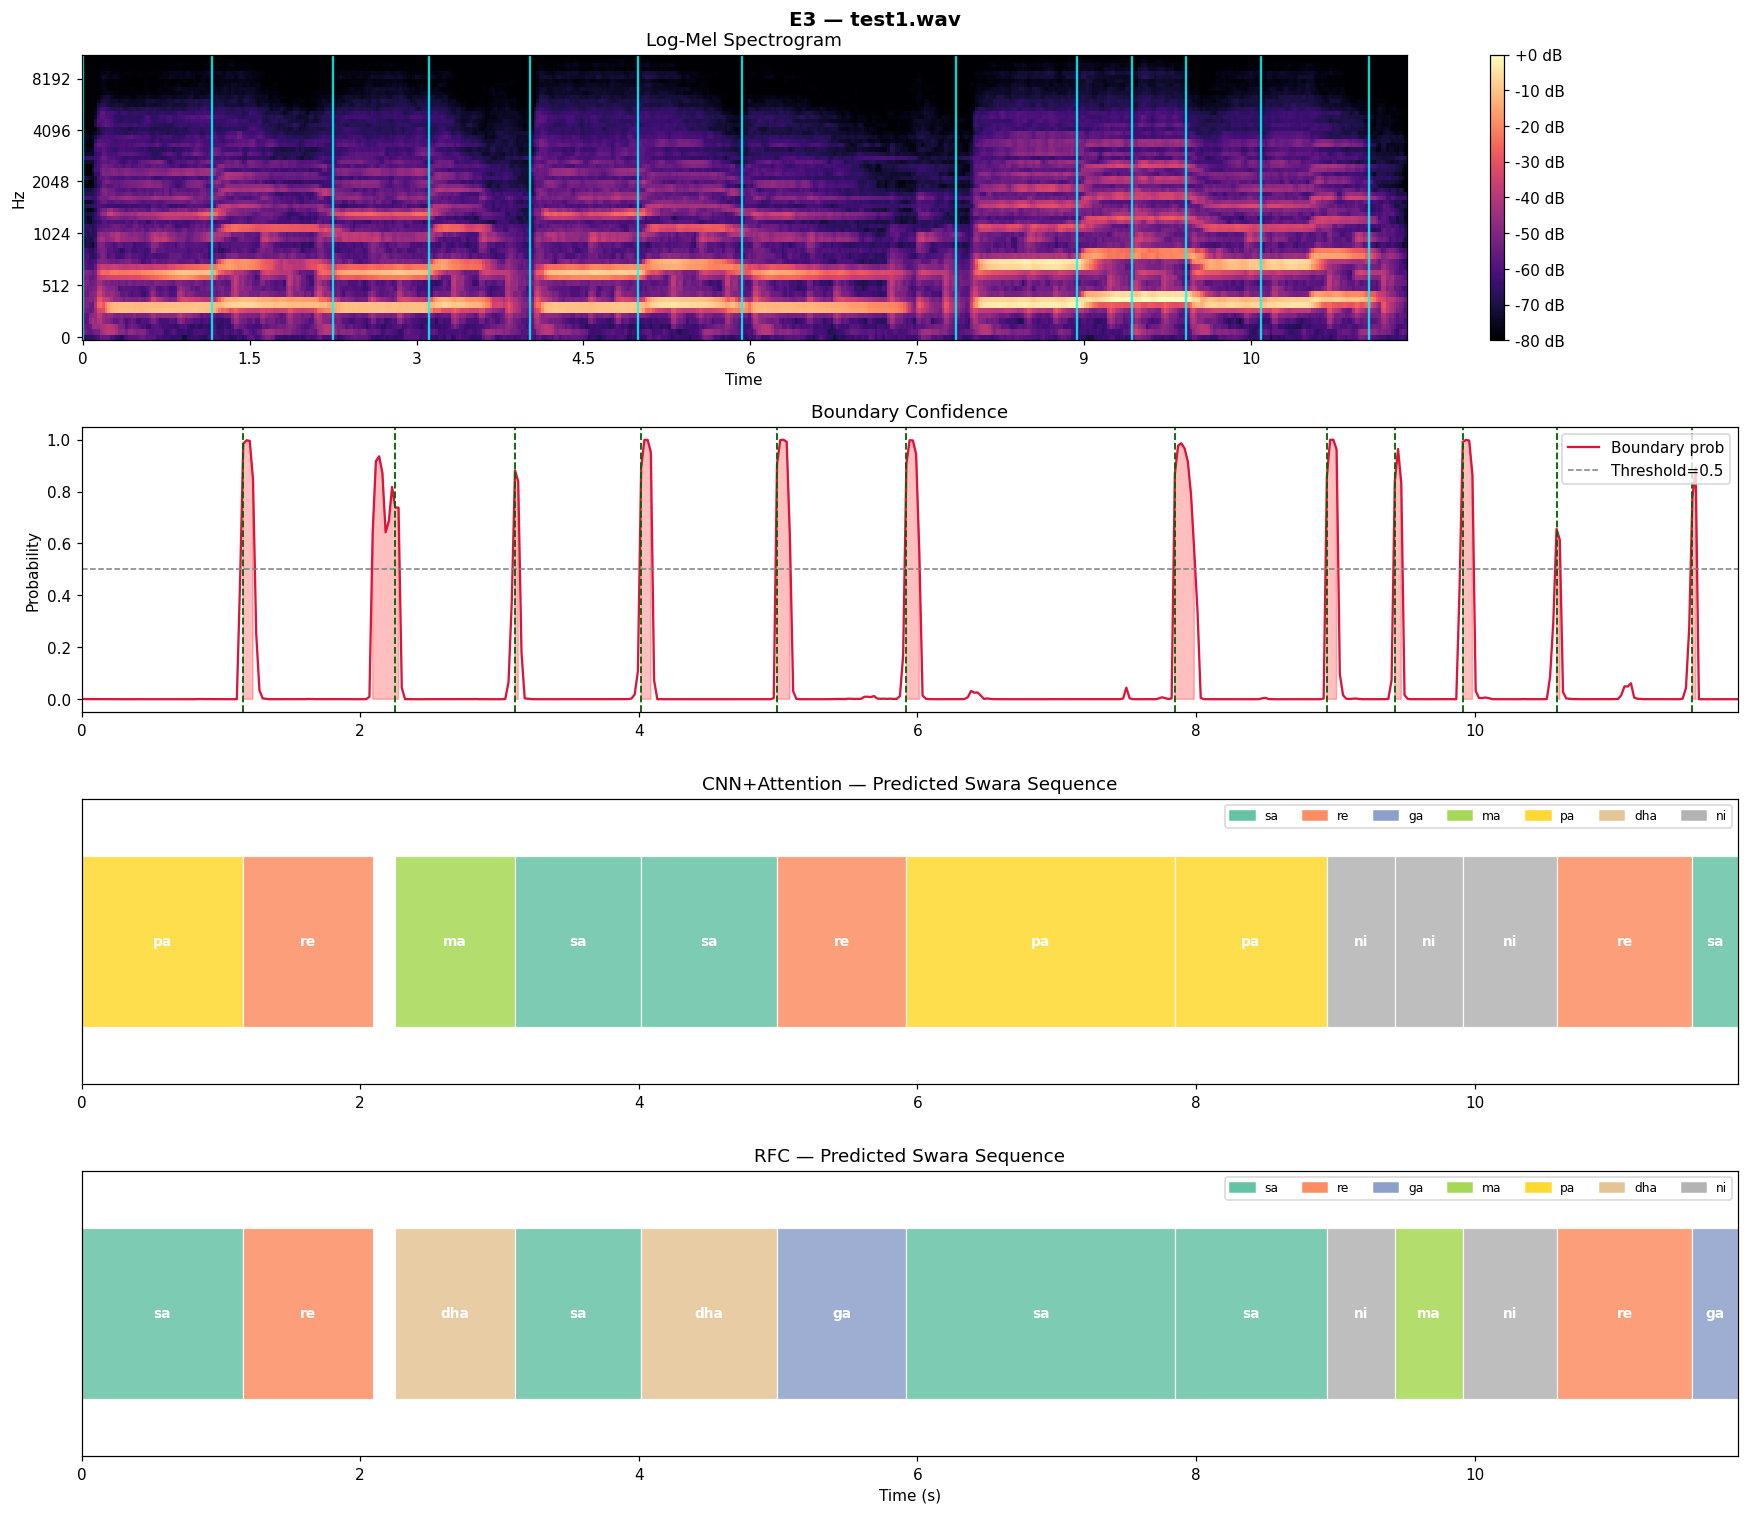

Processing files:   5%|▌         | 1/19 [00:02<00:48,  2.68s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test2.wav
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 14.46it/s]

  Seg 01  [0.000s – 0.441s]  CNN=sa  RFC=pa
  Seg 02  [0.441s – 0.813s]  CNN=ga  RFC=ga
  Seg 03  [0.813s – 1.416s]  CNN=sa  RFC=sa



Classifying segments:  57%|█████▋    | 4/7 [00:00<00:00, 12.96it/s]

  Seg 04  [1.416s – 1.881s]  CNN=sa  RFC=pa
  Seg 05  [1.881s – 2.345s]  CNN=ga  RFC=ni



Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00, 13.10it/s]

  Seg 06  [2.345s – 2.879s]  CNN=ni  RFC=ni


Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 13.03it/s]

  Seg 07  [2.879s – 3.367s]  CNN=sa  RFC=ma

CNN+Attention : sa → ga → sa → sa → ga → ni → sa
RFC           : pa → ga → sa → pa → ni → ni → ma


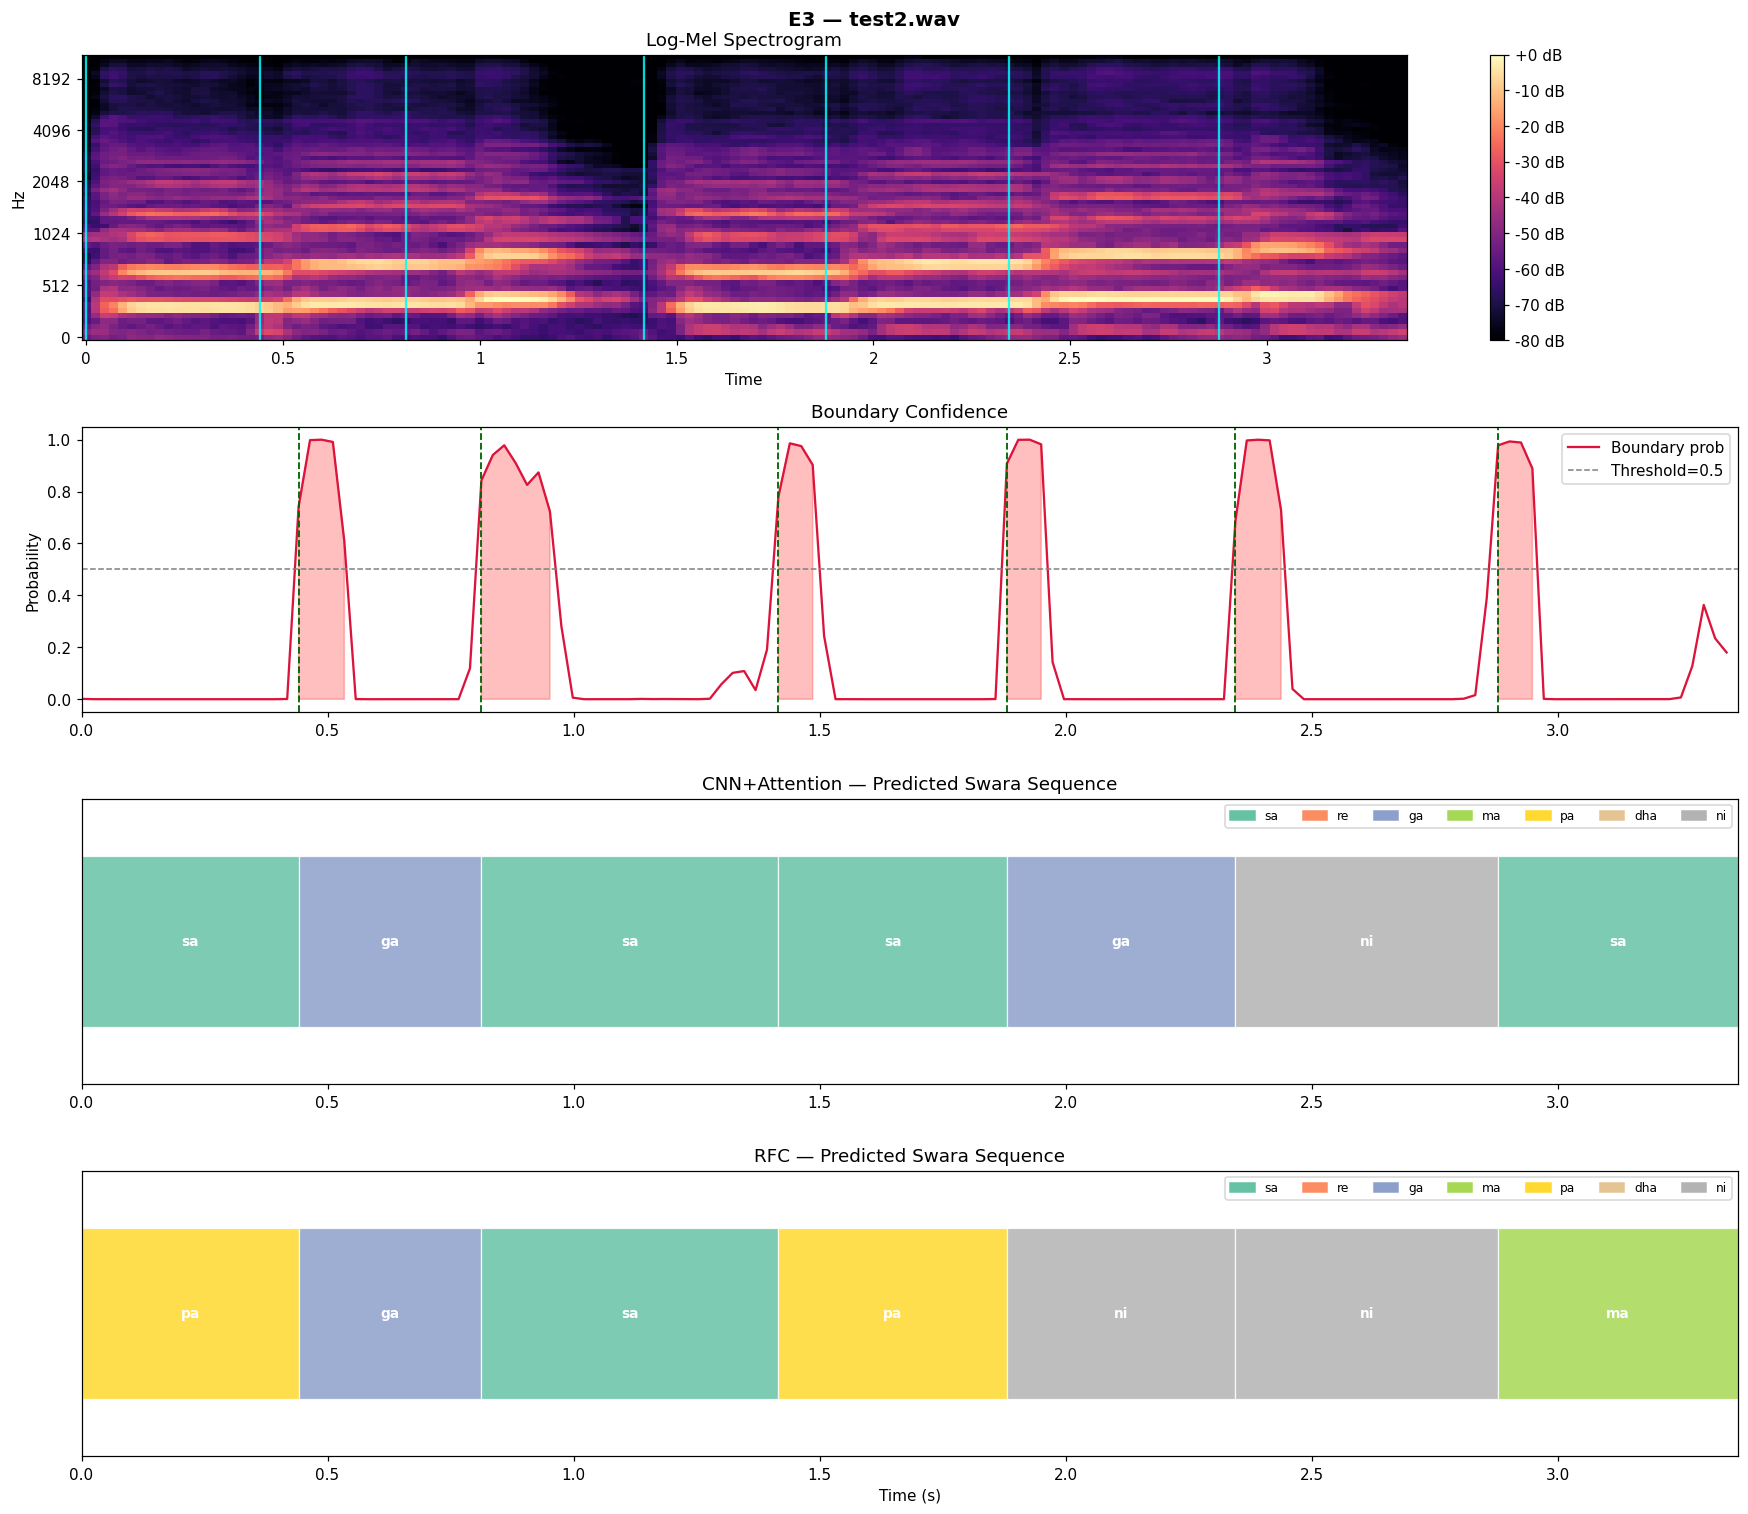

Processing files:  11%|█         | 2/19 [00:04<00:38,  2.26s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test3.wav
Boundaries detected: 5
Classifying 6 segments...



Classifying segments:  33%|███▎      | 2/6 [00:00<00:00, 15.76it/s]

  Seg 01  [0.000s – 0.441s]  CNN=sa  RFC=pa
  Seg 02  [0.441s – 0.906s]  CNN=ga  RFC=ni
  Seg 03  [0.906s – 1.904s]  CNN=pa  RFC=pa



Classifying segments:  67%|██████▋   | 4/6 [00:00<00:00, 14.14it/s]

  Seg 04  [1.904s – 2.368s]  CNN=ma  RFC=ni
  Seg 05  [2.368s – 2.856s]  CNN=re  RFC=ga



Classifying segments: 100%|██████████| 6/6 [00:00<00:00, 13.84it/s]

  Seg 06  [2.856s – 3.386s]  CNN=ma  RFC=ma

CNN+Attention : sa → ga → pa → ma → re → ma
RFC           : pa → ni → pa → ni → ga → ma


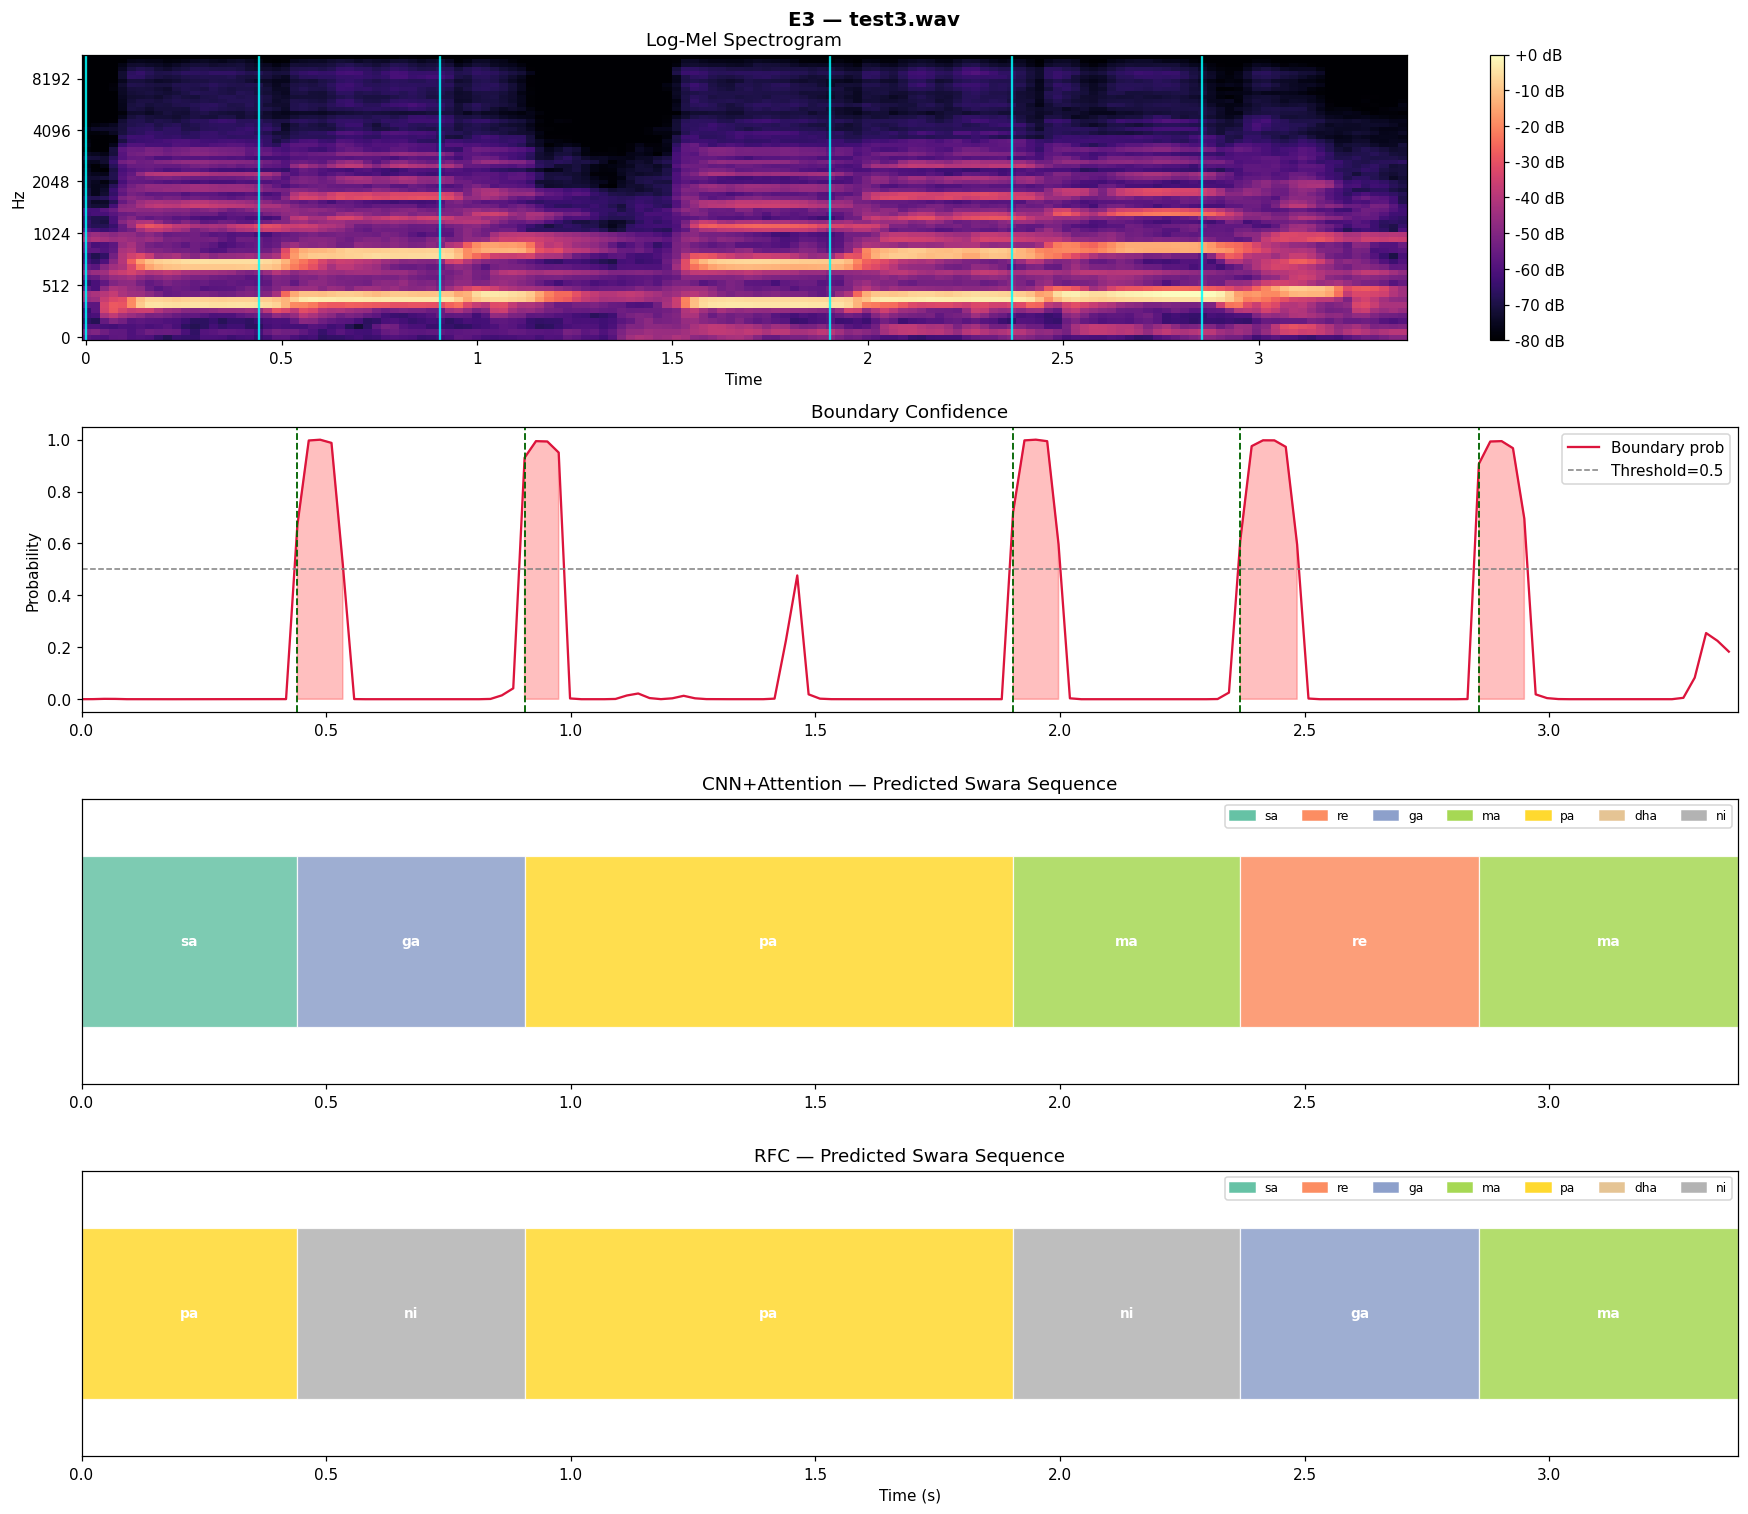

Processing files:  16%|█▌        | 3/19 [00:06<00:33,  2.08s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test4.wav
Boundaries detected: 5
Classifying 6 segments...



Classifying segments:  33%|███▎      | 2/6 [00:00<00:00, 13.62it/s]

  Seg 01  [0.000s – 0.511s]  CNN=sa  RFC=sa
  Seg 02  [0.511s – 1.486s]  CNN=sa  RFC=sa
  Seg 03  [1.486s – 1.927s]  CNN=sa  RFC=sa



Classifying segments:  67%|██████▋   | 4/6 [00:00<00:00, 13.36it/s]

  Seg 04  [1.927s – 2.461s]  CNN=re  RFC=re
  Seg 05  [2.461s – 2.879s]  CNN=ma  RFC=re



Classifying segments: 100%|██████████| 6/6 [00:00<00:00, 13.59it/s]

  Seg 06  [2.879s – 3.437s]  CNN=sa  RFC=dha

CNN+Attention : sa → sa → sa → re → ma → sa
RFC           : sa → sa → sa → re → re → dha


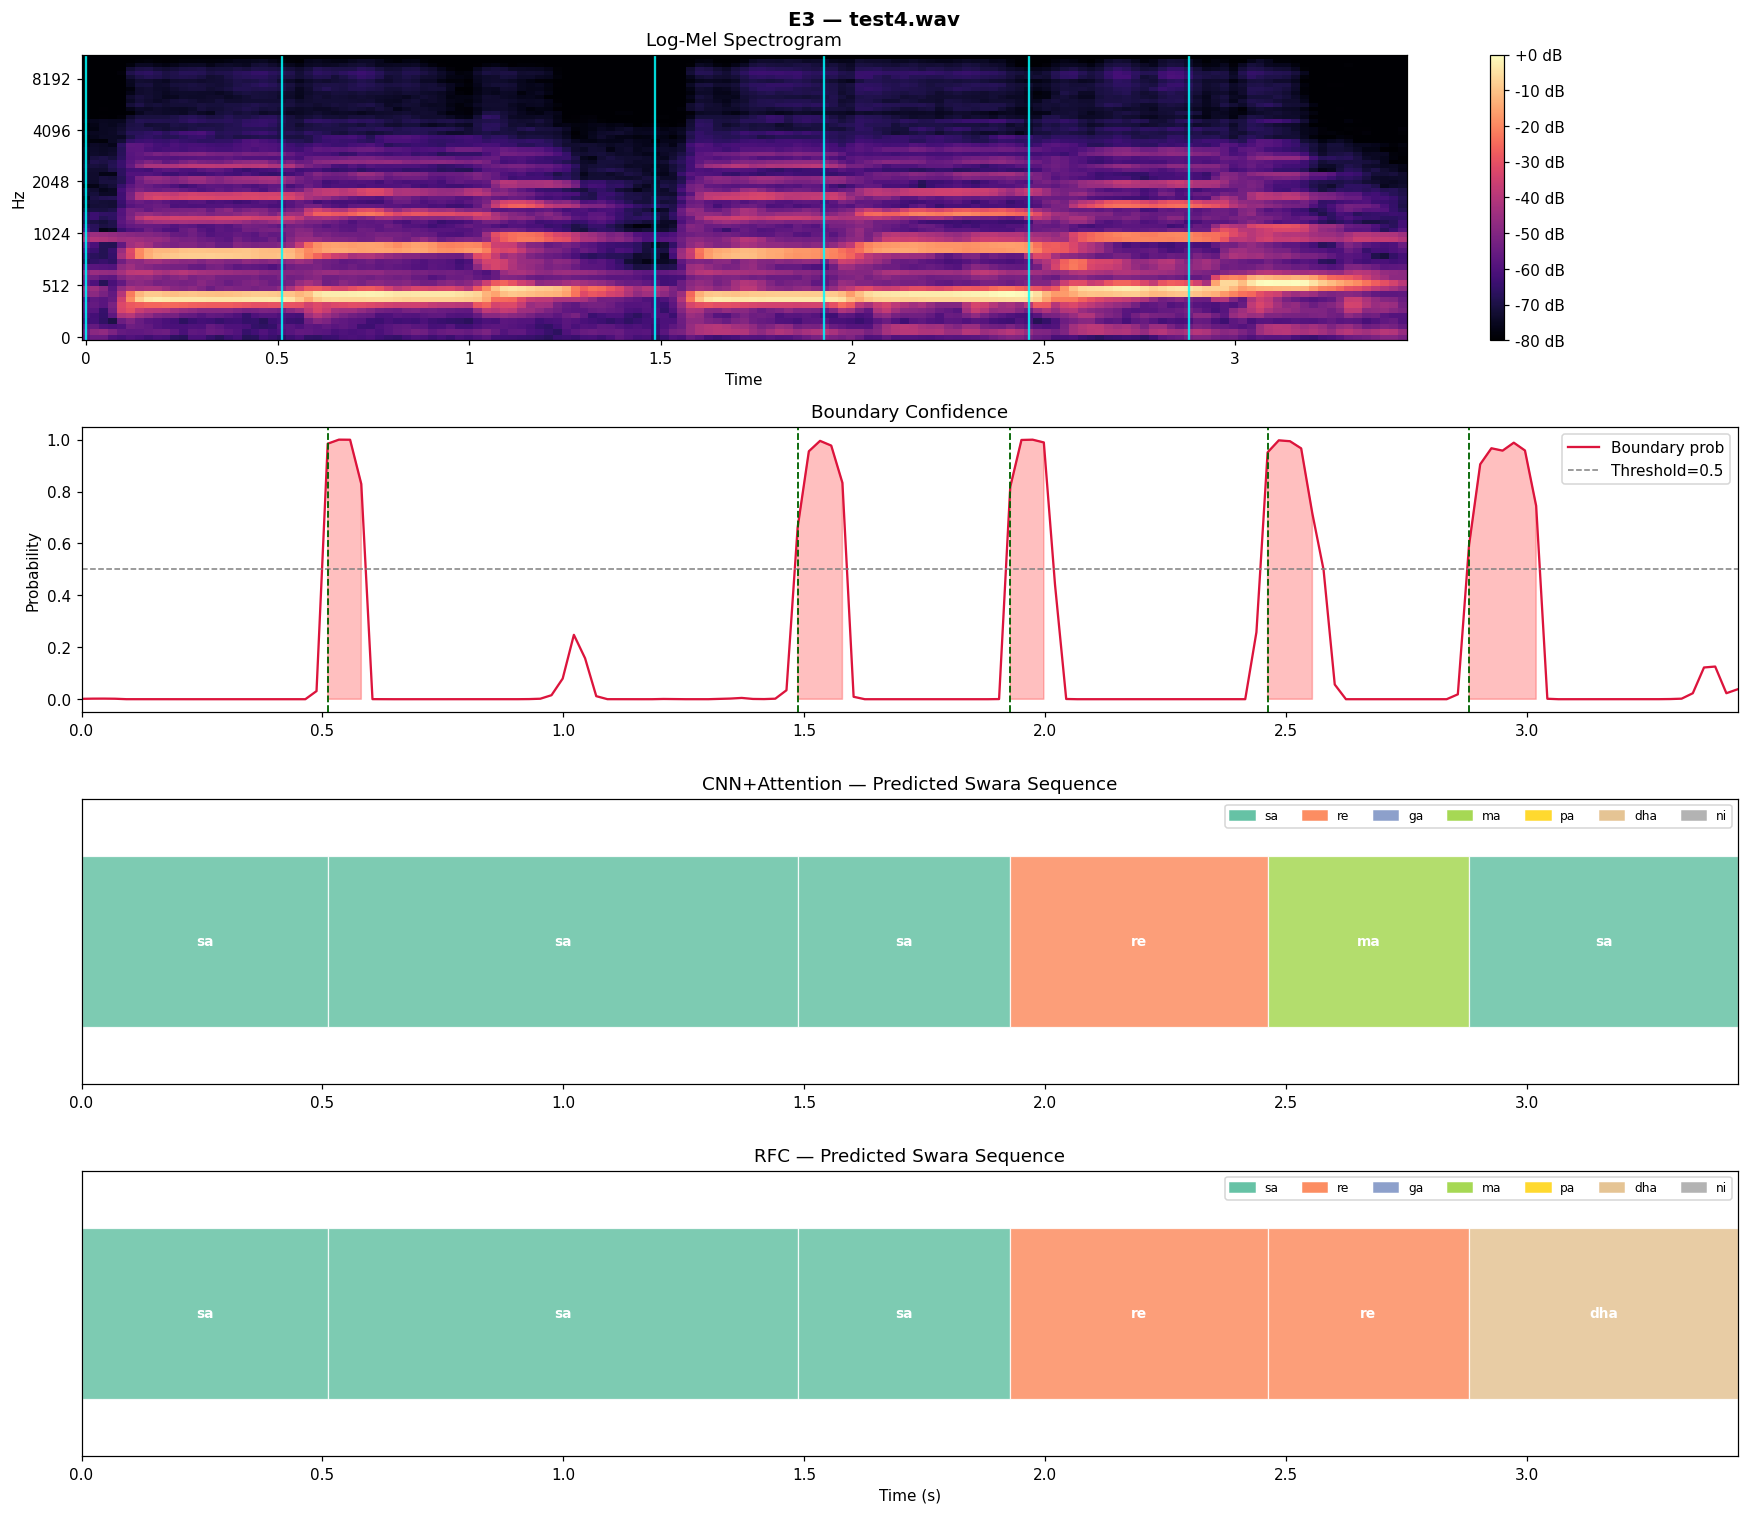

Processing files:  21%|██        | 4/19 [00:08<00:29,  1.98s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test5.wav
  [Edge] Dropping last boundary at 3.367s
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 15.43it/s]

  Seg 01  [0.000s – 0.557s]  CNN=sa  RFC=sa
  Seg 02  [0.557s – 0.975s]  CNN=ni  RFC=ga



Classifying segments:  57%|█████▋    | 4/7 [00:00<00:00, 15.28it/s]

  Seg 03  [0.975s – 1.533s]  CNN=sa  RFC=pa
  Seg 04  [1.533s – 1.950s]  CNN=sa  RFC=sa


  Seg 05  [1.950s – 2.485s]  CNN=ma  RFC=ni



Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 14.19it/s]

  Seg 06  [2.485s – 2.926s]  CNN=ma  RFC=ga
  Seg 07  [2.926s – 3.428s]  CNN=ma  RFC=dha

CNN+Attention : sa → ni → sa → sa → ma → ma → ma
RFC           : sa → ga → pa → sa → ni → ga → dha


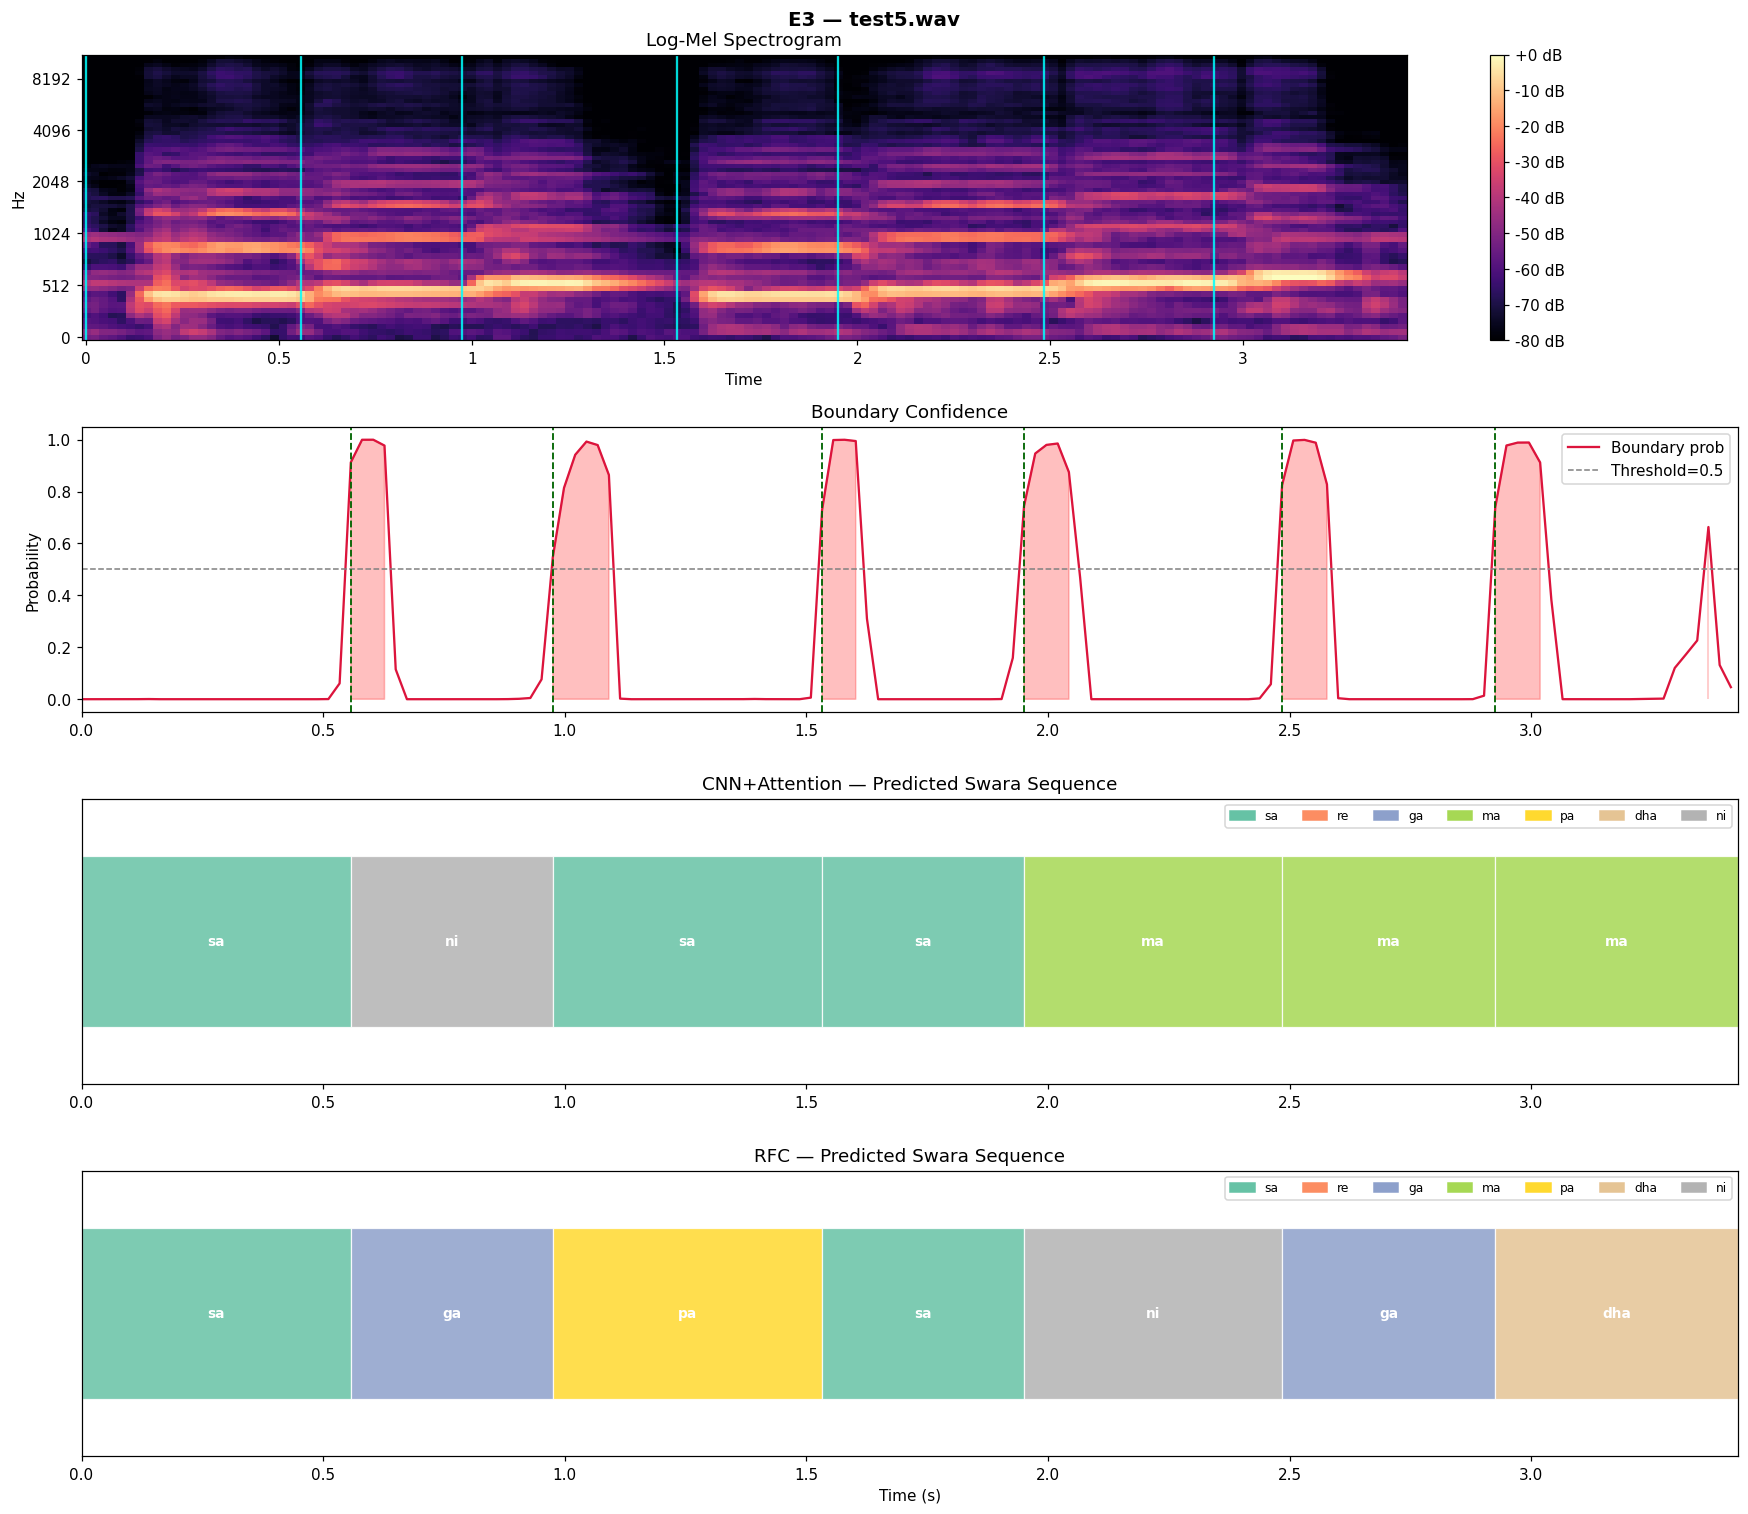

Processing files:  26%|██▋       | 5/19 [00:11<00:31,  2.23s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test6.wav
Boundaries detected: 7
  [Edge] Dropping short segment [0.000–0.116]s
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 11.70it/s]

  Seg 01  [0.116s – 0.511s]  CNN=sa  RFC=pa
  Seg 02  [0.511s – 0.952s]  CNN=ma  RFC=ga



Classifying segments:  57%|█████▋    | 4/7 [00:00<00:00, 10.94it/s]

  Seg 03  [0.952s – 1.463s]  CNN=ma  RFC=sa
  Seg 04  [1.463s – 1.974s]  CNN=sa  RFC=sa
  Seg 05  [1.974s – 2.392s]  CNN=ma  RFC=ni



Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 11.72it/s]

  Seg 06  [2.392s – 2.949s]  CNN=ma  RFC=ni
  Seg 07  [2.949s – 3.456s]  CNN=ma  RFC=pa

CNN+Attention : sa → ma → ma → sa → ma → ma → ma
RFC           : pa → ga → sa → sa → ni → ni → pa


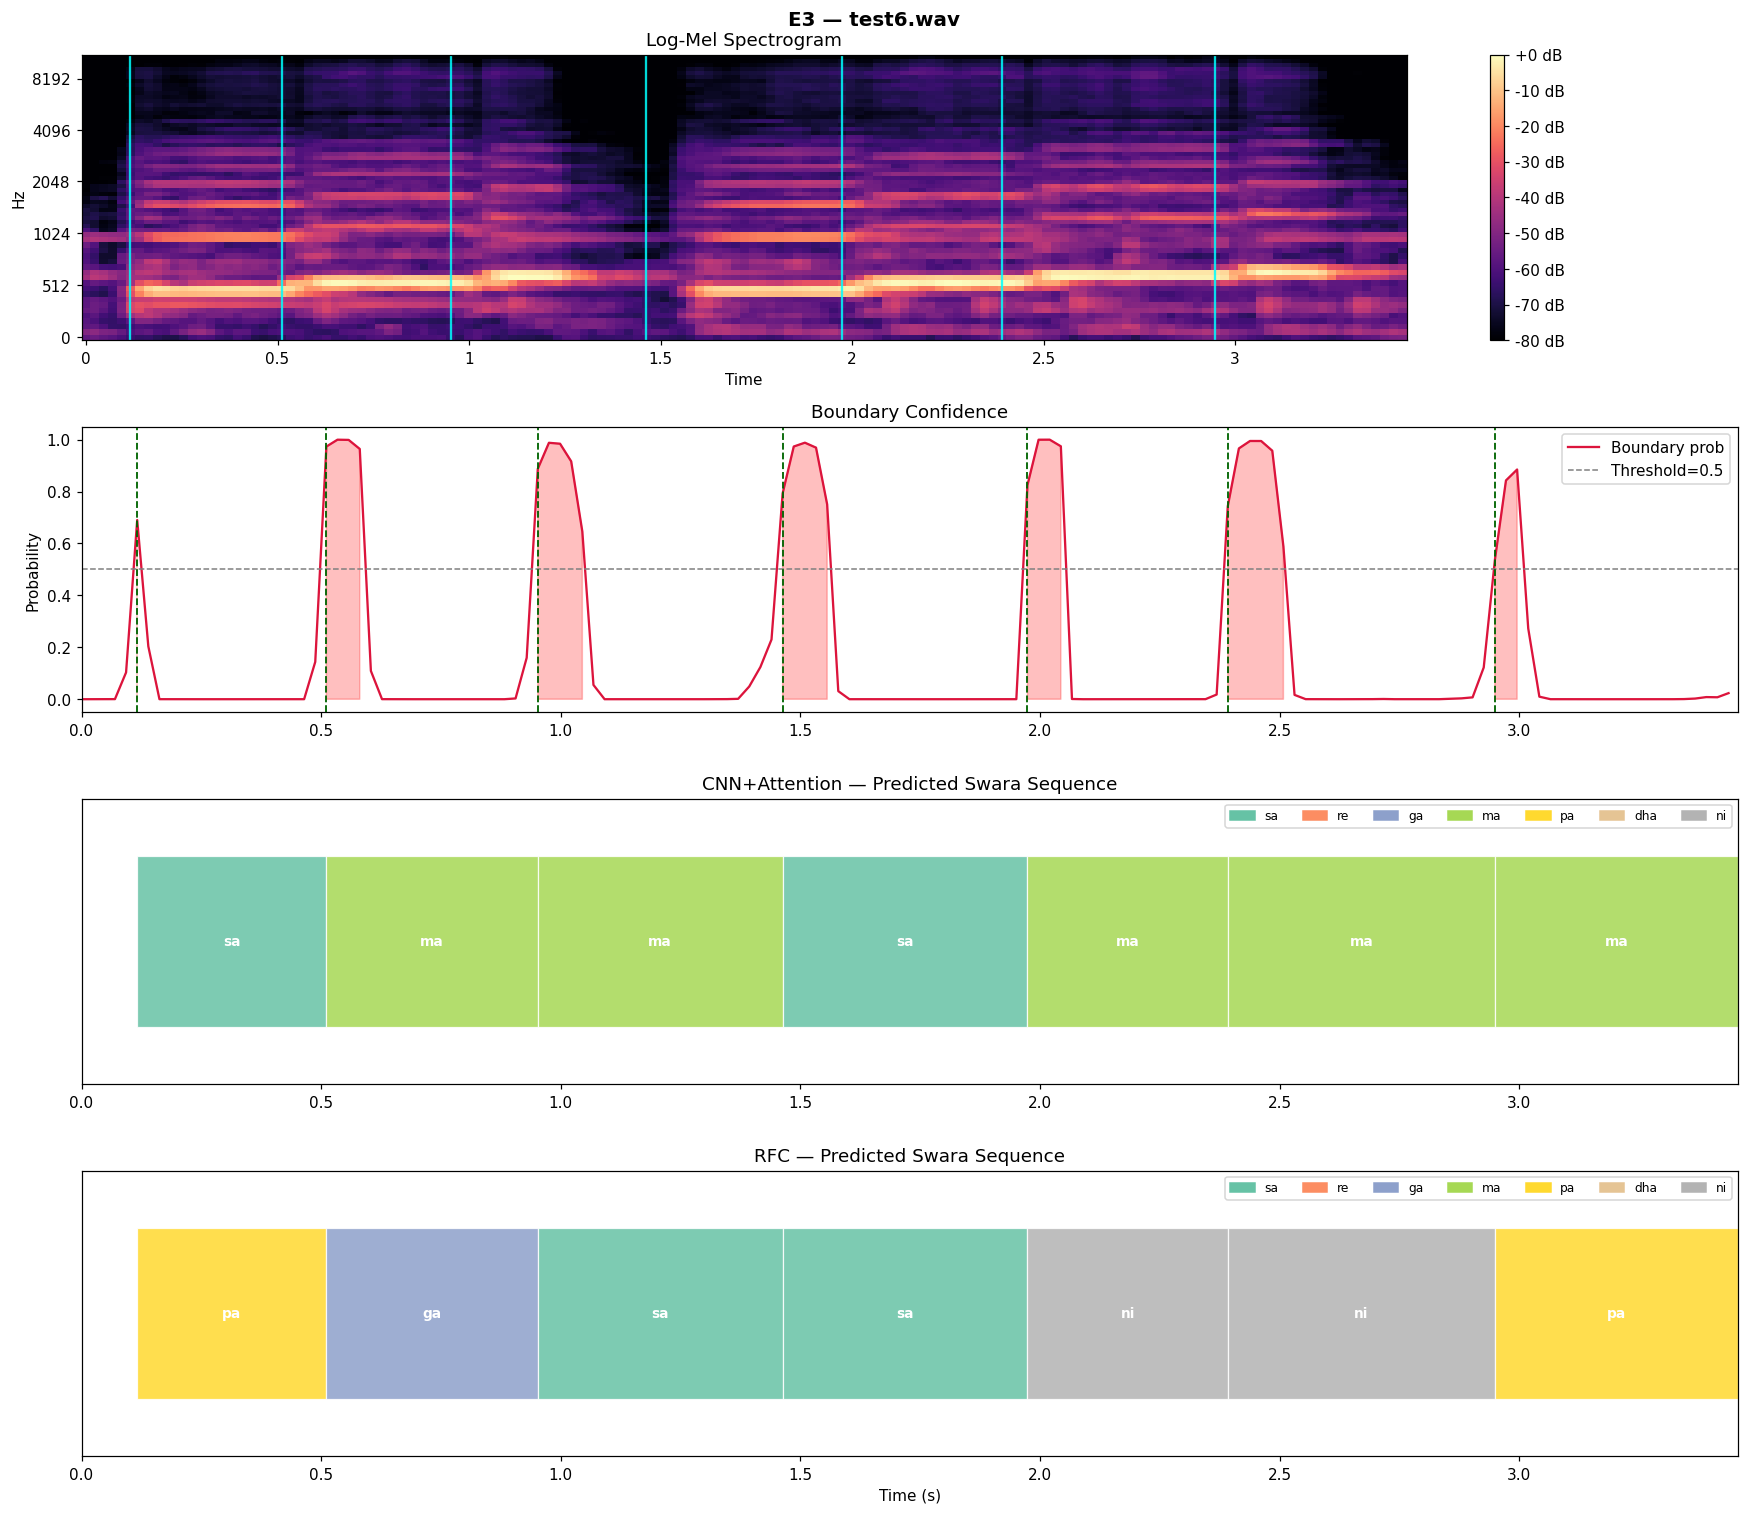

Processing files:  32%|███▏      | 6/19 [00:13<00:30,  2.34s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test7.wav
Boundaries detected: 5
Classifying 6 segments...



Classifying segments:  33%|███▎      | 2/6 [00:00<00:00, 16.33it/s]

  Seg 01  [0.000s – 0.488s]  CNN=ma  RFC=sa
  Seg 02  [0.488s – 1.463s]  CNN=ma  RFC=sa



Classifying segments:  67%|██████▋   | 4/6 [00:00<00:00, 15.48it/s]

  Seg 03  [1.463s – 1.881s]  CNN=sa  RFC=sa
  Seg 04  [1.881s – 2.392s]  CNN=ma  RFC=dha
  Seg 05  [2.392s – 2.902s]  CNN=ni  RFC=sa



Classifying segments: 100%|██████████| 6/6 [00:00<00:00, 15.11it/s]


  Seg 06  [2.902s – 3.400s]  CNN=ma  RFC=pa

CNN+Attention : ma → ma → sa → ma → ni → ma
RFC           : sa → sa → sa → dha → sa → pa


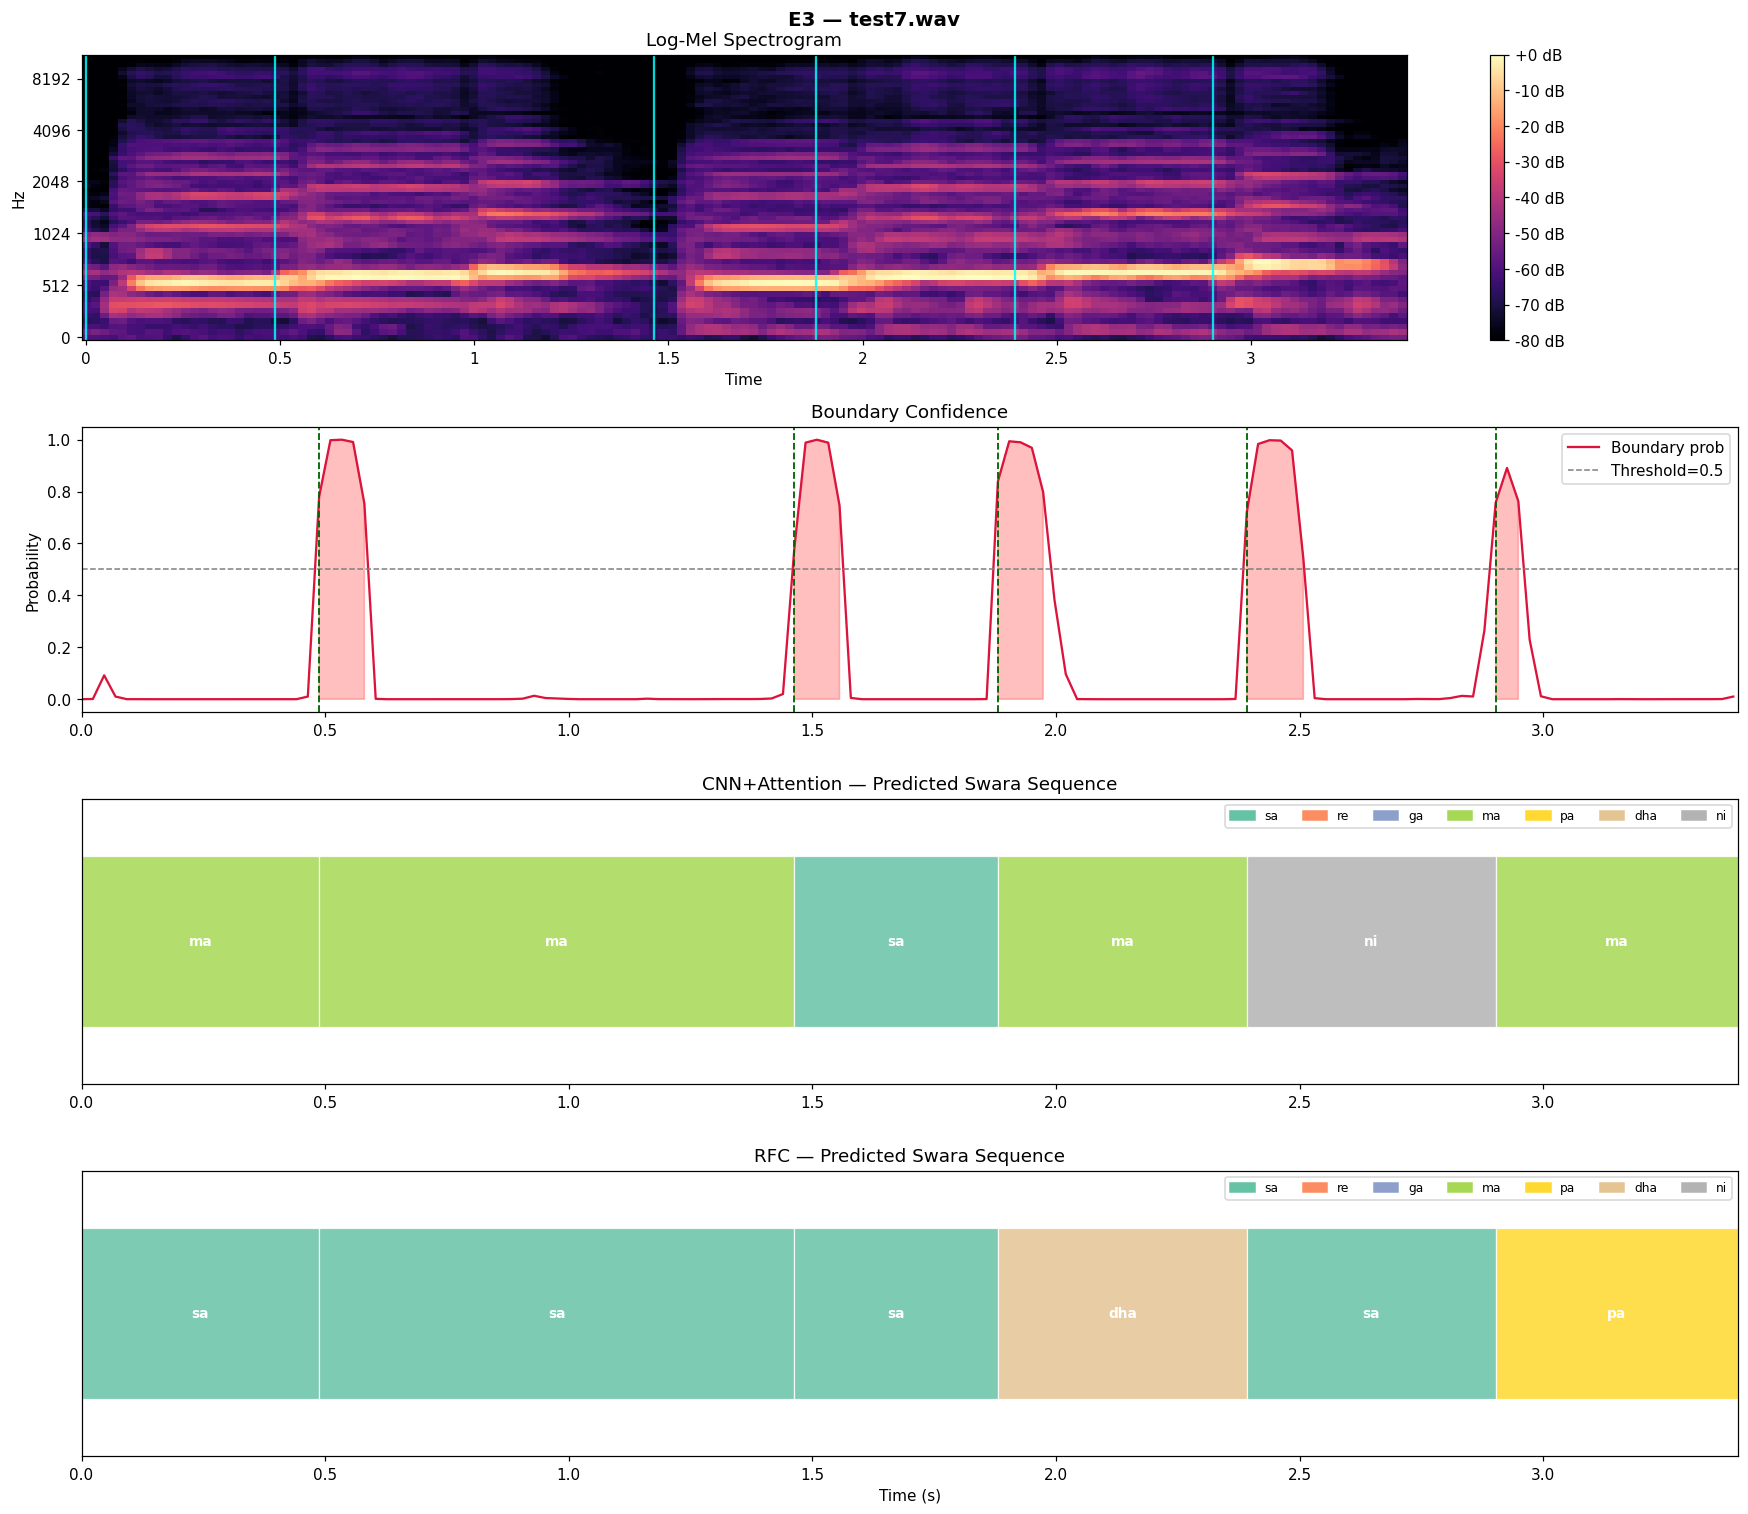

Processing files:  37%|███▋      | 7/19 [00:15<00:26,  2.18s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test8.wav
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 14.20it/s]

  Seg 01  [0.000s – 0.488s]  CNN=sa  RFC=sa
  Seg 02  [0.488s – 0.998s]  CNN=ga  RFC=ma
  Seg 03  [0.998s – 1.486s]  CNN=ma  RFC=dha
  Seg 04  [1.486s – 1.904s]  CNN=sa  RFC=sa



Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00, 15.93it/s]

  Seg 05  [1.904s – 2.415s]  CNN=ma  RFC=sa
  Seg 06  [2.415s – 2.879s]  CNN=ma  RFC=ga


Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 15.73it/s]


  Seg 07  [2.879s – 3.428s]  CNN=ma  RFC=ma

CNN+Attention : sa → ga → ma → sa → ma → ma → ma
RFC           : sa → ma → dha → sa → sa → ga → ma


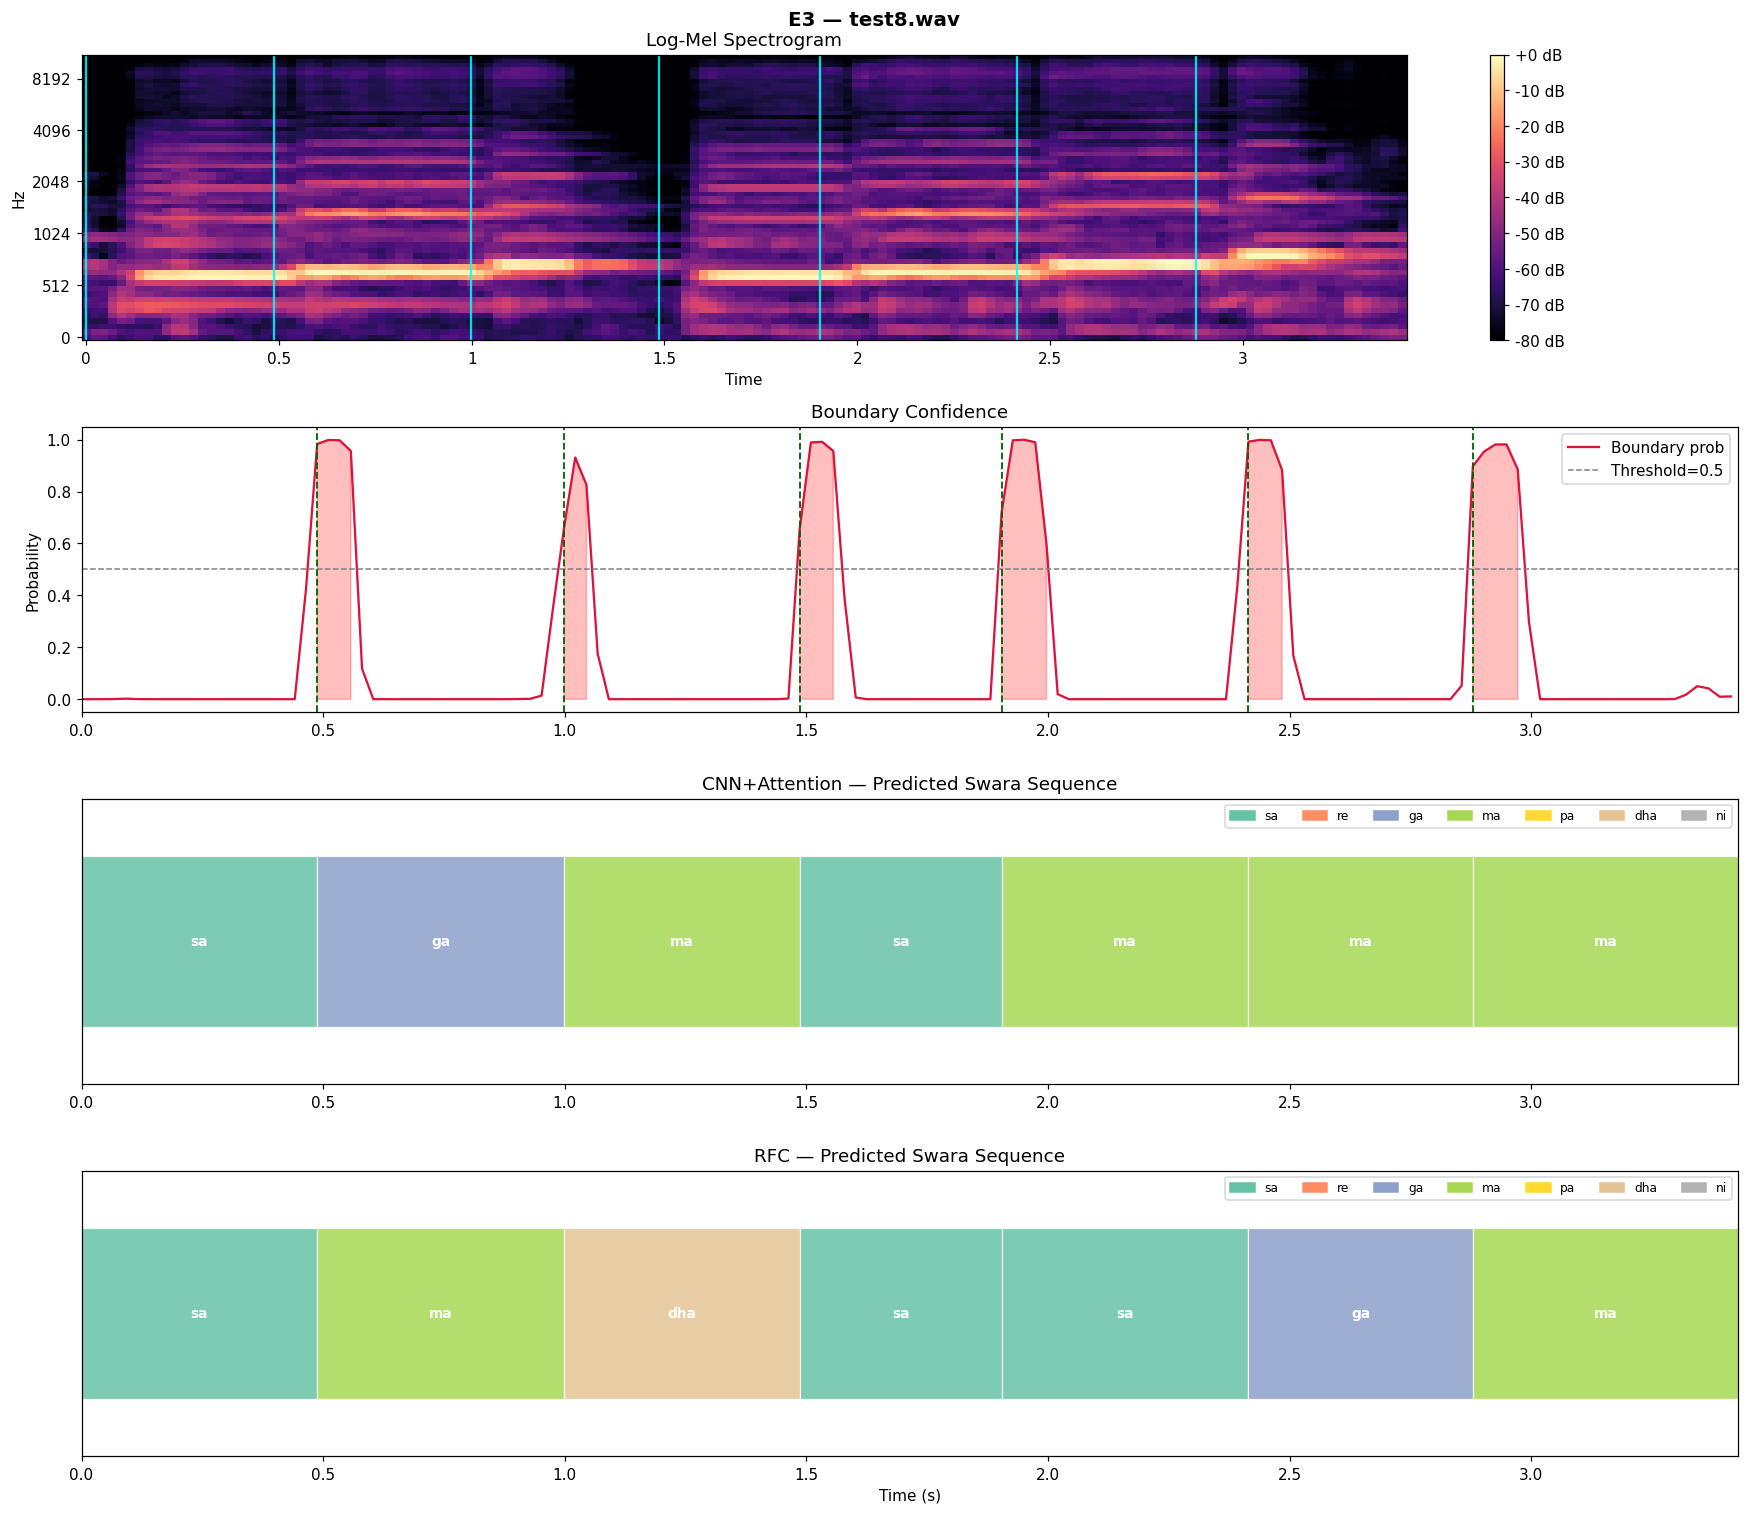

Processing files:  42%|████▏     | 8/19 [00:17<00:24,  2.18s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test9.wav
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 16.85it/s]

  Seg 01  [0.000s – 0.511s]  CNN=sa  RFC=pa
  Seg 02  [0.511s – 0.952s]  CNN=ni  RFC=ni



Classifying segments:  57%|█████▋    | 4/7 [00:00<00:00, 15.50it/s]

  Seg 03  [0.952s – 1.556s]  CNN=sa  RFC=sa
  Seg 04  [1.556s – 1.881s]  CNN=ma  RFC=ga



Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00, 15.80it/s]

  Seg 05  [1.881s – 2.392s]  CNN=ma  RFC=dha
  Seg 06  [2.392s – 2.902s]  CNN=ma  RFC=ni


Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 15.87it/s]


  Seg 07  [2.902s – 3.386s]  CNN=ma  RFC=ga

CNN+Attention : sa → ni → sa → ma → ma → ma → ma
RFC           : pa → ni → sa → ga → dha → ni → ga


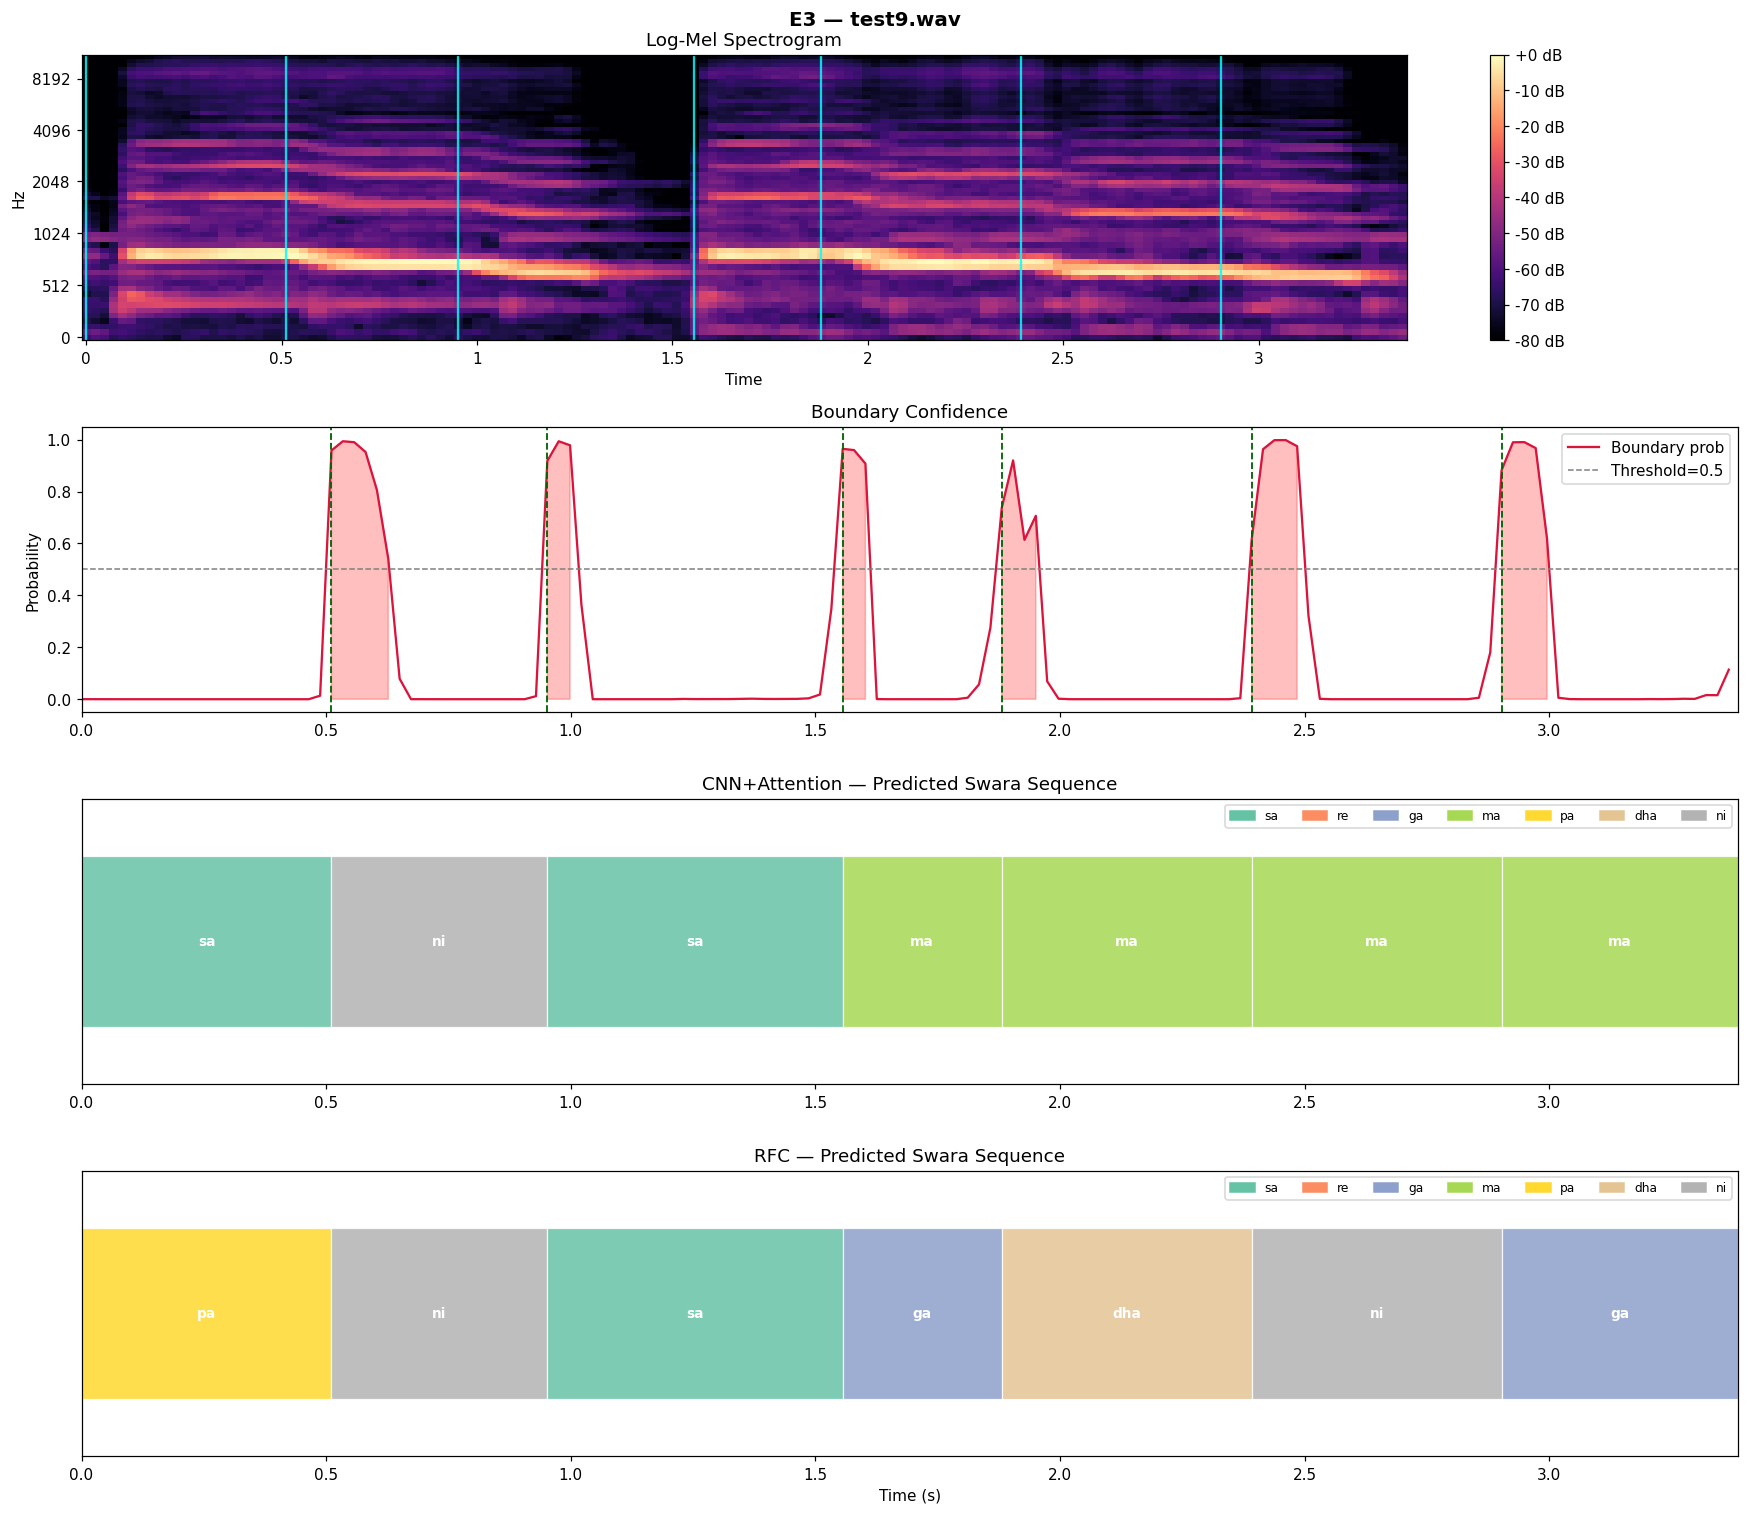

Processing files:  47%|████▋     | 9/19 [00:19<00:20,  2.08s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test10.wav
Boundaries detected: 7
  [Edge] Dropping short segment [0.000–0.163]s
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 15.83it/s]

  Seg 01  [0.163s – 0.534s]  CNN=ga  RFC=dha
  Seg 02  [0.534s – 1.022s]  CNN=ni  RFC=ni



Classifying segments:  57%|█████▋    | 4/7 [00:00<00:00, 16.28it/s]

  Seg 03  [1.022s – 1.602s]  CNN=ma  RFC=sa
  Seg 04  [1.602s – 1.997s]  CNN=sa  RFC=pa



Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00, 15.79it/s]

  Seg 05  [1.997s – 2.485s]  CNN=ni  RFC=ni
  Seg 06  [2.485s – 2.972s]  CNN=ni  RFC=ni


Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 15.94it/s]


  Seg 07  [2.972s – 3.489s]  CNN=ma  RFC=ma

CNN+Attention : ga → ni → ma → sa → ni → ni → ma
RFC           : dha → ni → sa → pa → ni → ni → ma


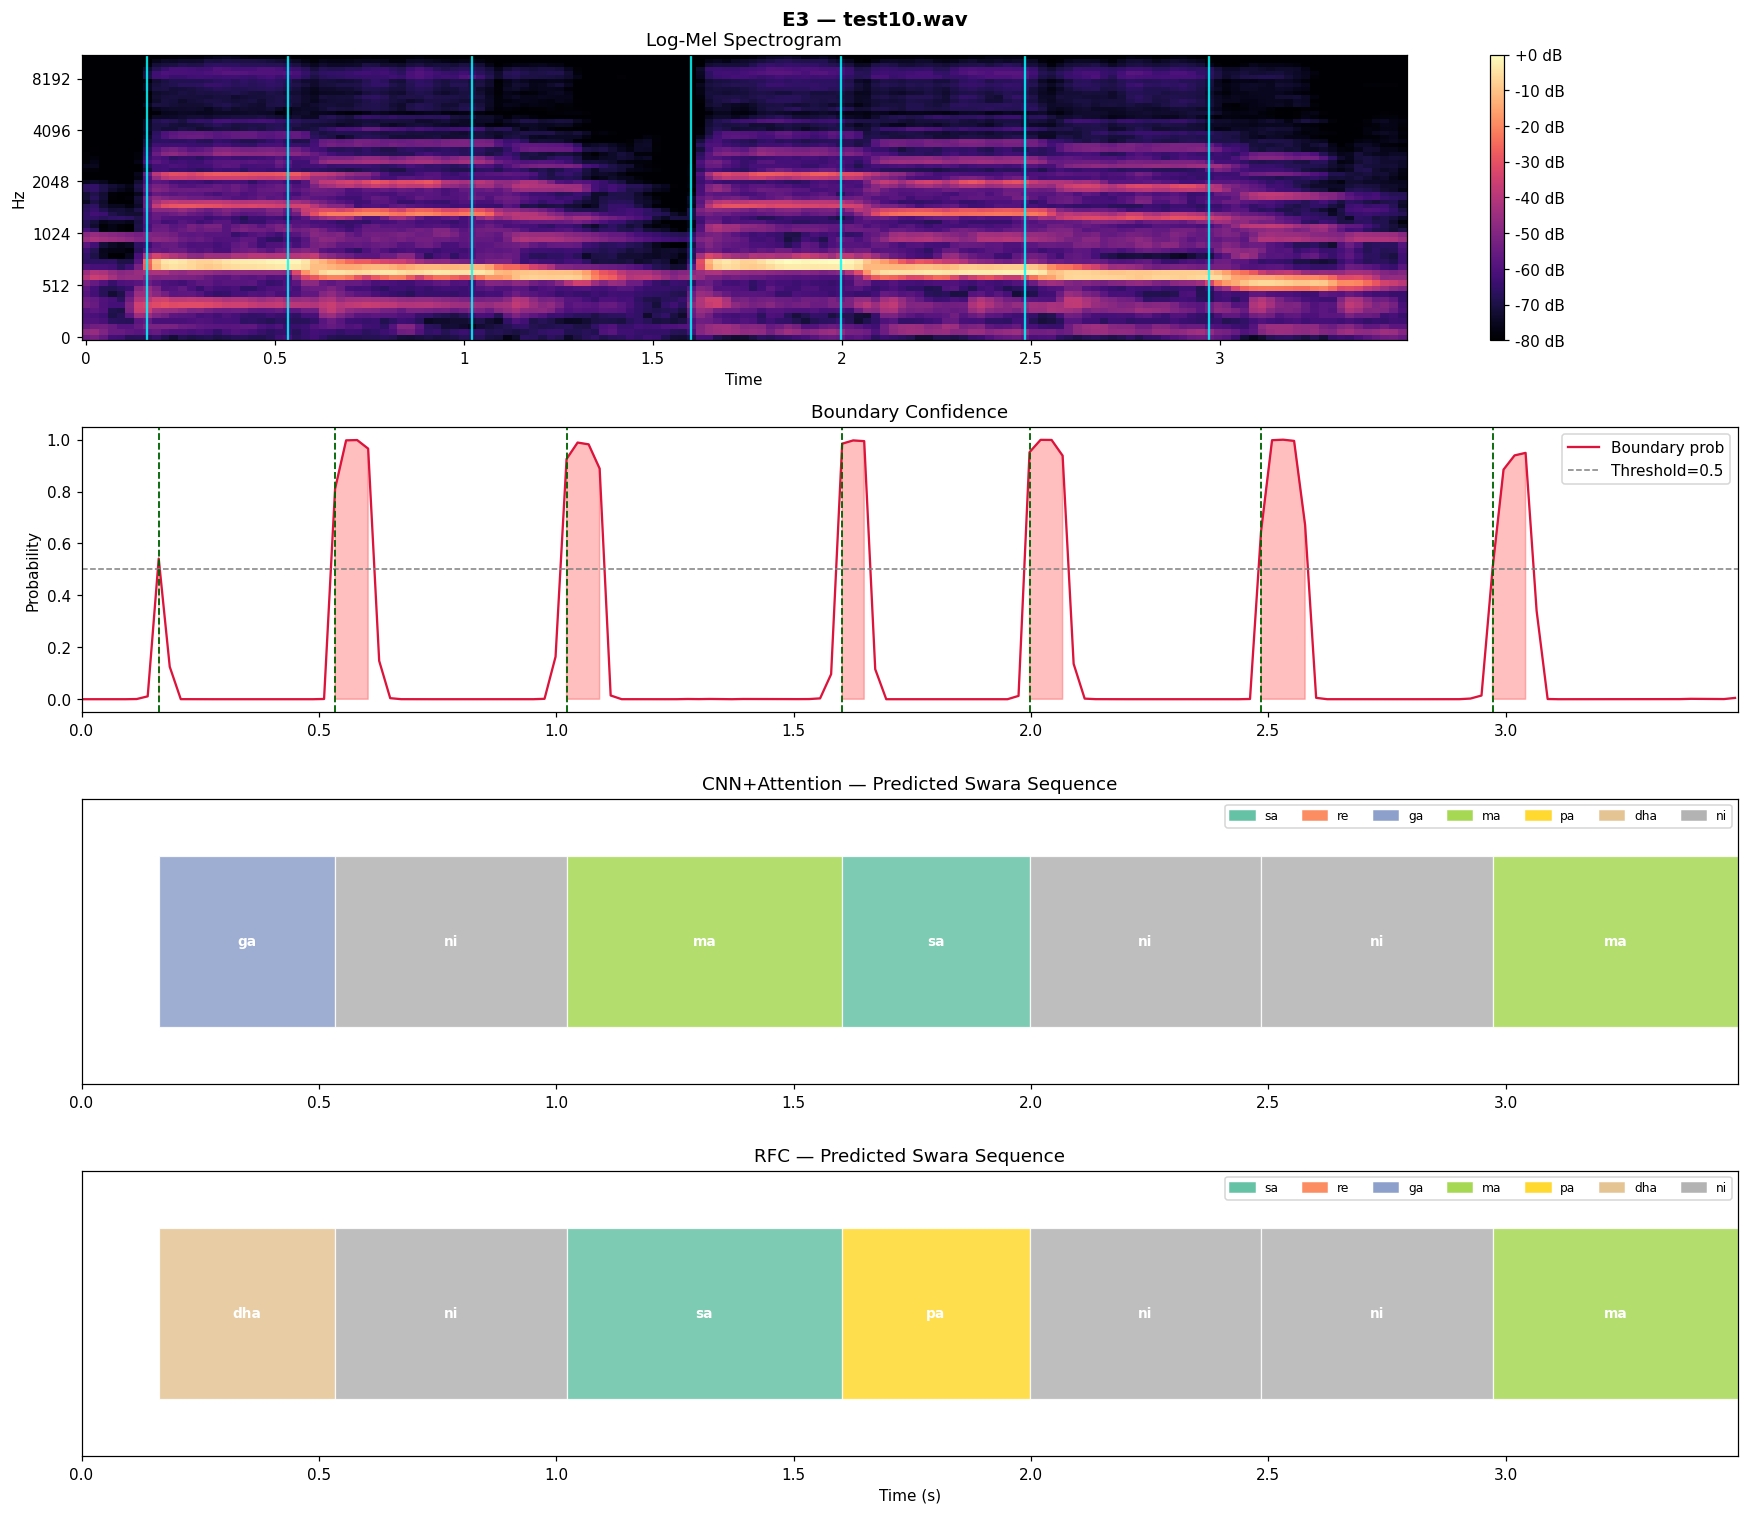

Processing files:  53%|█████▎    | 10/19 [00:21<00:18,  2.04s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test11.wav
  [Edge] Dropping last boundary at 3.320s
Boundaries detected: 4
Classifying 5 segments...



Classifying segments:  40%|████      | 2/5 [00:00<00:00, 15.18it/s]

  Seg 01  [0.000s – 0.488s]  CNN=sa  RFC=pa
  Seg 02  [0.488s – 0.929s]  CNN=ni  RFC=ma



Classifying segments:  80%|████████  | 4/5 [00:00<00:00, 15.28it/s]

  Seg 03  [0.929s – 1.509s]  CNN=ma  RFC=ma
  Seg 04  [1.509s – 2.438s]  CNN=sa  RFC=ga


Classifying segments: 100%|██████████| 5/5 [00:00<00:00, 15.00it/s]

  Seg 05  [2.438s – 3.404s]  CNN=ma  RFC=ma

CNN+Attention : sa → ni → ma → sa → ma
RFC           : pa → ma → ma → ga → ma


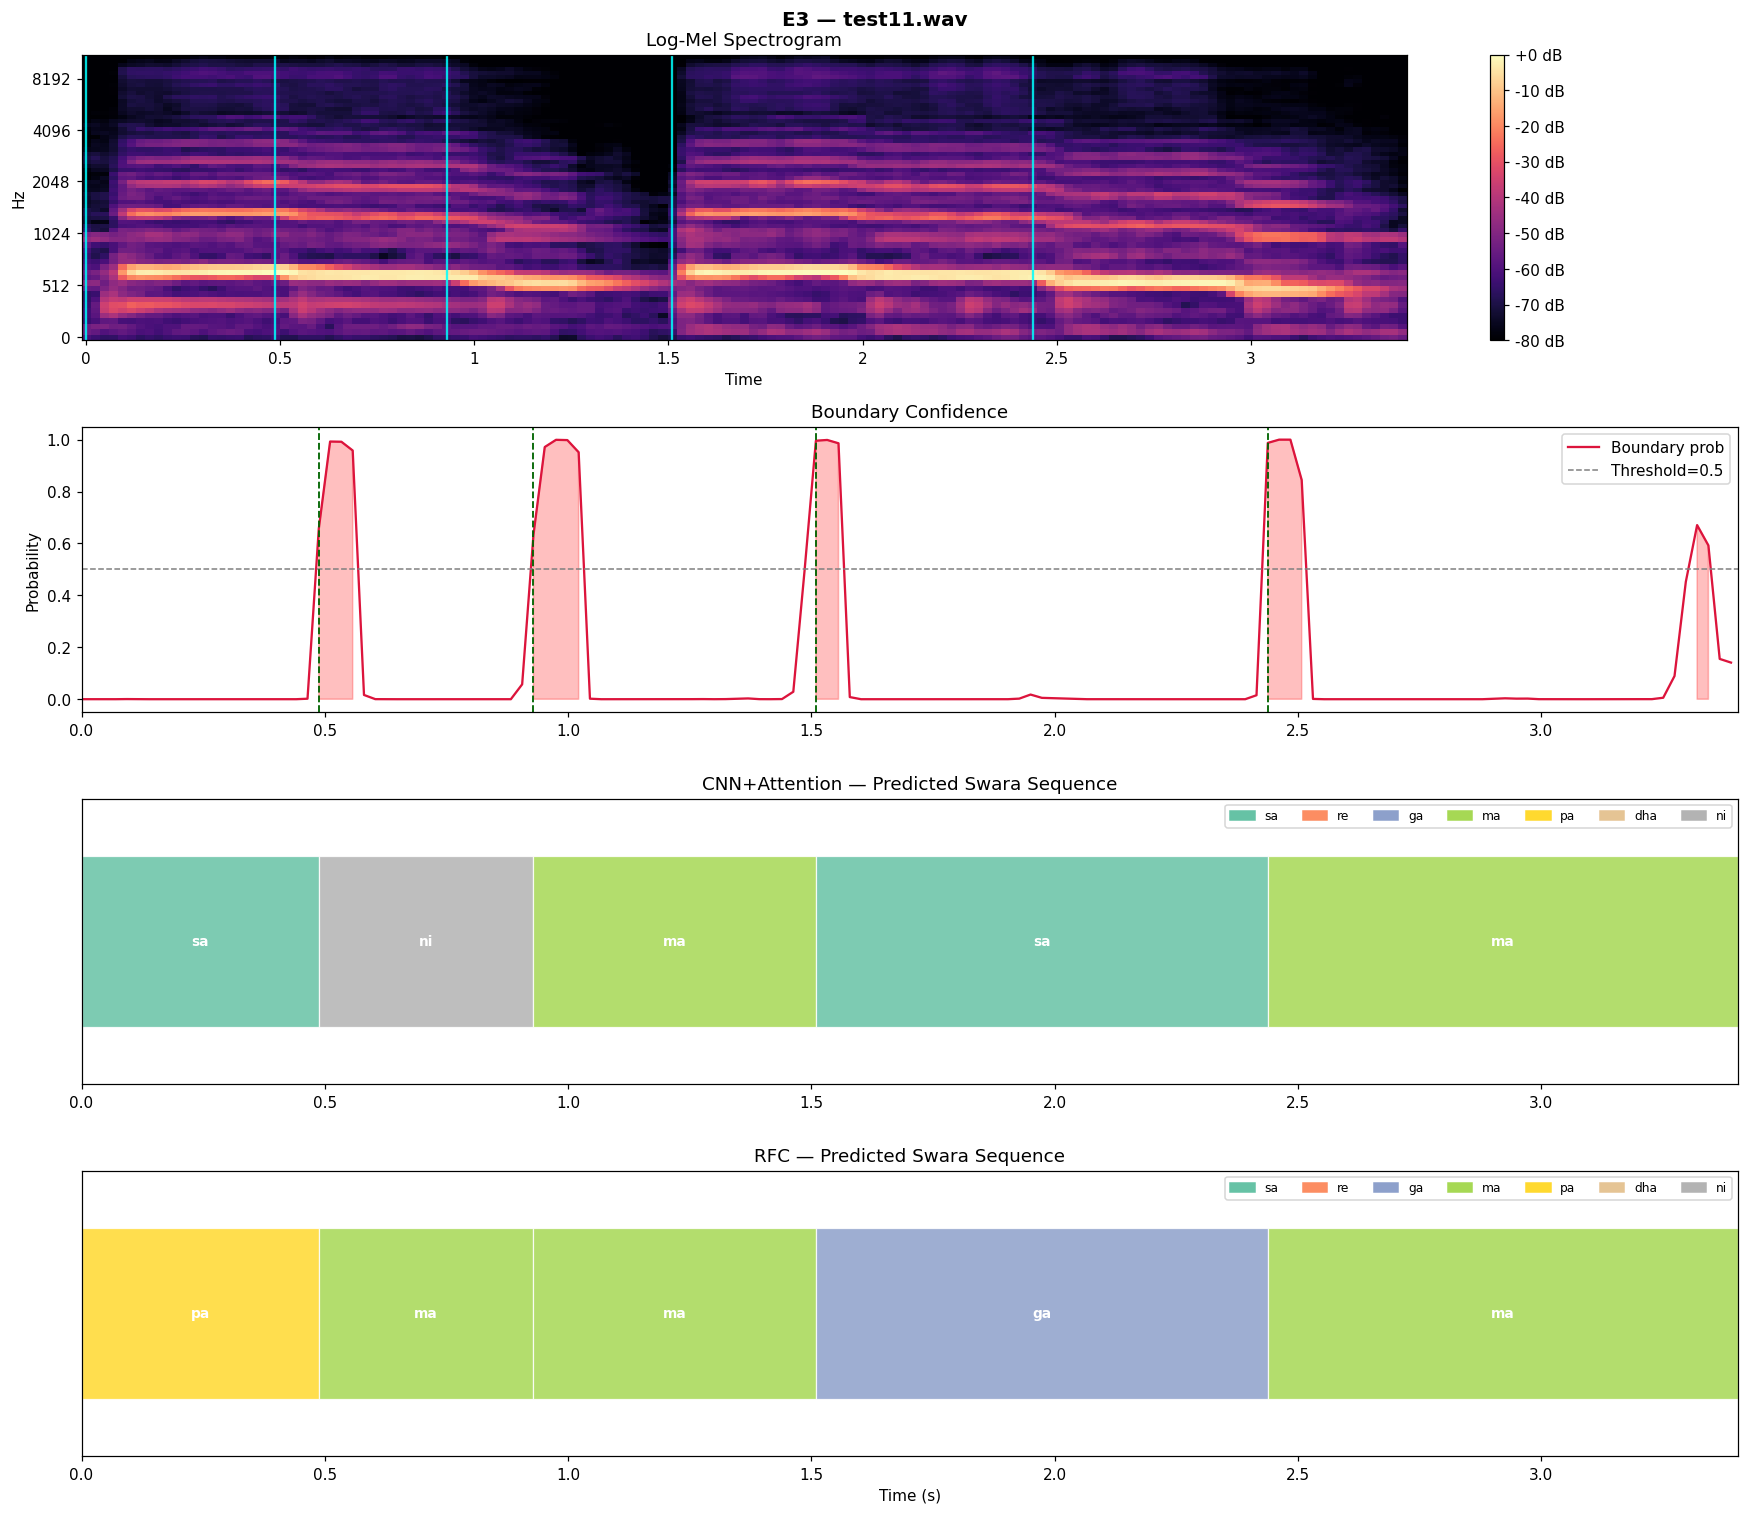

Processing files:  58%|█████▊    | 11/19 [00:23<00:15,  1.98s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test12.wav
Boundaries detected: 4
Classifying 5 segments...



Classifying segments:  40%|████      | 2/5 [00:00<00:00, 11.49it/s]

  Seg 01  [0.000s – 1.509s]  CNN=sa  RFC=dha
  Seg 02  [1.509s – 1.974s]  CNN=sa  RFC=sa
  Seg 03  [1.974s – 2.461s]  CNN=ma  RFC=ma



Classifying segments:  80%|████████  | 4/5 [00:00<00:00, 10.42it/s]

  Seg 04  [2.461s – 2.926s]  CNN=ni  RFC=ma


Classifying segments: 100%|██████████| 5/5 [00:00<00:00, 10.51it/s]

  Seg 05  [2.926s – 3.348s]  CNN=ma  RFC=ga

CNN+Attention : sa → sa → ma → ni → ma
RFC           : dha → sa → ma → ma → ga


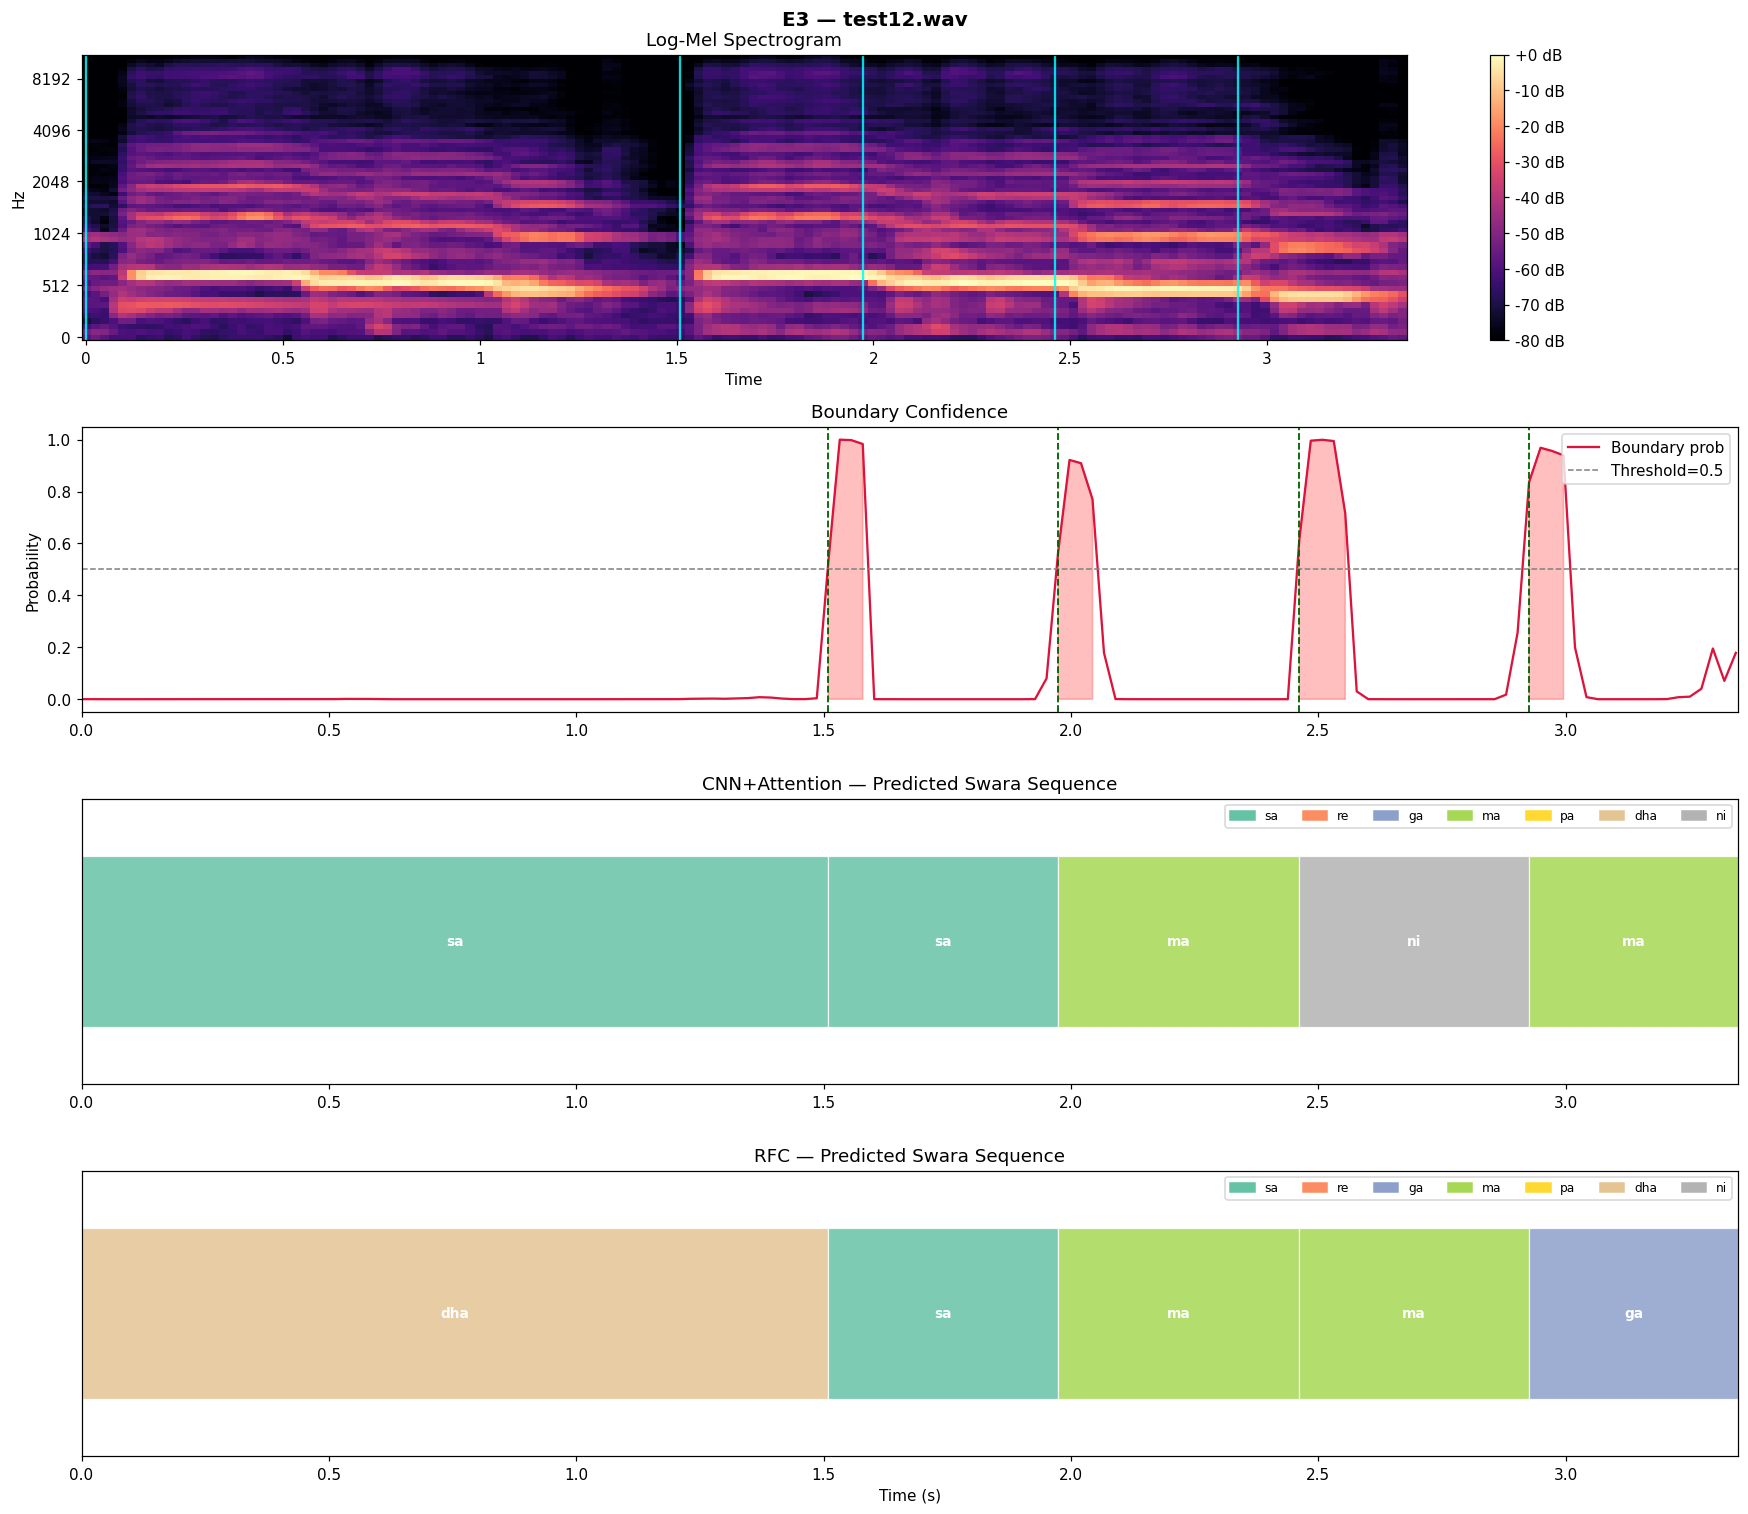

Processing files:  63%|██████▎   | 12/19 [00:25<00:15,  2.19s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test13.wav
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 12.48it/s]

  Seg 01  [0.000s – 0.534s]  CNN=sa  RFC=sa
  Seg 02  [0.534s – 0.952s]  CNN=ni  RFC=ma



Classifying segments:  57%|█████▋    | 4/7 [00:00<00:00, 10.46it/s]

  Seg 03  [0.952s – 1.556s]  CNN=ma  RFC=pa
  Seg 04  [1.556s – 1.997s]  CNN=sa  RFC=sa
  Seg 05  [1.997s – 2.461s]  CNN=ni  RFC=ma



Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 10.81it/s]

  Seg 06  [2.461s – 2.972s]  CNN=ga  RFC=ga
  Seg 07  [2.972s – 3.414s]  CNN=ma  RFC=ma

CNN+Attention : sa → ni → ma → sa → ni → ga → ma
RFC           : sa → ma → pa → sa → ma → ga → ma


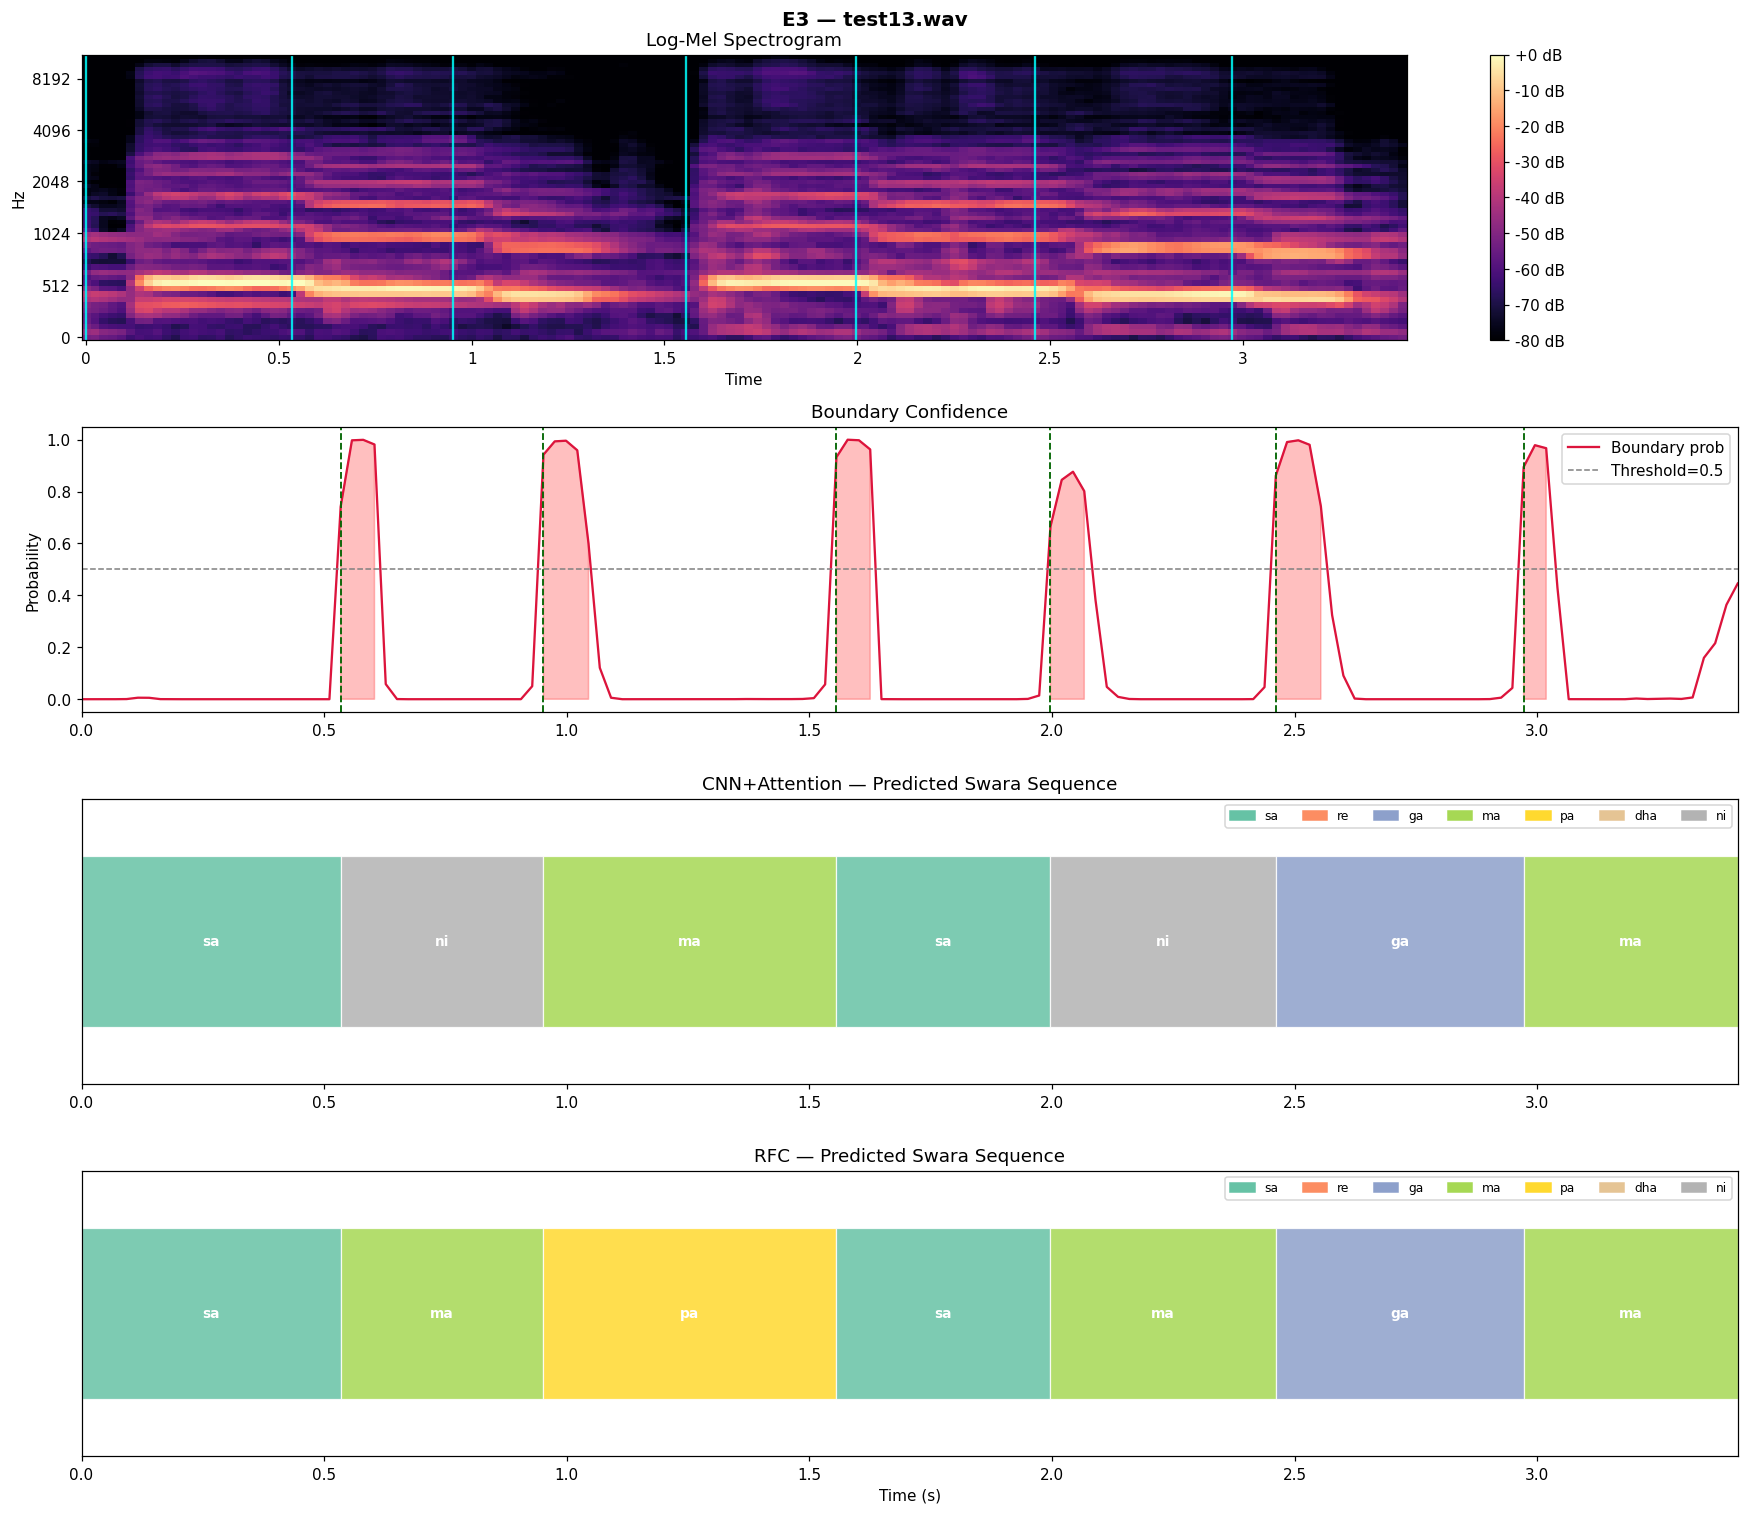

Processing files:  68%|██████▊   | 13/19 [00:28<00:14,  2.35s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test14.wav
  [Edge] Dropping last boundary at 3.320s
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 16.75it/s]

  Seg 01  [0.000s – 0.488s]  CNN=pa  RFC=sa
  Seg 02  [0.488s – 0.998s]  CNN=ni  RFC=ni
  Seg 03  [0.998s – 1.463s]  CNN=sa  RFC=ma



Classifying segments:  57%|█████▋    | 4/7 [00:00<00:00, 16.52it/s]

  Seg 04  [1.463s – 1.927s]  CNN=sa  RFC=sa



Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00, 15.41it/s]

  Seg 05  [1.927s – 2.485s]  CNN=ma  RFC=ni
  Seg 06  [2.485s – 2.949s]  CNN=ni  RFC=ma


Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 15.20it/s]

  Seg 07  [2.949s – 3.423s]  CNN=ma  RFC=ni

CNN+Attention : pa → ni → sa → sa → ma → ni → ma
RFC           : sa → ni → ma → sa → ni → ma → ni


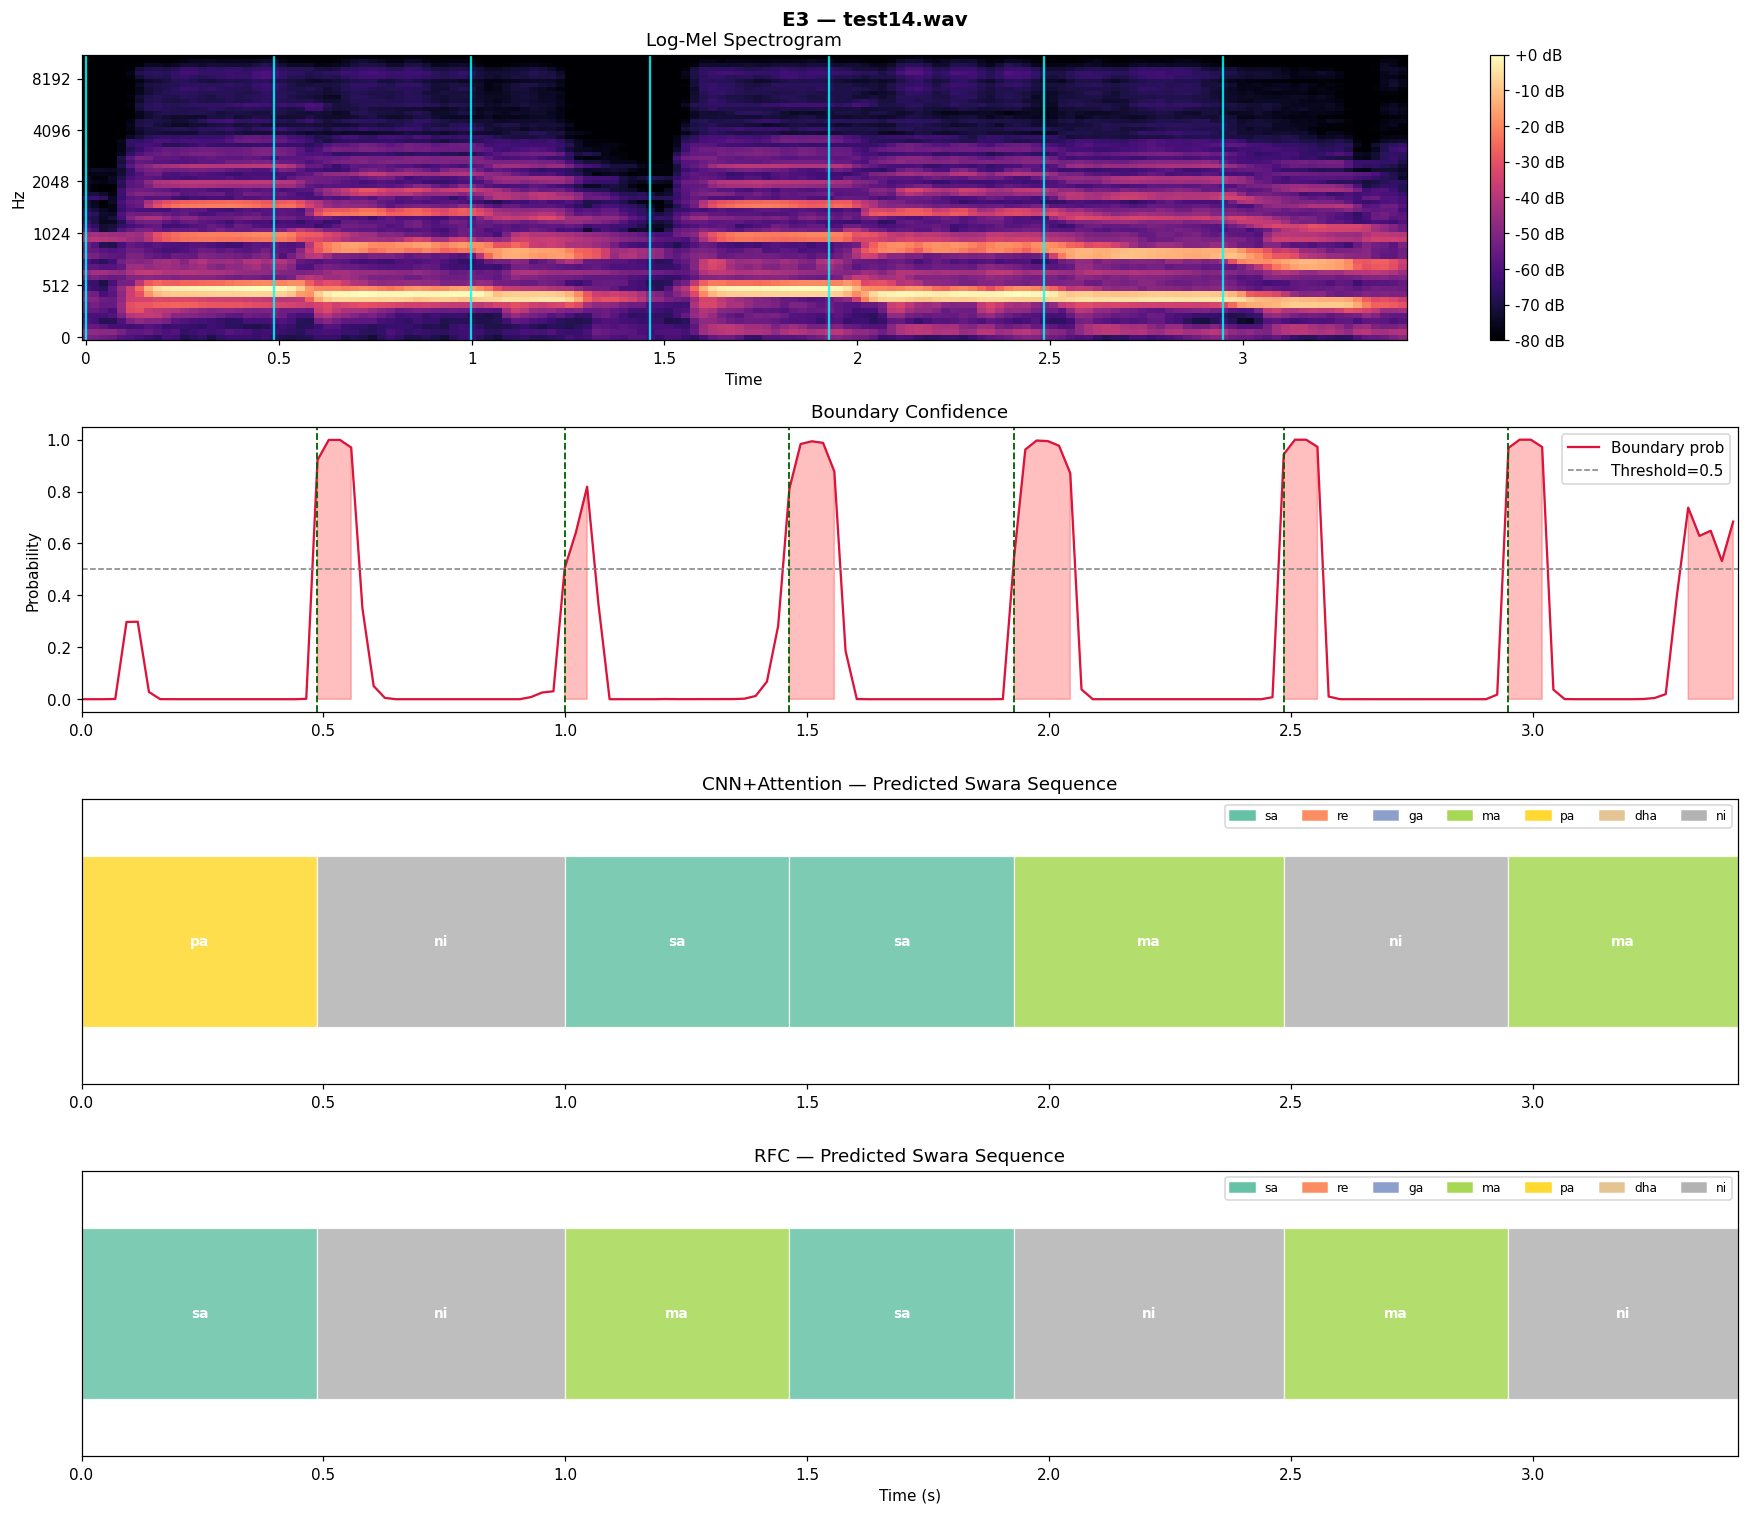

Processing files:  74%|███████▎  | 14/19 [00:30<00:11,  2.27s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test15.wav
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 17.27it/s]

  Seg 01  [0.000s – 0.488s]  CNN=sa  RFC=sa
  Seg 02  [0.488s – 0.929s]  CNN=ma  RFC=ma
  Seg 03  [0.929s – 1.486s]  CNN=sa  RFC=pa



Classifying segments:  57%|█████▋    | 4/7 [00:00<00:00, 16.75it/s]

  Seg 04  [1.486s – 1.927s]  CNN=sa  RFC=sa



Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00, 16.06it/s]

  Seg 05  [1.927s – 2.485s]  CNN=ni  RFC=ni
  Seg 06  [2.485s – 2.926s]  CNN=ma  RFC=ni


Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 15.82it/s]

  Seg 07  [2.926s – 3.414s]  CNN=ma  RFC=sa

CNN+Attention : sa → ma → sa → sa → ni → ma → ma
RFC           : sa → ma → pa → sa → ni → ni → sa


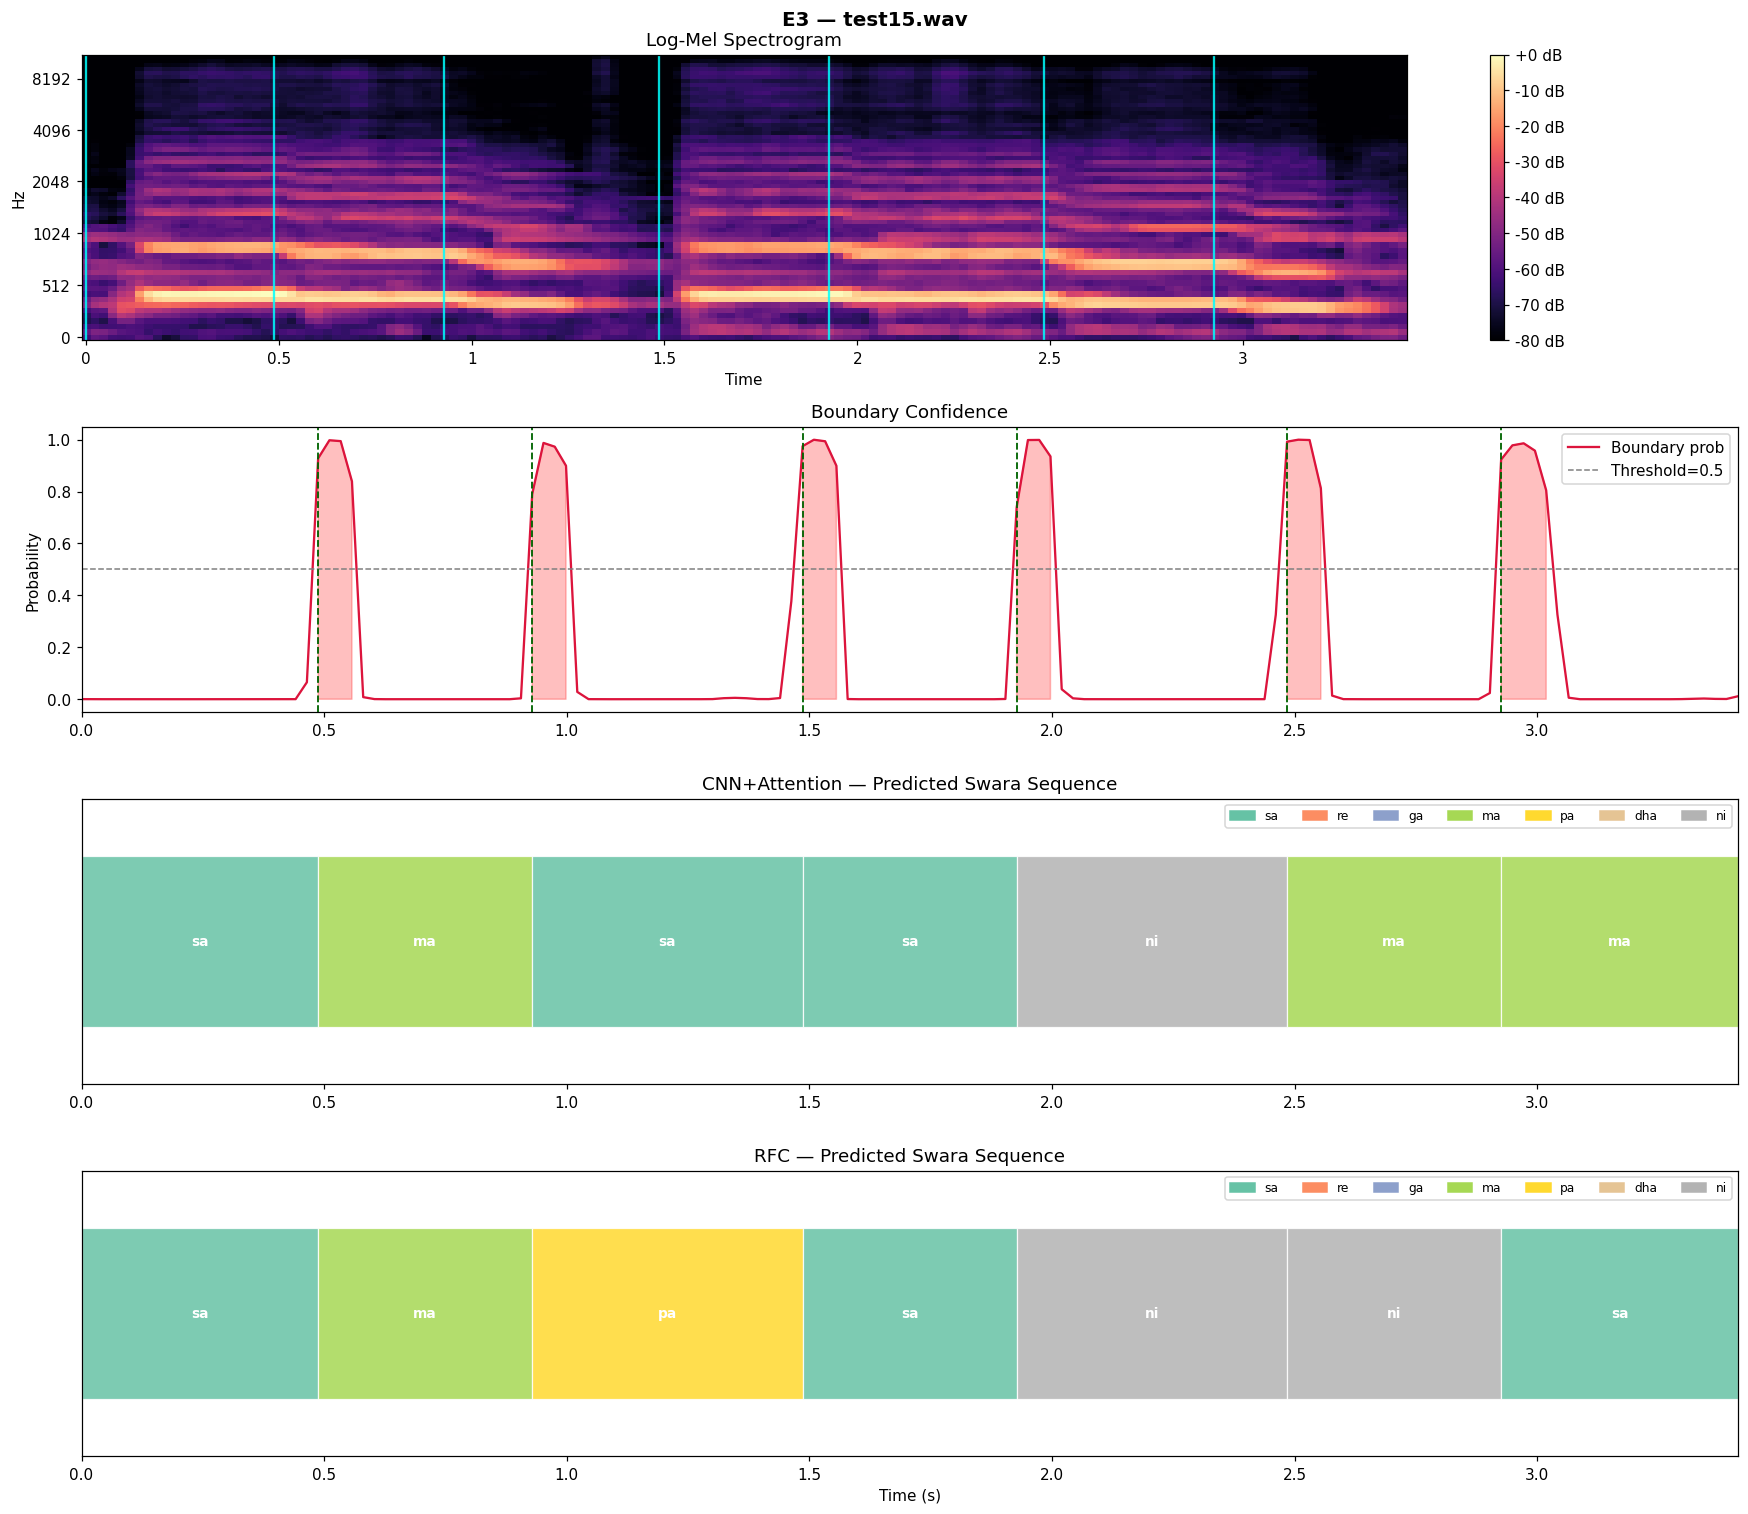

Processing files:  79%|███████▉  | 15/19 [00:32<00:08,  2.19s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test16.wav
  [Edge] Dropping last boundary at 3.297s
Boundaries detected: 7
  [Edge] Dropping short segment [1.393–1.556]s
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 14.95it/s]

  Seg 01  [0.000s – 0.488s]  CNN=pa  RFC=sa
  Seg 02  [0.488s – 0.975s]  CNN=ga  RFC=ma
  Seg 03  [0.975s – 1.393s]  CNN=ma  RFC=ma



Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00, 15.08it/s]

  Seg 04  [1.556s – 1.950s]  CNN=sa  RFC=sa
  Seg 05  [1.950s – 2.415s]  CNN=ga  RFC=ni
  Seg 06  [2.415s – 2.902s]  CNN=ni  RFC=ni


Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 14.94it/s]


  Seg 07  [2.902s – 3.386s]  CNN=ma  RFC=sa

CNN+Attention : pa → ga → ma → sa → ga → ni → ma
RFC           : sa → ma → ma → sa → ni → ni → sa


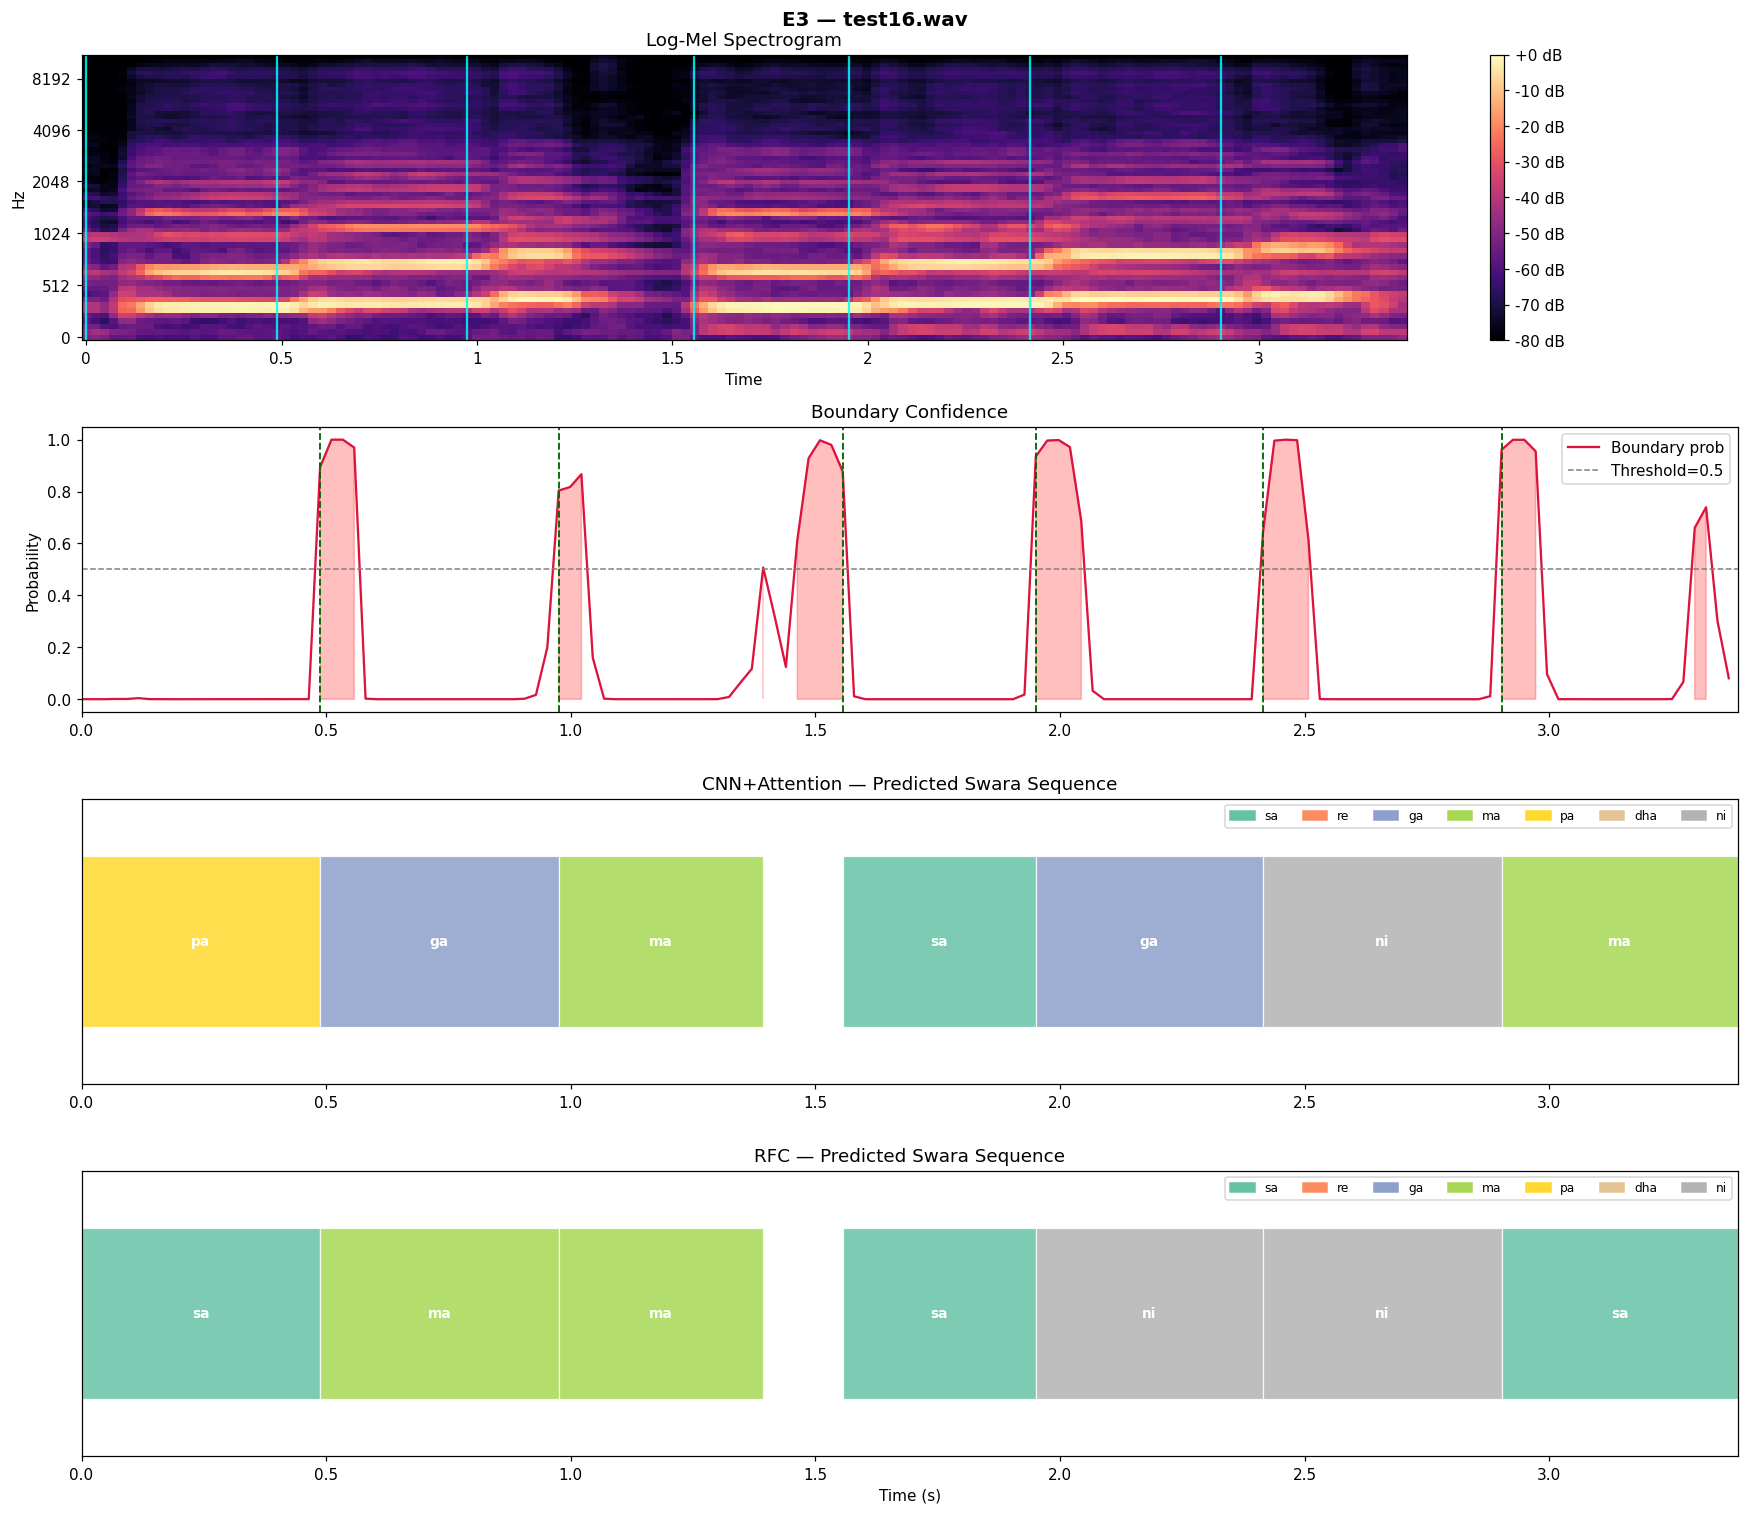

Processing files:  84%|████████▍ | 16/19 [00:34<00:06,  2.16s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test17.wav
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 15.21it/s]

  Seg 01  [0.000s – 0.511s]  CNN=pa  RFC=sa
  Seg 02  [0.511s – 1.022s]  CNN=re  RFC=ma



Classifying segments:  57%|█████▋    | 4/7 [00:00<00:00, 15.91it/s]

  Seg 03  [1.022s – 1.533s]  CNN=sa  RFC=ma
  Seg 04  [1.533s – 1.974s]  CNN=sa  RFC=pa



Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00, 16.12it/s]

  Seg 05  [1.974s – 2.438s]  CNN=ma  RFC=ma
  Seg 06  [2.438s – 2.995s]  CNN=ni  RFC=ni


Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 15.95it/s]


  Seg 07  [2.995s – 3.475s]  CNN=ma  RFC=ma

CNN+Attention : pa → re → sa → sa → ma → ni → ma
RFC           : sa → ma → ma → pa → ma → ni → ma


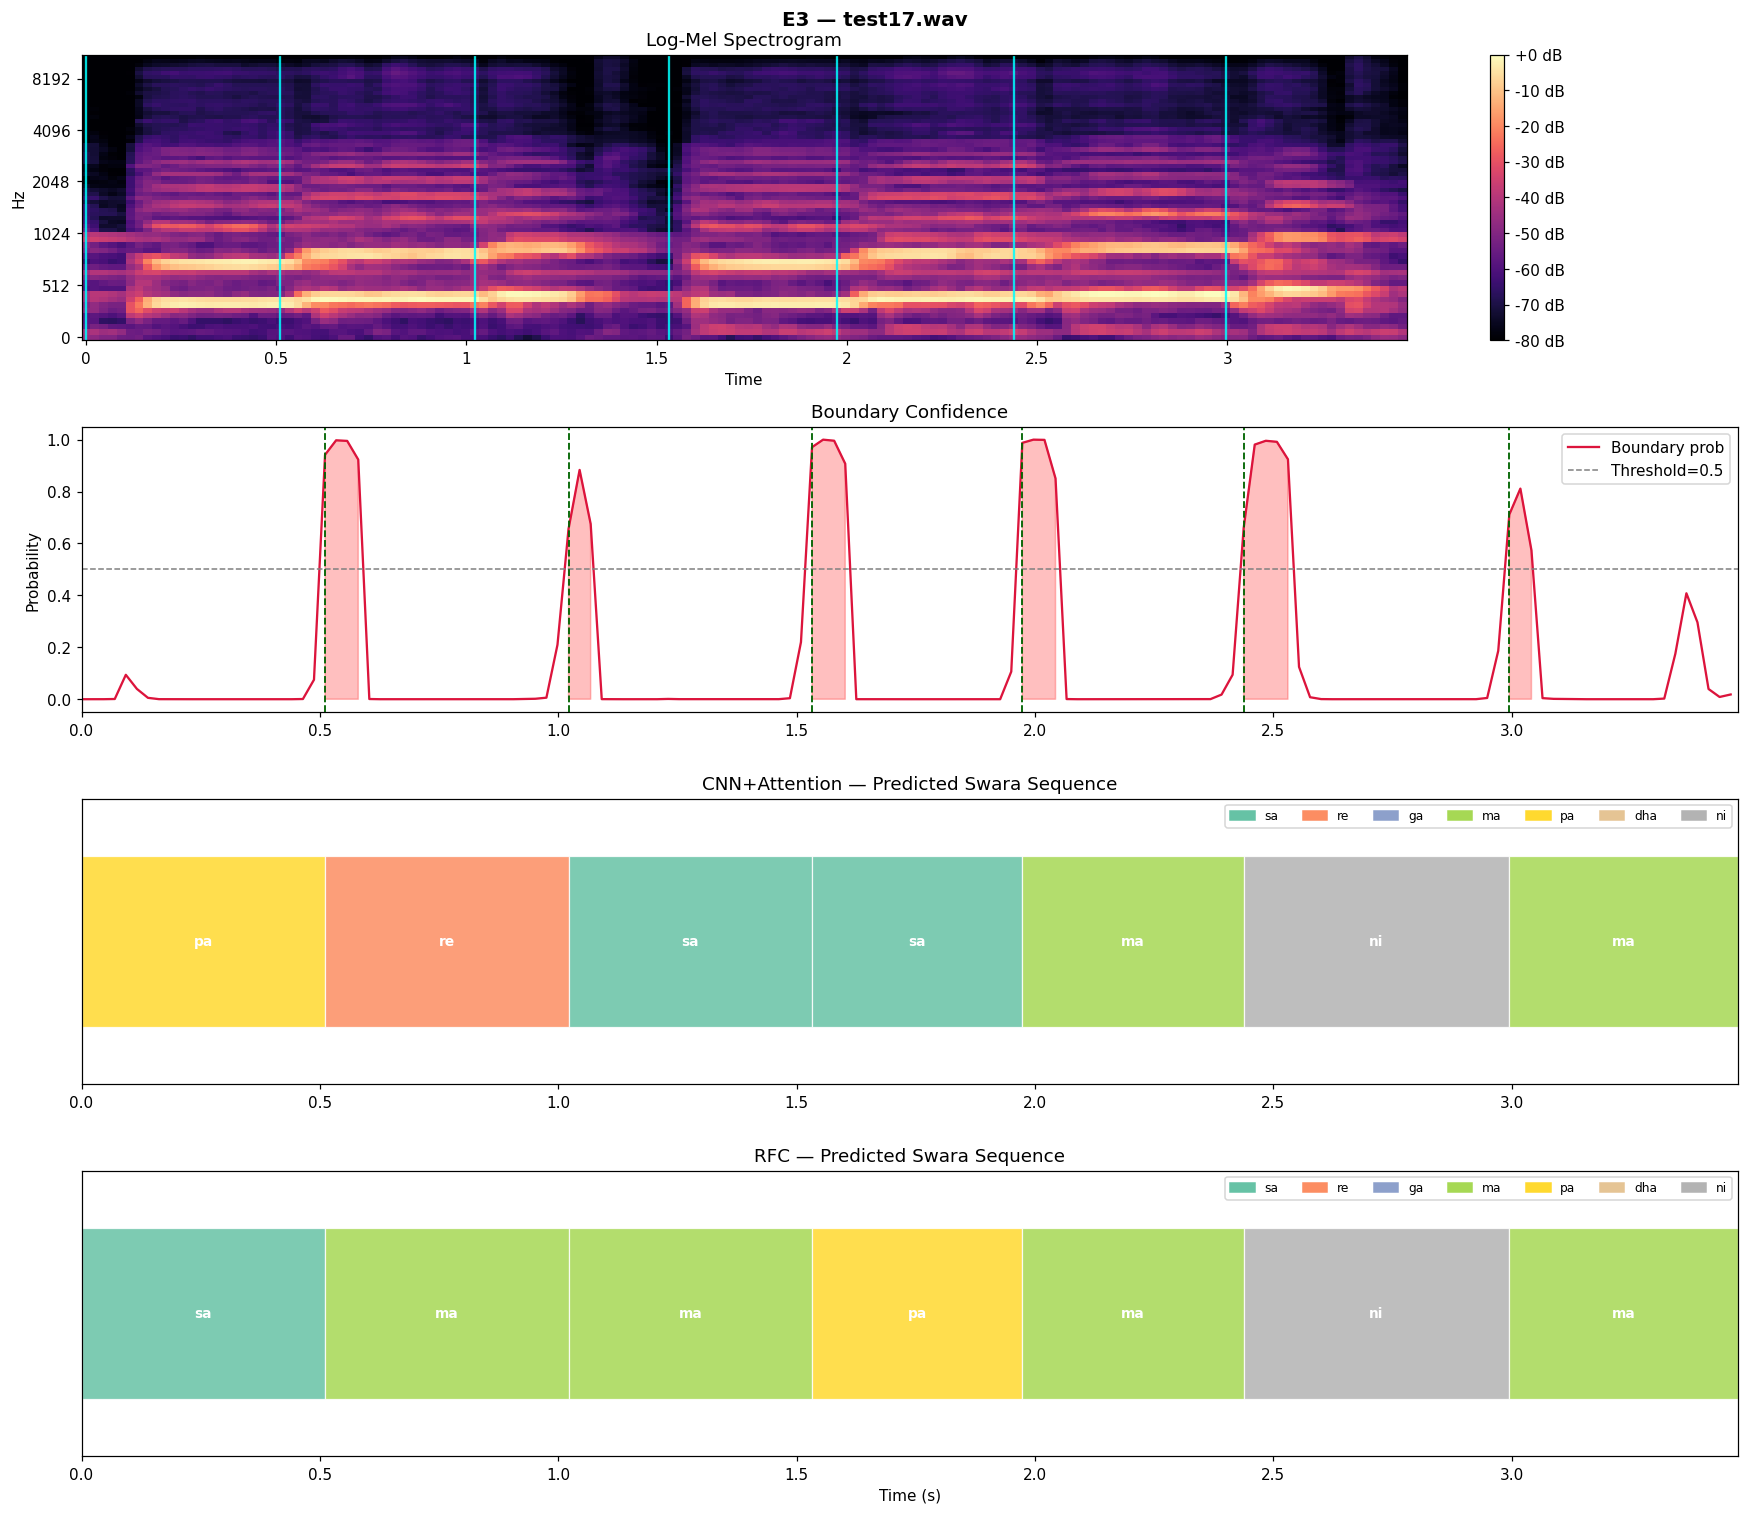

Processing files:  89%|████████▉ | 17/19 [00:37<00:04,  2.23s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test18.wav
Boundaries detected: 5
Classifying 6 segments...



Classifying segments:  33%|███▎      | 2/6 [00:00<00:00, 16.75it/s]

  Seg 01  [0.000s – 0.534s]  CNN=sa  RFC=sa
  Seg 02  [0.534s – 1.440s]  CNN=sa  RFC=ma
  Seg 03  [1.440s – 1.997s]  CNN=sa  RFC=sa



Classifying segments:  67%|██████▋   | 4/6 [00:00<00:00, 16.39it/s]

  Seg 04  [1.997s – 2.508s]  CNN=re  RFC=dha



Classifying segments: 100%|██████████| 6/6 [00:00<00:00, 15.25it/s]

  Seg 05  [2.508s – 2.972s]  CNN=ni  RFC=ni
  Seg 06  [2.972s – 3.470s]  CNN=ma  RFC=pa

CNN+Attention : sa → sa → sa → re → ni → ma
RFC           : sa → ma → sa → dha → ni → pa


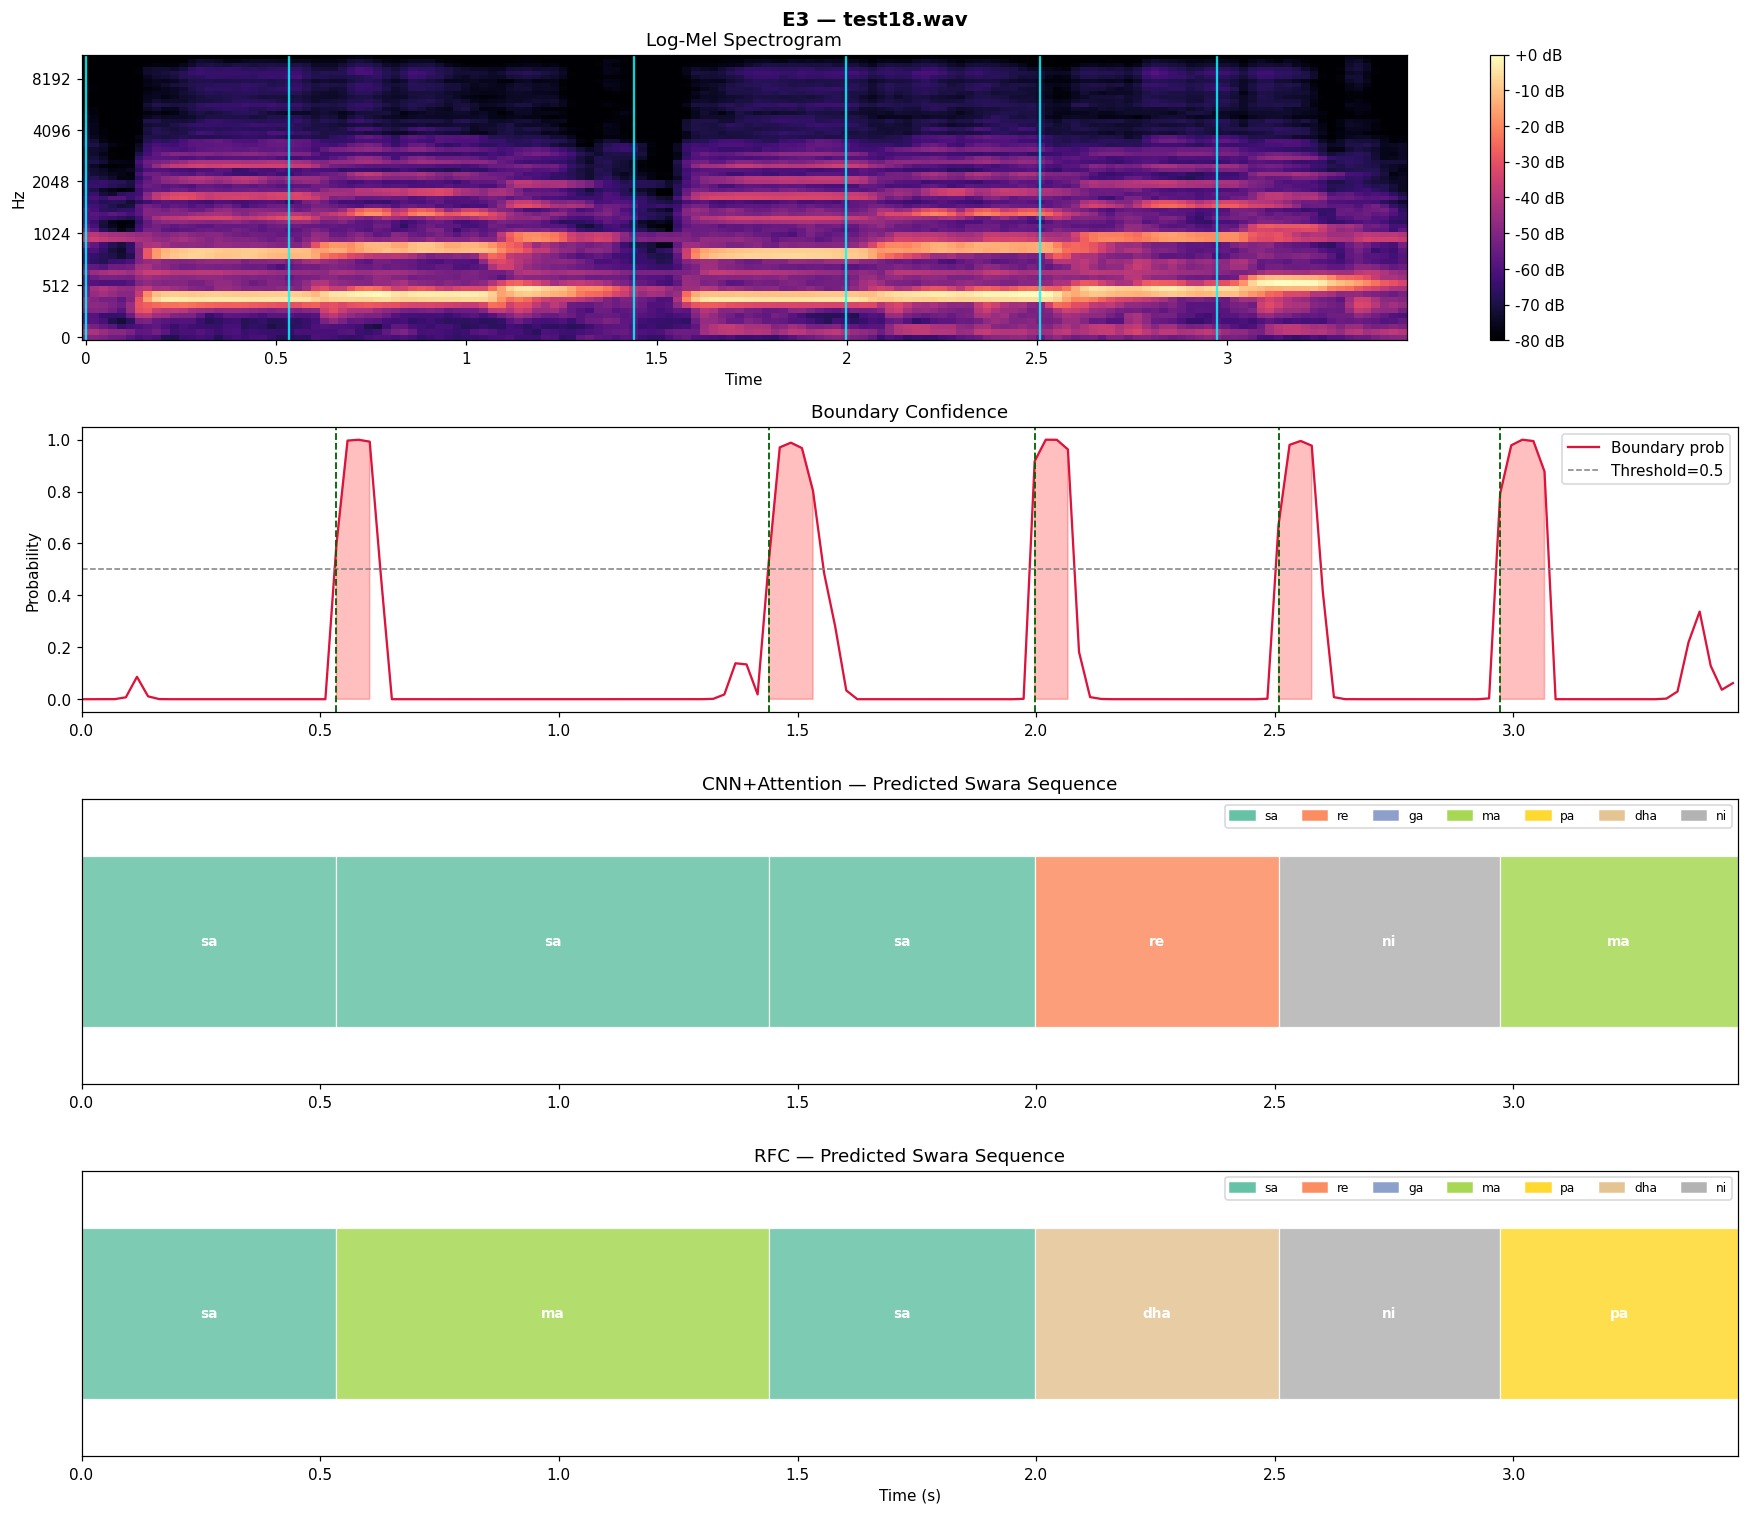

Processing files:  95%|█████████▍| 18/19 [00:39<00:02,  2.32s/it]

Saved visualization → /content/E3_pipeline_output.png

Processing: test19.wav
  [Edge] Dropping last boundary at 3.251s
Boundaries detected: 5
Classifying 6 segments...



Classifying segments:  17%|█▋        | 1/6 [00:00<00:00,  6.91it/s]

  Seg 01  [0.000s – 0.488s]  CNN=sa  RFC=pa



Classifying segments:  33%|███▎      | 2/6 [00:00<00:00,  7.69it/s]

  Seg 02  [0.488s – 1.486s]  CNN=sa  RFC=pa


... (2 outputs left out)


Classifying segments:  67%|██████▋   | 4/6 [00:00<00:00,  8.29it/s]

  Seg 04  [1.950s – 2.438s]  CNN=ma  RFC=ga



Classifying segments: 100%|██████████| 6/6 [00:00<00:00,  8.85it/s]

  Seg 05  [2.438s – 2.856s]  CNN=ni  RFC=ga
  Seg 06  [2.856s – 3.357s]  CNN=ma  RFC=pa

CNN+Attention : sa → sa → sa → ma → ni → ma
RFC           : pa → pa → sa → ga → ga → pa


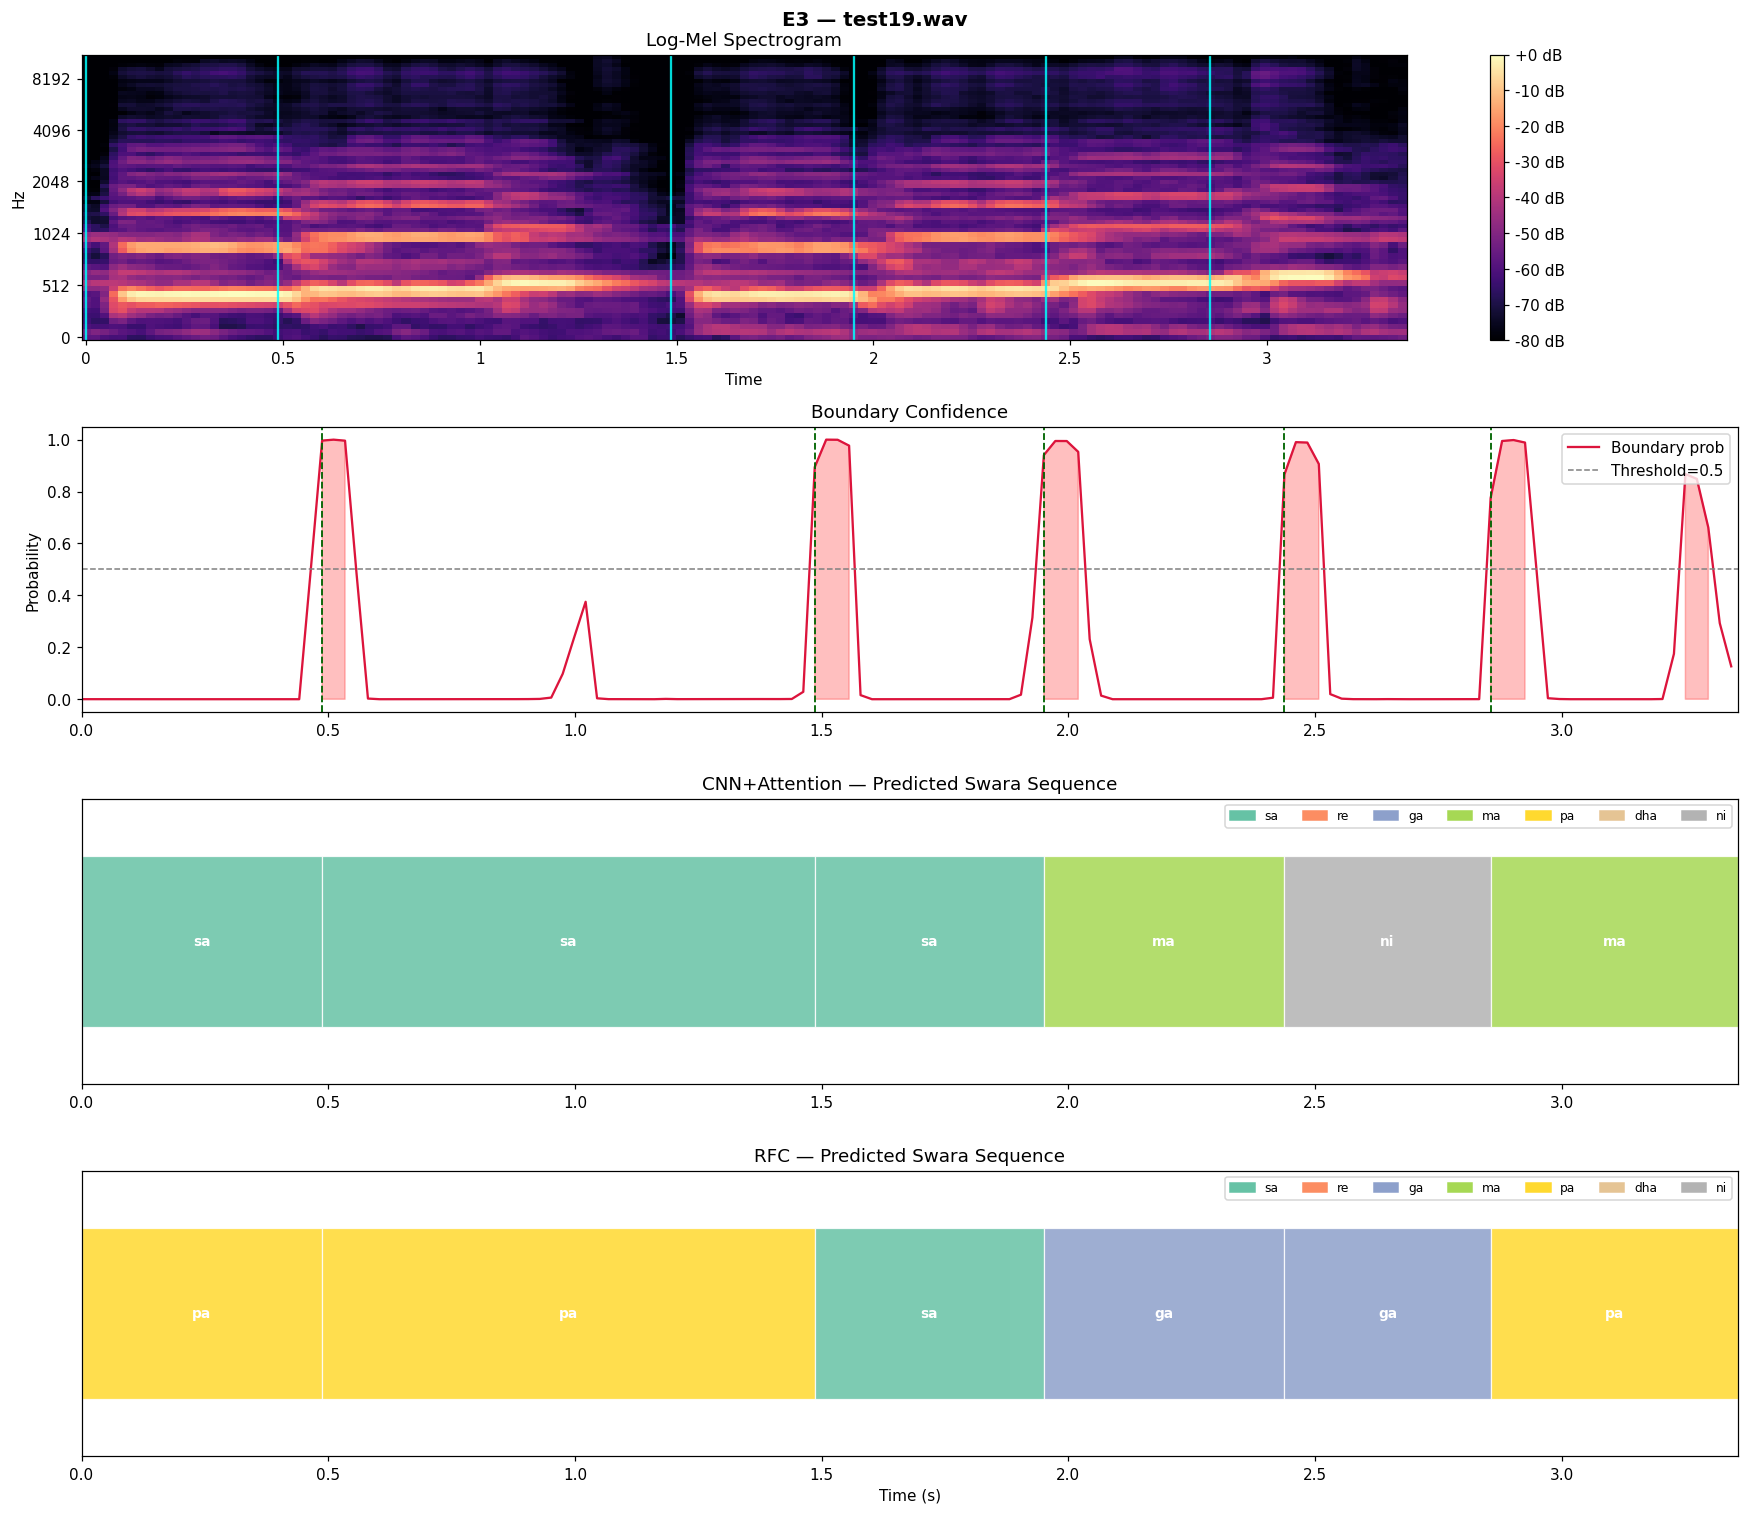

Processing files: 100%|██████████| 19/19 [00:42<00:00,  2.25s/it]

Saved visualization → /content/E3_pipeline_output.png

experiment  clip_name  n_segments                                                   cnn_sequence                                                     rfc_sequence
        E3  test1.wav          13 pa → re → ma → sa → sa → re → pa → pa → ni → ni → ni → re → sa sa → re → dha → sa → dha → ga → sa → sa → ni → ma → ni → re → ga
        E3  test2.wav           7                               sa → ga → sa → sa → ga → ni → sa                                 pa → ga → sa → pa → ni → ni → ma
        E3  test3.wav           6                                    sa → ga → pa → ma → re → ma                                      pa → ni → pa → ni → ga → ma
        E3  test4.wav           6                                    sa → sa → sa → re → ma → sa                                     sa → sa → sa → re → re → dha
        E3  test5.wav           7                               sa → ni → sa → sa → ma → ma → ma                                sa → ga

In [16]:
from google.colab import files as colab_files

print("Upload one or more test flute .wav files:")
uploaded = colab_files.upload()

rows = []
for audio_file in tqdm(uploaded.keys(), desc="Processing files"):
    print(f"\n{'='*60}\nProcessing: {audio_file}\n{'='*60}")
    try:
        cnn_seq, rfc_seq, segs = run_pipeline(audio_file)
        rows.append({
            "experiment":   EXPERIMENT,
            "clip_name":    audio_file,
            "n_segments":   len(segs),
            "cnn_sequence": " → ".join(cnn_seq),
            "rfc_sequence": " → ".join(rfc_seq),
        })
    except Exception as e:
        print(f"  ERROR: {e}")
        rows.append({"experiment": EXPERIMENT, "clip_name": audio_file,
                     "n_segments": 0, "cnn_sequence": "ERROR", "rfc_sequence": "ERROR"})

results_df = pd.DataFrame(rows)
print("\n" + "="*60)
print(results_df.to_string(index=False))

csv_path = os.path.join(SAVE_DIR, f"{EXPERIMENT}_results.csv")
results_df.to_csv(csv_path, index=False)
print(f"\nSaved → {csv_path}")
